# Beyond Chunk Size: Chunking × Embedding × Retrieval Study for RAG
**Course:** Prompt Engineering and Optimization for Generative AI (UE24AM343AB5) — Mini Project, Problem Statement 6

A multi-domain empirical study of **chunking strategies**, **embedding models** and **retrieval pipelines** (dense → hybrid → hybrid + reranker), ending in a **decision matrix** and a small **Config Advisor** app.

### Hypotheses
1. **H1:** Structure-aware chunking beats fixed-size / semantic chunking on structured documents (API docs, legal text).
2. **H2:** A reranker narrows the performance gap between chunking strategies.
3. **H3:** Compressed embeddings (truncated / binary) lose little accuracy but save a lot of storage and latency.

### Pipeline (staged, so the grid stays small)
| Stage | What runs | LLM needed? |
|---|---|---|
| Gold set | LLM drafts questions with verbatim evidence → **you verify by hand** | Yes (one-off) |
| 1 | All chunkers × 1 fixed embedder (dense) | No |
| 2 | Top chunkers × all embedders (dense) | No |
| 3a | All chunkers × best embedder × {dense, hybrid, hybrid+rerank} → tests **H2** | No |
| 3b | Top (chunker, embedder) pairs × modes, with answer generation + groundedness | Yes |
| 4 | Efficiency: truncated dims, binary quantization, latency, index size → tests **H3** | No |
| Analysis | CIs, heatmaps, Pareto plot, decision matrix, provider cross-check, advisor app | – |

**Key design choice:** all retrieval metrics are computed from **character offsets**, so they are comparable across chunkers of any size (no LLM needed for retrieval metrics).

**LLM provider is a switchable option** (`PROVIDER = "gemini"`, `"openai"`, `"openrouter"`, `"zai"` or `"ollama"` for local models). Embeddings stay local (Hugging Face) by default.

## 0. Install
Run once. (On Colab/Kaggle this works as-is; restart the kernel if pip asks you to.)

In [ ]:
%pip install -q -r requirements.txt

## 1. Configuration
Create a `.env` file next to this notebook (add it to `.gitignore`). **Only the API key is needed** - the notebook uses it to list the models your key can access and lets you pick also No key in `.env`? The picker will ask for it (hidden input). Model ids change often and free-tier models rotate, so none are hard-coded.

In [2]:
import os, re, json, time, math, hashlib, random, sqlite3, warnings
from pathlib import Path
from dataclasses import dataclass
import numpy as np, pandas as pd
from tqdm.auto import tqdm
from dotenv import load_dotenv
warnings.filterwarnings("ignore")
load_dotenv()

SEED = 42
random.seed(SEED); np.random.seed(SEED)

PROVIDER       = os.getenv("LLM_PROVIDER", "gemini")
AUTO_FALLBACK  = False
FAST_MODE      = False
USE_API_EMBEDDERS = False

TOPK           = 5
CAND           = 30
RERANK_TOPN    = 20
RERANK_MODEL   = "cross-encoder/ms-marco-MiniLM-L-6-v2"
REL_THRESH     = 0.3
LAT_N          = 15
RRF_K          = 60

N_SINGLE, N_MULTI, N_UNANS = (15, 4, 3) if FAST_MODE else (60, 15, 10)
LLM_EVAL_N     = 10 if FAST_MODE else 12  # reduced from 40: 8 GB RAM + 3B local judge (see Limitations)
TOP_CHUNKERS   = 2 if FAST_MODE else 3
TOP_PAIRS      = 1 if FAST_MODE else 2
REQUIRE_VERIFIED = True

STAGE1_EMBEDDER = "bge-small"
SEM_EMBED_NAME  = "minilm"
MODES = ["dense", "hybrid", "hybrid+rerank"]

DATA_DIR  = Path("data");   DATA_DIR.mkdir(exist_ok=True)
EVAL_DIR  = Path("eval");   EVAL_DIR.mkdir(exist_ok=True)
CACHE_DIR = Path("cache");  (CACHE_DIR/"emb").mkdir(parents=True, exist_ok=True)
OUT_DIR   = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
except Exception:
    DEVICE = "cpu"
print("device:", DEVICE, "| provider:", PROVIDER)


device: cpu | provider: gemini


## 2. LLM layer
One function `ask()` for everything. The cache key includes provider + model + prompt, so switching provider never mixes results and re-runs cost nothing.

In [3]:
# ===================== LLM LAYER (LiteLLM routes Gemini, OpenRouter, OpenAI and Ollama through one call) =====================
import threading, requests, litellm
from concurrent.futures import ThreadPoolExecutor
litellm.suppress_debug_info = True
# Silence the Gemini-3 sampling-params DeprecationWarning (temperature/top_p/top_k still work;
# params are intentionally kept). LiteLLM emits it via logging, so filter both channels.
import warnings as _w, logging as _lg
_w.filterwarnings("ignore", message=".*continue to function for Gemini.*")
_w.filterwarnings("ignore", message=".*planned for removal.*Move sampling guidance.*")
class _GeminiSamplingWarnFilter(_lg.Filter):
    def filter(self, record):
        try:
            msg = str(record.getMessage())
        except Exception:
            return True
        if "continue to function for Gemini" in msg and "planned for removal" in msg:
            return False
        if "Move sampling guidance into" in msg:
            return False
        return True
for _lname in ("LiteLLM", "litellm"):
    try:
        _lg.getLogger(_lname).addFilter(_GeminiSamplingWarnFilter())
    except Exception:
        pass
LLM_WORKERS = 1                     # parallel requests; 1 if your provider rate-limits hard
OLLAMA_HOST = (os.getenv("OLLAMA_HOST") or "http://localhost:11434").rstrip("/")
OLLAMA_HOST = OLLAMA_HOST if OLLAMA_HOST.startswith("http") else "http://" + OLLAMA_HOST
# ---- generic provider registry (endpoint-probe detection, OpenAI-compatible aware) ----
# kind: "gemini" | "openai_compat" | "anthropic" | "ollama"
# "litellm" overrides the LiteLLM provider prefix for OpenAI-compatible endpoints (e.g. zai/glm-4.6).
_PROV = {
    "gemini":      {"env": "GEMINI_API_KEY",      "kind": "gemini",      "base": None,                            "probe": "https://generativelanguage.googleapis.com/v1beta/models"},
    "openrouter":  {"env": "OPENROUTER_API_KEY",  "kind": "openai_compat","base": "https://openrouter.ai/api/v1",    "probe": "https://openrouter.ai/api/v1/auth/key"},
    "openai":      {"env": "OPENAI_API_KEY",      "kind": "openai_compat","base": "https://api.openai.com/v1",       "probe": "https://api.openai.com/v1/models"},
    "groq":        {"env": "GROQ_API_KEY",        "kind": "openai_compat","base": "https://api.groq.com/openai/v1",  "probe": "https://api.groq.com/openai/v1/models"},
    "siliconflow": {"env": "SILICONFLOW_API_KEY", "kind": "openai_compat","base": "https://api.siliconflow.cn/v1",    "probe": "https://api.siliconflow.cn/v1/models"},
    "together":    {"env": "TOGETHER_API_KEY",    "kind": "openai_compat","base": "https://api.together.xyz/v1",      "probe": "https://api.together.xyz/v1/models"},
    "deepseek":    {"env": "DEEPSEEK_API_KEY",    "kind": "openai_compat","base": "https://api.deepseek.com/v1",      "probe": "https://api.deepseek.com/v1/models"},
    "mistral":     {"env": "MISTRAL_API_KEY",     "kind": "openai_compat","base": "https://api.mistral.ai/v1",       "probe": "https://api.mistral.ai/v1/models"},
    "zai":         {"env": "ZAI_API_KEY",         "kind": "openai_compat","base": "https://api.z.ai/api/paas/v4",  "probe": "https://api.z.ai/api/paas/v4/models", "litellm": "zai"},
    "anthropic":   {"env": "ANTHROPIC_API_KEY",   "kind": "anthropic",   "base": "https://api.anthropic.com/v1",   "probe": "https://api.anthropic.com/v1/models"},
    "ollama":      {"env": None,                  "kind": "ollama",      "base": None,                            "probe": None},
}
PROVIDER_CHOICES = list(_PROV)
_KEY = {p: _PROV[p]["env"] for p in _PROV}
_MODEL = {p: f"{p.upper()}_MODEL" for p in _PROV}

def _base(p):
    b = _PROV[p].get("base")
    if p == "ollama": return OLLAMA_HOST
    if p == "zai":  # GLM Coding Plan uses a different host; override with ZAI_API_BASE
        b = os.getenv("ZAI_API_BASE") or b
    return (b or "").rstrip("/")

def _litellm_prefix(p):
    k = _PROV[p]["kind"]
    if k == "openai_compat": return _PROV[p].get("litellm", "openai")
    if k == "anthropic": return "anthropic"
    if k == "ollama": return "ollama"
    return "gemini"

def detect_provider(key=None, timeout=10):
    """Probe each provider's auth-validating endpoint with the key; return the first provider that accepts it.
    IMPORTANT: the probe URL must require auth (OpenRouter's /models is public, /auth/key is not), otherwise
    every key would match OpenRouter. Works for any OpenAI-compatible provider (SiliconFlow, Together, ...)."""
    import requests as _rq
    key = (key or "").strip()
    if not key: return None
    for p in PROVIDER_CHOICES:
        url = _PROV[p].get("probe")
        if p == "zai": url = _base(p) + "/models"   # honour ZAI_API_BASE
        if not url: continue
        kind = _PROV[p]["kind"]
        try:
            if kind == "gemini":
                r = _rq.get(f"{url}?key={key}", timeout=timeout)
                ok = r.status_code == 200 and "models" in r.text
            elif kind == "anthropic":
                r = _rq.get(url, headers={"x-api-key": key, "anthropic-version": "2023-06-01"}, timeout=timeout)
                ok = r.status_code == 200
            else:
                r = _rq.get(url, headers={"Authorization": "Bearer " + key}, timeout=timeout)
                ok = r.status_code == 200
        except Exception:
            ok = False
        if ok: return p
    return None

LLM_CHOSEN = bool(os.getenv(_MODEL.get(PROVIDER, ""), ""))  # True only after you pick a model
def current_llm_model(provider=None): return os.getenv(_MODEL[provider or PROVIDER], "")
def require_chosen():
    if not globals().get("LLM_CHOSEN") or not llm_ready():
        raise RuntimeError("No model chosen yet: run choose_model() first (cell 8). Nothing was called.")
def llm_ready(provider=None):
    p = provider or PROVIDER
    return bool(current_llm_model(p)) and (_KEY[p] is None or bool(os.getenv(_KEY[p])))
_gem = {}
def _gemini_client():               # one client per session: a new client per call closes while the model list is still paging
    if "c" not in _gem:
        from google import genai
        _gem["c"] = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    return _gem["c"]

_db = sqlite3.connect(str(CACHE_DIR / "llm_cache.db"), check_same_thread=False)
_db.execute("CREATE TABLE IF NOT EXISTS c (k TEXT PRIMARY KEY, v TEXT)")
_db_lock = threading.RLock()

def ask(prompt, provider=None, temperature=0.0, retries=8):
    import time as _t, random as _rnd
    require_chosen()
    p = provider or PROVIDER; model = current_llm_model(p)
    if not llm_ready(p):
        raise RuntimeError(f"Provider '{p}' is not configured: run choose_model() (or set its key and model in .env)")
    key = hashlib.sha256(f"{p}|{model}|{temperature}|{prompt}".encode()).hexdigest()
    with _db_lock:
        hit = _db.execute("SELECT v FROM c WHERE k=?", (key,)).fetchone()
    if hit: return hit[0]
    def _retry_after(exc):
        try:
            r = getattr(exc, "response", None)
            if r is not None:
                h = getattr(r, "headers", {}) or {}
                for k, v in dict(h).items():
                    if str(k).lower() == "retry-after":
                        return float(str(v).strip().split(",")[0])
        except Exception:
            pass
        return None
    last = None
    for attempt in range(max(1, retries)):
        try:
            _extra = {}
            if _base(p): _extra["api_base"] = _base(p)
            if _PROV[p]["kind"] == "openai_compat":
                _extra["api_key"] = os.getenv(_KEY[p])
            r = litellm.completion(model=f"{_litellm_prefix(p)}/{model}", messages=[{"role": "user", "content": prompt}], temperature=temperature,
                                   num_retries=0, timeout=120, drop_params=True, **_extra)
            text = re.sub(r"<think>.*?</think>", "", r.choices[0].message.content or "", flags=re.S).strip()
            if text:
                break
            last = RuntimeError("empty response"); _t.sleep(2 + _rnd.random() * 2); continue
        except Exception as e:
            last = e
            msg = str(e).lower()
            is_429 = "429" in msg or "too many requests" in msg or "rate limit" in msg or "quota" in msg or "resource_exhausted" in msg
            transient = is_429 or any(s in msg for s in ("getaddrinfo", "connection", "timeout", "timed out", "temporarily", "503", "502", "504", "500", "overloaded"))
            if attempt >= retries - 1 or not transient:
                other = "openrouter" if p == "gemini" else "gemini"
                if AUTO_FALLBACK and llm_ready(other): return ask(prompt, other, temperature, 2)
                hint = (" HTTP 429 = free-tier quota exhausted. Wait for the reset window (often 60s/min or daily), "
                        "use a smaller/faster model, set LLM_WORKERS=1, or switch provider.") if is_429 else ""
                raise RuntimeError(f"{p} failed after {attempt+1}/{retries} tries: {e}.{hint}") from e
            ra = _retry_after(e)
            wait = (ra + _rnd.random() * 2) if ra else (min(120, 15 * (2 ** min(attempt, 3)) + _rnd.random() * 5) if is_429 else min(30, 2 ** attempt + _rnd.random() * 2))
            print(f"[{p}] attempt {attempt+1}/{retries} hit {'429 rate-limit' if is_429 else 'transient error'}; waiting {wait:.0f}s ...")
            _t.sleep(wait)
    else:
        raise RuntimeError(f"{p} failed after {retries} tries (empty response): {last}")
    with _db_lock:
        _db.execute("INSERT OR REPLACE INTO c VALUES (?,?)", (key, text)); _db.commit()
    return text


def ask_json(prompt, provider=None):
    m = re.search(r"\{.*\}", ask(prompt, provider), flags=re.S)
    try: return json.loads(m.group(0)) if m else None
    except Exception: return None

def pmap(fn, items, workers=None):
    """Parallel map that keeps order; sequential when LLM_WORKERS <= 1."""
    items = list(items); workers = workers or LLM_WORKERS
    if workers <= 1 or len(items) <= 1: return [fn(x) for x in items]
    with ThreadPoolExecutor(workers) as ex: return list(ex.map(fn, items))

def _models(p):
    """[(id, label)] the key can use. Free OpenRouter models are listed first."""
    if p == "ollama":
        try: tags = requests.get(f"{OLLAMA_HOST}/api/tags", timeout=3).json().get("models", [])
        except Exception as e: raise RuntimeError(f"Ollama is not reachable at {OLLAMA_HOST} ({type(e).__name__}). Run `ollama serve`.")
        out = [(m.get("name") or m.get("model"), (m.get("name") or "") + " (local)") for m in tags if "embed" not in (m.get("name") or "")]
    elif p == "gemini":
        out = sorted((m.name.replace("models/", ""),) * 2 for m in _gemini_client().models.list()
                     if "generateContent" in (getattr(m, "supported_actions", None) or []) and "embedding" not in m.name)
    elif _PROV[p]["kind"] == "anthropic":
        r = requests.get(f"{_base(p)}/models", headers={"x-api-key": os.environ[_KEY[p]], "anthropic-version": "2023-06-01"}, timeout=30)
        out = sorted((m["id"], m["id"]) for m in r.json().get("data", []))
    else:
        r = requests.get(f"{_base(p)}/models", headers={"Authorization": "Bearer " + os.environ[_KEY[p]]}, timeout=30)
        r.raise_for_status()
        data = r.json().get("data", [])
        if p == "openrouter":
            free = lambda m: m["id"].endswith(":free") or all(str((m.get("pricing") or {}).get(k, "1")) == "0" for k in ("prompt", "completion"))
            out = sorted(((m["id"], m["id"] + ("  (free)" if free(m) else "")) for m in data), key=lambda x: ("(free)" not in x[1], x[0]))
        else:
            out = sorted(((m["id"], m["id"]) for m in data), key=lambda x: x[0])
    if not out: raise RuntimeError(f"No {p} models returned for this key.")
    return out

def _remember(var, val):
    p = Path(".env"); lines = [l for l in (p.read_text().splitlines() if p.exists() else []) if not l.startswith(var + "=")]
    p.write_text("\n".join(lines + [f"{var}={val}"]) + "\n")

def _apply(p, model, remember=False):
    global LLM_CHOSEN
    os.environ[_MODEL[p]] = model
    LLM_CHOSEN = True
    try: print(f"Selected {p} model '{model}'. Test call returned: {ask('Reply with the single word: OK', p, retries=1).strip()[:40]!r}")
    except Exception as e: print(f"Model '{model}' selected, but the test call failed: {e}")
    if remember: _remember(_MODEL[p], model); _remember("LLM_PROVIDER", p)

def choose_model(provider=None, model=None, force=False, remember=False):
    """choose_model() -> pick from the models your key can use (dropdown in Jupyter, list elsewhere).
    choose_model("openai") | choose_model(model="flash") (no UI) | choose_model(force=True) | choose_model(remember=True) (saves to .env, never the key)"""
    global PROVIDER
    if provider: PROVIDER = provider
    p = PROVIDER
    if current_llm_model(p) and not force and model is None and (_KEY[p] is None or os.getenv(_KEY[p])):
        print(f"Using {_MODEL[p]}={current_llm_model(p)} (choose_model(force=True) to pick another)"); return current_llm_model(p)
    if _KEY[p] and not os.getenv(_KEY[p]):
        import getpass
        os.environ[_KEY[p]] = getpass.getpass(f"Paste your {p} API key (hidden): ").strip()
    models = _models(p)
    if model:
        chosen = next((i for i, _ in models if i == model or model.lower() in i.lower()), None)
        if chosen is None: raise ValueError(f"No model matching '{model}' for this key.")
    elif _in_notebook():
        import ipywidgets as w
        from IPython.display import display
        dd = w.Dropdown(options=[(lbl, i) for i, lbl in models], description="Model:", layout=w.Layout(width="90%"))
        go = w.Button(description="Use this model", button_style="success"); out = w.Output()
        def use(_):
            global PROVIDER
            with out: _apply(p, dd.value, remember); PROVIDER = p
        go.on_click(use); display(w.VBox([dd, go, out])); print("Pick a model, click 'Use this model', then run the next cells.")
        return None
    else:
        for n, (i, lbl) in enumerate(models, 1): print(f"  {n:3d}. {lbl}")
        chosen = models[int(input("number to use: ")) - 1][0]
    _apply(p, chosen, remember); return chosen

def _in_notebook():
    try:
        from IPython import get_ipython
        return get_ipython().__class__.__name__ == "ZMQInteractiveShell"
    except Exception:
        return False

def _picker(provider, remember):
    try:
        import ipywidgets as w
    except ImportError:
        raise ImportError("The model picker needs ipywidgets. Run: pip install ipywidgets, then restart the kernel.")
    from IPython.display import display
    st = {"models": []}
    prov = w.Dropdown(options=PROVIDER_CHOICES, value=provider, description="Provider:")
    key = w.Password(description="API key:", placeholder="paste key (kept in memory only)")
    load = w.Button(description="Load models", icon="refresh")
    flt = w.Text(description="Search:", placeholder="e.g. flash | gpt-4o | llama")
    free = w.Checkbox(value=False, description="free only")
    info = w.HTML()
    sel = w.Select(options=[], rows=10, layout=w.Layout(width="90%"))
    rem = w.Checkbox(value=remember, description="save provider and model to .env (never the key)")
    use = w.Button(description="Use this model", button_style="success", icon="check")
    out = w.Output()

    def refresh(*_):
        view = [(i, l) for i, l in st["models"] if _match((i, l), flt.value) and (not free.value or "(free)" in l)]
        sel.options = [(l, i) for i, l in view]
        info.value = f"<i>{len(view)} of {len(st['models'])} shown</i>" if st["models"] else "<i>Click Load models</i>"

    def load_now(*_):
        p = prov.value; var = _KEY[p]
        with out:
            out.clear_output()
            pasted = key.value.strip()
            if pasted:
                # auto-detect which provider this key belongs to (works for OpenAI-compatible ones too)
                found = detect_provider(pasted)
                if found:
                    p = found; prov.value = found; var = _KEY[p]
                    os.environ[var] = pasted; _gem.clear(); key.value = ""
                    print(f"Detected provider: {p} (key accepted by its /models endpoint).")
                else:
                    print("Could not auto-detect the provider for this key; using the dropdown selection.")
                    if var: os.environ[var] = pasted; _gem.clear(); key.value = ""
            if var and not os.getenv(var):
                print(f"Paste your {p} key first."); return
            try:
                st["models"] = _models(p)
            except Exception as e:
                st["models"] = []; print(f"Could not list {p} models: {e}")
            refresh()

    def on_provider(*_):
        p = prov.value; st["models"] = []; sel.options = []; info.value = ""; out.clear_output()
        key.layout.display = "none" if _KEY[p] is None else ""
        free.value = (p == "openrouter")

    def on_use(_):
        global PROVIDER
        if sel.value:
            with out:
                out.clear_output(); _apply(prov.value, sel.value, rem.value); PROVIDER = prov.value

    prov.observe(on_provider, "value"); flt.observe(refresh, "value"); free.observe(refresh, "value")
    load.on_click(load_now); use.on_click(on_use)
    display(w.VBox([prov, key, load, flt, free, info, sel, rem, use, out]))
    print("Choose a provider, load its models, pick one and click 'Use this model'. Then run the next cells.")

def _match(item, q):
    return all(t in (item[0] + " " + item[1]).lower() for t in q.lower().split())

def choose_model(provider=None, model=None, force=False, remember=False):
    """choose_model() -> model picker (in Jupyter) | choose_model("openai") | choose_model(model="flash") (no UI)
    | choose_model(force=True) | choose_model(remember=True) (saves provider and model to .env, never the key)"""
    global PROVIDER
    if provider: PROVIDER = provider
    p = PROVIDER
    if current_llm_model(p) and not force and model is None and (_KEY[p] is None or os.getenv(_KEY[p])):
        print(f"Using {_MODEL[p]}={current_llm_model(p)} (choose_model(force=True) to pick another)"); return current_llm_model(p)
    if model is None and _in_notebook():
        _picker(p, remember); return None
    if _KEY[p] and not os.getenv(_KEY[p]):
        import getpass
        pasted = getpass.getpass("Paste your API key (hidden, any provider): ").strip()
        found = detect_provider(pasted)
        if found:
            p = found; PROVIDER = found
            print(f"Detected provider: {p}")
        else:
            print(f"Could not auto-detect provider; assuming '{p}'.")
        os.environ[_KEY[p]] = pasted
    models = _models(p)
    if model:
        chosen = next((i for i, _ in models if i == model or model.lower() in i.lower()), None)
        if chosen is None: raise ValueError(f"No model matching '{model}' for this key.")
    else:
        for n, (i, lbl) in enumerate(models, 1): print(f"  {n:3d}. {lbl}")
        chosen = models[int(input("number to use: ")) - 1][0]
    _apply(p, chosen, remember); return chosen

print("LLM layer ready | provider:", PROVIDER, "| model:", current_llm_model() or "(not chosen yet - run choose_model())")


LLM layer ready | provider: gemini | model: gemini-3.5-flash-lite


### 2b. Pick the provider and model
Run the cell below. It opens a picker with:
* **Provider tabs:** Gemini, OpenAI, OpenRouter, z.ai (GLM), Ollama (local; marked *detected* when a server is running).
* **API key box** (hidden input, kept in memory only). It is skipped when the key is already in `.env` or the environment, and for Ollama.
* **Search box + scrollable list** of every model your key can use. Type several words to narrow it (e.g. `flash lite`).
* **Use this model** button, which makes a tiny test call to confirm the key and model work.


In [4]:
choose_model()


Using GEMINI_MODEL=gemini-3.5-flash-lite (choose_model(force=True) to pick another)


'gemini-3.5-flash-lite'

## 3. Corpora: four domains
| Domain | Documents | Why it differs |
|---|---|---|
| `tech_docs` | Python docs: `argparse`, `re` | code blocks, signatures, tables |
| `legal` | Information Technology Act 2000; Digital Personal Data Protection Act 2023 | sections, clauses, definitions |
| `health` | WHO hypertension treatment guideline and its Web Annex B | recommendations, evidence, annexes |
| `ai_governance` | NIST AI RMF 1.0 and the NIST Generative AI Profile (AI 600-1) | standards-style prose: functions, categories, risks |


In [5]:
@dataclass
class Doc:
    id: str
    corpus: str
    text: str

def clean_text(t):
    t = t.replace("\r", "")
    t = re.sub(r"[ \t]+\n", "\n", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()

def html_to_text(html):
    from bs4 import BeautifulSoup
    soup = BeautifulSoup(html, "lxml")
    for t in soup(["script", "style", "nav", "footer", "header", "aside"]):
        t.decompose()
    root = soup.select_one('div[role="main"]') or soup.find("main") or soup.body or soup
    for a in root.select("a.headerlink"):
        a.decompose()
    for pre in root.find_all("pre"):
        new = soup.new_tag("p")
        new.string = "```\n" + pre.get_text().strip("\n") + "\n```"
        pre.replace_with(new)
    parts = []
    for el in root.find_all(["h1", "h2", "h3", "h4", "h5", "h6", "p", "li", "dt", "dd", "table"]):
        name = el.name
        if el.find_parent("table") is not None and name != "table":
                continue
        if name == "p" and el.find_parent(["li", "dd"]) is not None:
                continue
        if name == "li" and el.find("li") is not None:
                continue
        if name == "table":
            rows = [" | ".join(c.get_text(" ", strip=True) for c in tr.find_all(["th", "td"])) for tr in el.find_all("tr")]
            txt = "\n".join(r for r in rows if r.strip(" |"))
        else:
            txt = el.get_text(" ", strip=True)
            if "```" not in txt:
                txt = re.sub(r"[ \t]+", " ", txt)
        if not txt.strip():
                continue
        if len(name) == 2 and name[0] == "h":
            txt = "#" * int(name[1]) + " " + txt
        parts.append(txt)
    return "\n\n".join(parts)

UA = {"User-Agent": "Mozilla/5.0 (university mini-project; non-commercial research use)"}

def url_slug(u):
    return re.sub(r"[^a-zA-Z0-9]+", "_", u.split("//")[-1]).strip("_")[:80]

def fetch_urls(urls, outdir):
    import requests
    outdir = Path(outdir); outdir.mkdir(parents=True, exist_ok=True)
    for u in urls:
        slug = url_slug(u)
        if any(outdir.glob(slug + ".*")):
                continue
        r = requests.get(u, timeout=90, headers=UA); r.raise_for_status()
        is_pdf = (u.lower().split("?")[0].rstrip("/").endswith(".pdf") or "pdf" in r.headers.get("content-type", "").lower()
                  or r.content[:5] == b"%PDF-")
        if is_pdf:
            f = outdir / f"{slug}.pdf"; f.write_bytes(r.content)
        else:
            f = outdir / f"{slug}.md"; f.write_text(clean_text(html_to_text(r.text)), encoding="utf-8")
        print("saved", f.name)

# ---------------------------------------------------------------------------
# Corpus policy: ONLY the documents listed in DOMAIN_URLS are loaded.
# A file in data/<domain>/ is kept iff its stem equals url_slug(url) for some
# URL below (or it starts with "manual_"). Everything else in data/ is ignored,
# so stray/corrupted downloads can never enter the corpus.
#
# NOTE on tech_docs: the gold set (eval/tech_docs_gold.csv) draws its evidence
# spans from 2 documents - argparse and re. These two cover single-hop,
# multi-hop and unanswerable questions, so the tech_docs corpus stays small
# and focused while every gold span still resolves.
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
DOMAIN_URLS = {
    "tech_docs": [
        "https://docs.python.org/3/library/heapq.html",
        "https://docs.python.org/3/library/bisect.html"
    ],
    "legal": [
        "https://www.un.org/sites/un2.un.org/files/2021/03/udhr.pdf",
        "https://www.archives.gov/founding-docs/constitution/what-does-it-say",
    ],
    "health": [
        "https://www.who.int/news-room/fact-sheets/detail/asthma",
        "https://www.who.int/news-room/fact-sheets/detail/diabetes",
    ],
    "ai_governance": [
        "https://oecd.ai/en/ai-principles",
        "https://www.unesco.org/en/articles/unescos-recommendation-ethics-artificial-intelligence-key-facts",
    ],
}
ACTIVE_DOMAINS   = ["tech_docs"] if FAST_MODE else list(DOMAIN_URLS)
MAX_DOC_WORDS    = 20000
LOAD_ONLY_LISTED = True

for _dom in ACTIVE_DOMAINS:
    try:
        fetch_urls(DOMAIN_URLS[_dom], DATA_DIR / _dom)
    except Exception as e:
        print(f"Could not download '{_dom}' automatically: {e}\n  -> save the documents into data/{_dom}/ yourself (name the files manual_<anything>.pdf/.html/.md/.txt).")

def load_corpus(name, dir_):
    docs = []
    if LOAD_ONLY_LISTED:
        allowed = {url_slug(u) for u in DOMAIN_URLS.get(name, [])}
    else:
        allowed = None
    for f in sorted(Path(dir_).glob("*")):
        if allowed is not None and f.stem not in allowed and not f.stem.startswith("manual_"):
                continue
        sfx = f.suffix.lower()
        if sfx in (".md", ".txt"):
            t = f.read_text(errors="ignore")
        elif sfx in (".html", ".htm"):
            t = html_to_text(f.read_text(errors="ignore"))
        elif sfx == ".pdf":
            try:
                from pypdf import PdfReader
                t = "\n\n".join((p.extract_text() or "") for p in PdfReader(str(f)).pages)
            except Exception:
                print(f"Skipping corrupted PDF {f.name}")
                continue
        else:
                continue
        t = clean_text(t)
        if MAX_DOC_WORDS:
            ws = list(re.finditer(r"\S+", t))
            if len(ws) > MAX_DOC_WORDS:
                t = t[:ws[MAX_DOC_WORDS - 1].end()]
        if len(t.split()) >= 50:
            docs.append(Doc(f"{name}/{f.stem}", name, t))
    return docs

DOCS = {}
for _d in sorted(DATA_DIR.iterdir()):
    if not _d.is_dir():
                continue
    if _d.name in DOMAIN_URLS and _d.name not in ACTIVE_DOMAINS:
                continue
    _docs = load_corpus(_d.name, _d)
    if _docs:
        DOCS[_d.name] = _docs
if not DOCS:
    raise RuntimeError("No corpora found. Check your internet connection, or put files in data/<domain>/ (e.g. data/legal/).")
for c, ds in DOCS.items():
    print(f"{c:14s} {len(ds):2d} docs | {sum(len(d.text.split()) for d in ds):>8,} words | " + ", ".join(d.id.split("/")[-1][-28:] for d in ds))

# Report exactly which listed URLs failed to load (missing file / unreadable / too short).
print()
for c in sorted(DOMAIN_URLS):
    if c not in ACTIVE_DOMAINS:
        continue
    loaded = {d.id.split("/")[-1] for d in DOCS.get(c, [])}
    expected = {url_slug(u) for u in DOMAIN_URLS[c]}
    missing = sorted(expected - loaded)
    extra = sorted(loaded - expected)
    status = "OK" if not missing and not extra else "MISMATCH"
    print(f"{c:14s} {status:9s} expected {len(expected):2d} | loaded {len(loaded):2d}"
          + (f" | missing: {missing}" if missing else "")
          + (f" | unexpected: {extra}" if extra else ""))
for _dom in ACTIVE_DOMAINS:
    if _dom not in DOCS:
        print(f"WARNING: no documents loaded for '{_dom}'")
print("Each extra domain multiplies run time and LLM calls; start with ACTIVE_DOMAINS = ['tech_docs', 'legal'] if you are short on time.")


ai_governance   2 docs |      859 words | oecd_ai_en_ai_principles, hics_artificial_intelligence
health          2 docs |    2,495 words | om_fact_sheets_detail_asthma, _fact_sheets_detail_diabetes
legal           2 docs |    2,301 words | onstitution_what_does_it_say, n_org_files_2021_03_udhr_pdf
tech_docs       2 docs |    3,910 words | on_org_3_library_bisect_html, hon_org_3_library_heapq_html

ai_governance  OK        expected  2 | loaded  2
health         OK        expected  2 | loaded  2
legal          OK        expected  2 | loaded  2
tech_docs      OK        expected  2 | loaded  2
Each extra domain multiplies run time and LLM calls; start with ACTIVE_DOMAINS = ['tech_docs', 'legal'] if you are short on time.


## 4. Chunking strategies
Every chunker returns **character spans** `(start, end)` into the original document. That is what lets us score all strategies on the same footing.

| Name | Idea |
|---|---|
| `fixed_*` | N words, with/without overlap (the usual baseline) |
| `sent_*` | groups of N sentences, with/without overlap |
| `semantic_p90` | split where adjacent-sentence similarity drops (90th-percentile distance) |
| `structure_300` | split on headings / clause markers, keep code blocks and paragraphs intact |
| `parent_child` | **hierarchical**: embed small child chunks, return the larger parent section |

In [6]:
def wc(text, a, b):
    return len(text[a:b].split())

def word_spans(text, s=0, e=None):
    e = len(text) if e is None else e
    return [(m.start() + s, m.end() + s) for m in re.finditer(r"\S+", text[s:e])]

def fixed_spans(text, size, overlap, s=0, e=None):
    w = word_spans(text, s, e); n = len(w)
    if n == 0:
        return []
    step = max(1, size - overlap); out = []
    for i in range(0, n, step):
        j = min(i + size, n)
        out.append((w[i][0], w[j - 1][1]))
        if j == n:
            break
    return out

def _para_blocks(text, a, b):
    out = []; seg = text[a:b]
    for m in re.finditer(r"(.+?)(?:\n[ \t]*\n|\Z)", seg, flags=re.S):
        blk = m.group(1)
        if not blk.strip():
            continue
        lead = len(blk) - len(blk.lstrip()); trail = len(blk.rstrip())
        out.append((a + m.start(1) + lead, a + m.start(1) + trail))
    return out

def block_spans(text):
    out = []; pos = 0
    for f in re.finditer(r"```.*?```", text, flags=re.S):
        out += _para_blocks(text, pos, f.start()); out.append((f.start(), f.end())); pos = f.end()
    out += _para_blocks(text, pos, len(text))
    return out

_SENT = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(\[`])")
def sentence_spans(text):
    out = []
    for bs, be in block_spans(text):
        blk = text[bs:be]
        if blk.startswith(("```", "#")):
            out.append((bs, be)); continue
        last = 0
        for m in _SENT.finditer(blk):
            out.append((bs + last, bs + m.start())); last = m.end()
        out.append((bs + last, be))
    return [(a, b) for a, b in out if b > a]

def sentence_group_spans(text, n, overlap):
    sp = sentence_spans(text); out = []; step = max(1, n - overlap)
    for i in range(0, len(sp), step):
        j = min(i + n, len(sp)); out.append((sp[i][0], sp[j - 1][1]))
        if j == len(sp):
            break
    return out

def semantic_spans(text, embed_fn, percentile=90, buffer=1, min_words=40, max_words=300):
    sp = sentence_spans(text)
    if len(sp) < 3:
        return [(sp[0][0], sp[-1][1])] if sp else []
    sents = [text[a:b] for a, b in sp]
    combo = [" ".join(sents[max(0, i - buffer): i + buffer + 1]) for i in range(len(sents))]
    E = embed_fn(combo)
    dist = 1 - np.sum(E[:-1] * E[1:], axis=1)
    thr = np.percentile(dist, percentile)
    groups = []; cur = [0]
    for i, d in enumerate(dist):
        if d > thr:
            groups.append(cur); cur = [i + 1]
        else:
            cur.append(i + 1)
    groups.append(cur)
    spans = [(sp[g[0]][0], sp[g[-1]][1]) for g in groups]
    merged = []
    for a, b in spans:
        if merged and wc(text, *merged[-1]) < min_words:
            merged[-1] = (merged[-1][0], b)
        else:
            merged.append((a, b))
    if len(merged) > 1 and wc(text, *merged[-1]) < min_words:
        last = merged.pop(); merged[-1] = (merged[-1][0], last[1])
    final = []
    for a, b in merged:
        final += fixed_spans(text, max_words, 0, a, b) if wc(text, a, b) > max_words else [(a, b)]
    return final

_HEAD = re.compile(r"^(#{1,6}\s|(Section|SECTION|Article|ARTICLE|Chapter|CHAPTER|Clause|Rule|Regulation)\s+\d+|\d+(\.\d+)*[.)]?\s+[A-Z])")
def is_heading(blk):
    return bool(_HEAD.match(blk)) and len(blk) < 200

def structure_spans(text, max_words=300, min_words=40):
    blocks = block_spans(text); out = []; cur = None; cw = 0
    for a, b in blocks:
        w = wc(text, a, b); head = is_heading(text[a:b])
        if cur is None:
            cur = [a, b]; cw = w
        elif (head and cw >= min_words) or (cw + w > max_words and cw >= min_words):
            out.append(tuple(cur)); cur = [a, b]; cw = w
        else:
            cur[1] = b; cw += w
    if cur is not None:
        out.append(tuple(cur))
    final = []
    for a, b in out:
        final += fixed_spans(text, max_words, 0, a, b) if wc(text, a, b) > max_words else [(a, b)]
    return final

@dataclass
class Chunk:
    cid: int
    doc_id: str
    start: int
    end: int
    text: str
    pstart: int = None
    pend: int = None

CHUNKERS = {
    "fixed_128_o0":   dict(kind="fixed", size=128, overlap=0),
    "fixed_128_o32":  dict(kind="fixed", size=128, overlap=32),
    "fixed_256_o0":   dict(kind="fixed", size=256, overlap=0),
    "fixed_256_o64":  dict(kind="fixed", size=256, overlap=64),
    "sent_4_o1":      dict(kind="sent", n=4, overlap=1),
    "sent_8_o2":      dict(kind="sent", n=8, overlap=2),
    "semantic_p90":   dict(kind="semantic", percentile=90, max_words=300),
    "structure_300":  dict(kind="structure", max_words=300),
    "parent_child":   dict(kind="parent_child", child=100, parent=400),
}
if FAST_MODE:
    CHUNKERS = {k: CHUNKERS[k] for k in ["fixed_256_o0", "sent_4_o1", "structure_300", "parent_child"]}

_CHUNK_CACHE = {}
def _get_chunks_impl(corpus, name):
    key = (corpus, name)
    if key in _CHUNK_CACHE:
        return _CHUNK_CACHE[key]
    spec = CHUNKERS[name]; kind = spec["kind"]; chunks = []; cid = 0
    for d in DOCS[corpus]:
        t = d.text
        if kind == "fixed":
            spans = [(a, b, None, None) for a, b in fixed_spans(t, spec["size"], spec["overlap"])]
        elif kind == "sent":
            spans = [(a, b, None, None) for a, b in sentence_group_spans(t, spec["n"], spec["overlap"])]
        elif kind == "semantic":
            emb = get_embedder(SEM_EMBED_NAME)
            spans = [(a, b, None, None) for a, b in semantic_spans(t, lambda x: emb.encode_docs(x)[0], spec["percentile"], max_words=spec["max_words"])]
        elif kind == "structure":
            spans = [(a, b, None, None) for a, b in structure_spans(t, spec["max_words"])]
        elif kind == "parent_child":
            parents = structure_spans(t, spec["parent"]); pst = [p[0] for p in parents]
            import bisect
            spans = []
            for a, b in fixed_spans(t, spec["child"], 0):
                pi = max(0, bisect.bisect_right(pst, a) - 1)
                spans.append((a, b, parents[pi][0], parents[pi][1]))
        else:
            raise ValueError(kind)
        for a, b, pa, pb in spans:
            chunks.append(Chunk(cid, d.id, a, b, t[a:b], pa, pb)); cid += 1
    _CHUNK_CACHE[key] = chunks
    return chunks

def chunk_stats(corpus, name):
    ch = get_chunks(corpus, name); w = [len(c.text.split()) for c in ch]
    return len(ch), float(np.mean(w)) if w else 0.0


## 5. Embedding models
Local Hugging Face models run on CPU/GPU for free. API embedders (Gemini / OpenAI) are optional and rate-limited on free tiers (set `USE_API_EMBEDDERS = True`).

* Embeddings are cached on disk, so re-runs are instant.
* `dim=` truncates + re-normalises vectors (Matryoshka-style). It works best for models *trained* for it (Gemini embeddings, OpenAI `text-embedding-3`, Nomic). For others it is a useful "what-if" and a finding in itself.
* `hashing-bow` is a tiny offline bag-of-words baseline (also handy for a quick smoke test without downloading models).

In [7]:
EMBEDDERS = {
    "bge-small": dict(kind="hf", model_id="BAAI/bge-small-en-v1.5", q_prefix="Represent this sentence for searching relevant passages: "),
    "e5-small":  dict(kind="hf", model_id="intfloat/e5-small-v2", q_prefix="query: ", d_prefix="passage: "),
    "gte-small": dict(kind="hf", model_id="thenlper/gte-small"),
    "minilm":    dict(kind="hf", model_id="sentence-transformers/all-MiniLM-L6-v2"),
    "nomic":     dict(kind="hf", model_id="nomic-ai/nomic-embed-text-v1.5", q_prefix="search_query: ", d_prefix="search_document: ", trust=True),
    "gemini-embed": dict(kind="gemini", model_id=os.getenv("GEMINI_EMBED_MODEL", "gemini-embedding-001")),
    "openai-small": dict(kind="openai", model_id="text-embedding-3-small"),
    "hashing-bow":  dict(kind="hash", dim=512),
}
ACTIVE_EMBEDDERS = ["bge-small", "minilm"] if FAST_MODE else ["bge-small", "e5-small", "gte-small", "minilm"]
if USE_API_EMBEDDERS:
    if os.getenv("GEMINI_API_KEY"): ACTIVE_EMBEDDERS.append("gemini-embed")
    if os.getenv("OPENAI_API_KEY"): ACTIVE_EMBEDDERS.append("openai-small")
print("active embedders:", ACTIVE_EMBEDDERS)

EMBED_BATCH, EMBED_QUANTIZE, EMBED_HALF = 64, False, False
_ST_MODELS, _EMB_CACHE = {}, {}
def _l2(X): return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)

class Embedder:
    def __init__(self, name, dim=None):
        self.name, self.cfg, self.kind = name, EMBEDDERS[name], EMBEDDERS[name]["kind"]
        self.model_id = self.cfg.get("model_id", name)
        self.q_prefix, self.d_prefix = self.cfg.get("q_prefix", ""), self.cfg.get("d_prefix", "")
        self.dim, self.native_dim = dim, None

    def _hf(self, texts):
        if self.model_id not in _ST_MODELS:
            from sentence_transformers import SentenceTransformer
            m = SentenceTransformer(self.model_id, device=DEVICE, trust_remote_code=self.cfg.get("trust", False))
            try: m.max_seq_length = min(512, m.max_seq_length)
            except Exception: pass
            try:
                if EMBED_QUANTIZE and DEVICE == "cpu": m[0].auto_model = torch.quantization.quantize_dynamic(m[0].auto_model, {torch.nn.Linear}, dtype=torch.qint8)
                if EMBED_HALF and DEVICE == "cuda": m.half()
            except Exception as ex: print("speed option skipped for", self.model_id, "->", ex)
            _ST_MODELS[self.model_id] = m
        return _ST_MODELS[self.model_id].encode(texts, batch_size=EMBED_BATCH, normalize_embeddings=True, show_progress_bar=False, convert_to_numpy=True)

    def _hash(self, texts):
        d = self.cfg.get("dim", 512); X = np.zeros((len(texts), d), dtype=np.float32)
        for i, t in enumerate(texts):
            for w in re.findall(r"\w+", t.lower()): X[i, int(hashlib.md5(w.encode()).hexdigest(), 16) % d] += 1
        return X

    def _gemini(self, texts, is_query):
        from google.genai import types
        client, out = _gemini_client(), []; task = "RETRIEVAL_QUERY" if is_query else "RETRIEVAL_DOCUMENT"
        for i in range(0, len(texts), 50):
            for attempt in range(5):
                try:
                    r = client.models.embed_content(model=self.model_id, contents=texts[i:i + 50], config=types.EmbedContentConfig(task_type=task))
                    out += [e.values for e in r.embeddings]; break
                except Exception:
                    if attempt == 4: raise
                    time.sleep(8 * (attempt + 1))
            time.sleep(0.5)
        return np.array(out, dtype=np.float32)

    def _openai(self, texts):
        from openai import OpenAI
        client, out = OpenAI(), []
        for i in range(0, len(texts), 100):
            out += [e.embedding for e in client.embeddings.create(model=self.model_id, input=texts[i:i + 100]).data]
        return np.array(out, dtype=np.float32)

    def _encode(self, texts, is_query, use_cache=True):
        prefix = self.q_prefix if is_query else self.d_prefix
        raw = {"hf": self._hf, "hash": self._hash, "gemini": lambda t: self._gemini(t, is_query), "openai": self._openai}[self.kind]
        if use_cache:
            tag = ("|quant" if EMBED_QUANTIZE else "") + ("|half" if EMBED_HALF else "")
            key = hashlib.md5((self.model_id + tag + "|" + prefix + "|" + str(is_query) + "|" + "\x00".join(texts)).encode()).hexdigest()
            f = CACHE_DIR / "emb" / f"{self.name}_{key}.npy"; meta = f.with_suffix(".json")
        if use_cache and f.exists():
            X = np.load(f); secs = json.loads(meta.read_text())["secs"] if meta.exists() else 0.0
        else:
            t0 = time.time(); X = _l2(raw([prefix + t for t in texts])); secs = time.time() - t0
            if use_cache: np.save(f, X); meta.write_text(json.dumps({"secs": secs}))
        self.native_dim = X.shape[1]
        if self.dim and self.dim < X.shape[1]: X = _l2(X[:, :self.dim])
        return X.astype(np.float32), secs

    def encode_docs(self, texts): return self._encode(texts, False)
    def encode_queries(self, texts, use_cache=True): return self._encode(texts, True, use_cache)[0]

def get_embedder(name, dim=None):
    if (name, dim) not in _EMB_CACHE: _EMB_CACHE[(name, dim)] = Embedder(name, dim)
    return _EMB_CACHE[(name, dim)]


active embedders: ['bge-small', 'e5-small', 'gte-small', 'minilm']


## 6. Retrieval: dense, hybrid (BM25 + dense via RRF) and reranking
Naive RAG → Hybrid RAG → Advanced RAG (cross-encoder reranker). For `parent_child`, retrieval returns the **parent** section (deduplicated) instead of the child chunk.

In [8]:
import faiss
from rank_bm25 import BM25Okapi

def _tok(t):
    return re.findall(r"\w+", t.lower())

_RERANKER = None
def _get_reranker_impl():
    global _RERANKER
    if _RERANKER is None:
        from sentence_transformers import CrossEncoder
        _RERANKER = CrossEncoder(RERANK_MODEL, device=DEVICE, max_length=512)
    return _RERANKER

class Retriever:
    def __init__(self, chunks, doc_text, emb, quant=None, cand=CAND):
        self.chunks = chunks; self.doc_text = doc_text; self.emb = emb
        self.quant = quant; self.cand = cand; self.bm25 = None
        X, secs = emb.encode_docs([c.text for c in chunks])
        t0 = time.time()
        if quant == "binary":
            self.index = faiss.IndexBinaryFlat(X.shape[1])
            packed = np.packbits(X > 0, axis=1); self.index.add(packed)
            self.index_mb = packed.nbytes / 1e6
        else:
            self.index = faiss.IndexFlatIP(X.shape[1]); self.index.add(X)
            self.index_mb = X.nbytes / 1e6
        self.build_s = secs + (time.time() - t0)
        self.dim = X.shape[1]

    def _ensure_bm25(self):
        if self.bm25 is None:
            self.bm25 = BM25Okapi([_tok(c.text) for c in self.chunks])

    def _to_units(self, ids):
        seen = set(); out = []
        for i in ids:
            c = self.chunks[i]
            if c.pstart is None:
                key = (c.doc_id, c.start, c.end); txt = c.text
            else:
                key = (c.doc_id, c.pstart, c.pend); txt = self.doc_text[c.doc_id][c.pstart:c.pend]
            if key in seen:
                continue
            seen.add(key); out.append((key[0], key[1], key[2], txt))
        return out

    def retrieve_many(self, queries, hybrid=False, rerank=False, k=TOPK, cache_q=True):
        Q = self.emb.encode_queries(queries, use_cache=cache_q)
        n = min(self.cand, len(self.chunks))
        if self.quant == "binary":
            _, I = self.index.search(np.packbits(Q > 0, axis=1), n)
        else:
            _, I = self.index.search(Q, n)
        if hybrid:
            self._ensure_bm25()
        results = []
        for qi, q in enumerate(queries):
            dense_ids = [int(i) for i in I[qi] if i >= 0]
            if hybrid:
                bm = self.bm25.get_scores(_tok(q)); bm_ids = [int(i) for i in np.argsort(-bm)[:n]]
                score = {}
                for r, i in enumerate(dense_ids): score[i] = score.get(i, 0) + 1 / (RRF_K + r + 1)
                for r, i in enumerate(bm_ids):    score[i] = score.get(i, 0) + 1 / (RRF_K + r + 1)
                ids = sorted(score, key=score.get, reverse=True)
            else:
                ids = dense_ids
            units = self._to_units(ids)
            if rerank:
                units = units[:RERANK_TOPN]
                sc = get_reranker().predict([(q, u[3]) for u in units], batch_size=16, show_progress_bar=False)
                units = [u for _, u in sorted(zip(sc, units), key=lambda x: -x[0])]
            results.append(units[:k])
        return results

_RET_CACHE = {}
def get_retriever(corpus, chunker, emb_name, dim=None, quant=None):
    key = (corpus, chunker, emb_name, dim, quant)
    if key not in _RET_CACHE:
        doc_text = {d.id: d.text for d in DOCS[corpus]}
        _RET_CACHE[key] = Retriever(get_chunks(corpus, chunker), doc_text, get_embedder(emb_name, dim), quant)
    return _RET_CACHE[key]

def _measure_latency_impl(ret, queries, hybrid, rerank, k=TOPK, n=LAT_N):
    qs = queries[:n]
    if not qs:
        return float("nan"), float("nan")
    ret.retrieve_many(qs[:1], hybrid, rerank, k, cache_q=False)
    ts = []
    for q in qs:
        t = time.perf_counter(); ret.retrieve_many([q], hybrid, rerank, k, cache_q=False)
        ts.append((time.perf_counter() - t) * 1000)
    return float(np.percentile(ts, 50)), float(np.percentile(ts, 95))


## 7. Metrics (chunk-size independent)
Gold evidence is a verbatim span `(doc, start, end)`. Retrieved units are also spans, so:

* **Context Recall** — share of the evidence characters covered by the retrieved units (mean over evidence spans; for multi-hop questions this rewards finding *both* pieces).
* **Context Precision** — rank-aware average precision over retrieved units (a unit is relevant if it covers ≥ `REL_THRESH` of an evidence span).
* **f_ctx** — harmonic mean of the two (our main ranking metric).
* **Hit@k, MRR** — whether/where the first relevant unit appears.
* **Density** — evidence characters ÷ retrieved characters (how much noise the generator must read).
* **Groundedness / Correctness** (Stage 3b) — LLM judge on a question subset.

In [9]:
def merge_intervals(iv):
    iv = sorted(iv); out = []
    for a, b in iv:
        if out and a <= out[-1][1]:
            out[-1] = (out[-1][0], max(out[-1][1], b))
        else:
            out.append((a, b))
    return out

def score_query(units, evs):
    covs = []; covered = 0
    for ev in evs:
        ivs = []
        for d, s, e, _ in units:
            if d == ev["doc_id"]:
                a, b = max(s, ev["start"]), min(e, ev["end"])
                if b > a: ivs.append((a, b))
        cov_chars = sum(b - a for a, b in merge_intervals(ivs))
        covered += cov_chars
        covs.append(cov_chars / max(1, ev["end"] - ev["start"]))
    relmat = []
    for d, s, e, _ in units:
        row_ = []
        for ev in evs:
            ov = max(0, min(e, ev["end"]) - max(s, ev["start"])) if d == ev["doc_id"] else 0
            row_.append(bool(ov > 0 and (ov >= REL_THRESH * (ev["end"] - ev["start"]) or ov >= 0.5 * (e - s))))
        relmat.append(row_)
    rel = [any(r) for r in relmat]
    hits = 0; ap = 0.0; mrr = 0.0
    for i, r in enumerate(rel, 1):
        if r:
            hits += 1; ap += hits / i
            if mrr == 0.0: mrr = 1 / i
    prec = ap / hits if hits else 0.0
    rec = float(np.mean(covs)) if covs else 0.0
    total_chars = sum(e - s for _, s, e, _ in units)
    p_std = (sum(rel) / len(units)) if units else 0.0
    found = [any(relmat[i][j] for i in range(len(units))) for j in range(len(evs))]
    r_std = (sum(found) / len(evs)) if evs else 0.0
    seen = set(); ap_std = 0.0; rel_so_far = 0
    for k, (r, rr) in enumerate(zip(rel, relmat), 1):
        rel_so_far += int(r)
        new = [j for j, x in enumerate(rr) if x and j not in seen]
        if new:
            ap_std += (rel_so_far / k); seen.update(new)
    ap_std = ap_std / len(evs) if evs else 0.0
    return dict(recall=rec, precision=prec, f_ctx=(2 * rec * prec / (rec + prec) if rec + prec > 0 else 0.0),
                hit=float(max(covs) >= 0.5) if covs else 0.0, mrr=mrr,
                density=covered / total_chars if total_chars else 0.0,
                p_std=p_std, r_std=r_std, ap_std=ap_std)


## 8. Gold evaluation set (LLM-drafted, human-verified)
For each corpus we sample passages and let the LLM draft:
* **single-hop** questions (answer + verbatim evidence sentence),
* **multi-hop** questions (evidence in two separate passages of one document),
* **unanswerable** questions (used to test abstention in Stage 3b).

The evidence is located *inside the document* by exact string match, giving character offsets. Rows whose evidence cannot be found verbatim are discarded.

> **You must verify the questions.** Open `eval/<corpus>_gold.csv`, read each row, fix or delete bad questions (ambiguous, answerable elsewhere, trivially copied) and set `verified = True`. Then re-run the loader cell. This human check is what makes the benchmark credible in your report.

In [10]:
def make_windows(docs, wmin=100, wmax=260):
    wins = []
    for d in docs:
        bl = block_spans(d.text); i = 0
        while i < len(bl):
            j = i; w = 0
            while j < len(bl) and w < wmin:
                w += wc(d.text, *bl[j]); j += 1
            if w >= wmin and w <= wmax * 1.5:
                a, b = bl[i][0], bl[j - 1][1]
                seg = d.text[a:b]
                code_chars = sum(len(m.group(0)) for m in re.finditer(r"```.*?```", seg, flags=re.S))
                if code_chars / max(1, len(seg)) < 0.5:
                    wins.append((d.id, a, b))
            i = max(j, i + 1)
    return wins

def locate(passage, ev):
    ev = (ev or "").strip()
    if len(ev) < 20 or len(ev) > 700:
        return None
    i = passage.find(ev)
    if i >= 0:
        return i, i + len(ev)
    pat = r"\s+".join(map(re.escape, ev.split()))
    m = re.search(pat, passage)
    return (m.start(), m.end()) if m else None

SINGLE_PROMPT = ("You are building a retrieval test set. Read the PASSAGE and write ONE specific question that can be answered "
    "using only this passage. The question must be self-contained (never say 'the passage' or 'the text'). Also give the short "
    "answer and copy, EXACTLY and verbatim from the passage, the one or two consecutive sentences that contain the answer.\n"
    "Return ONLY JSON: {\"question\": \"...\", \"answer\": \"...\", \"evidence\": \"...\"}\n\nPASSAGE:\n")
MULTI_PROMPT = ("You are building a retrieval test set. Write ONE self-contained question that can only be answered by combining "
    "information from BOTH passages below (never say 'passage'). Give the short answer, and copy EXACTLY and verbatim one or two "
    "consecutive sentences from each passage that are needed.\n"
    "Return ONLY JSON: {\"question\": \"...\", \"answer\": \"...\", \"evidence_a\": \"...\", \"evidence_b\": \"...\"}\n\n")
UNANS_PROMPT = ("Read the PASSAGE and write ONE plausible, self-contained question on the same topic that the passage does NOT "
    "answer (it must not be answerable from the passage). Never say 'the passage'.\nReturn ONLY JSON: {\"question\": \"...\"}\n\nPASSAGE:\n")

def _offline_pick_sentences(passage, n=2):
    _parts = [s.strip() for s in re.split(r"(?<=[.!?])\s+", passage.strip()) if len(s.strip()) >= 40]
    return _parts[:max(1, n)]

def generate_gold_offline(corpus, n_single=N_SINGLE, n_multi=N_MULTI, n_unans=N_UNANS, force=False):
    path = EVAL_DIR / f"{corpus}_gold.csv"
    rng = random.Random(SEED); docs = DOCS[corpus]; byid = {dd.id: dd for dd in docs}
    wins = make_windows(docs); rng.shuffle(wins); rows = []
    def add2(qtype, q, ans, evs):
        rows.append(dict(qid=f"{corpus}-{len(rows)+1:03d}", corpus=corpus, qtype=qtype, question=q.strip(),
                         answer=(ans or "").strip(), evidences=json.dumps(evs), verified=False))
    si = 0
    for (did, aa, bb) in wins:
        if si >= n_single: break
        passage = byid[did].text[aa:bb]
        sents = _offline_pick_sentences(passage, 2)
        if not sents: continue
        ev_text = " ".join(sents)
        loc = locate(passage, ev_text)
        if not loc: continue
        topic = sents[0][:70].replace("\n", " ").strip()
        q = "According to the document, what does it state regarding: '" + topic + "...'?"
        add2("single", q, ev_text, [dict(doc_id=did, start=aa + loc[0], end=aa + loc[1])]); si += 1
    bydoc = {}
    for w in wins: bydoc.setdefault(w[0], []).append(w)
    mi = 0
    for did2, ws in bydoc.items():
        if mi >= n_multi: break
        ws = sorted(ws, key=lambda x: x[1])
        for i in range(0, len(ws) - 2, 2):
            if mi >= n_multi: break
            _w1, _w2 = ws[i], ws[i+2]
            p1, p2 = byid[_w1[0]].text[_w1[1]:_w1[2]], byid[_w2[0]].text[_w2[1]:_w2[2]]
            s1, s2 = _offline_pick_sentences(p1, 1), _offline_pick_sentences(p2, 1)
            if not s1 or not s2: continue
            l1, l2 = locate(p1, s1[0]), locate(p2, s2[0])
            if not (l1 and l2): continue
            q2 = "What do the documents state about '" + s1[0][:50].strip() + "...' and '" + s2[0][:50].strip() + "...' combined?"
            add2("multi", q2, (s1[0] + " " + s2[0]).strip(),
                [dict(doc_id=_w1[0], start=_w1[1] + l1[0], end=_w1[1] + l1[1]), dict(doc_id=_w2[0], start=_w2[1] + l2[0], end=_w2[1] + l2[1])]); mi += 1
    for k in range(min(n_unans, len(wins))):
        add2("unanswerable", "What future amendment to the " + corpus + " documents (not covered in the text) is planned for next year?", "UNANSWERABLE", [])
    pd.DataFrame(rows).to_csv(path, index=False)
    print(f"saved {len(rows)} OFFLINE heuristic questions -> {path}. Review the file and set verified=True for good rows.")
    return rows

def generate_gold(corpus, n_single=N_SINGLE, n_multi=N_MULTI, n_unans=N_UNANS, force=False):
    path = EVAL_DIR / f"{corpus}_gold.csv"
    if path.exists() and not force:
        print(f"{path} exists - keeping it (use force=True to regenerate)"); return
    if not llm_ready():
        print(f"No LLM configured for provider '{PROVIDER}' - building an OFFLINE heuristic gold set for '{corpus}'. Run choose_model() with an API key for LLM-drafted questions.")
        return generate_gold_offline(corpus, n_single=n_single, n_multi=n_multi, n_unans=n_unans, force=True)
    rng = random.Random(SEED); docs = DOCS[corpus]; byid = {d.id: d for d in docs}
    wins = make_windows(docs); rng.shuffle(wins); rows = []

    def add(qtype, q, ans, evs):
        rows.append(dict(qid=f"{corpus}-{len(rows)+1:03d}", corpus=corpus, qtype=qtype, question=q.strip(),
                         answer=(ans or "").strip(), evidences=json.dumps(evs), verified=False))

    wave_n = max(LLM_WORKERS * 3, 6)
    n_of = lambda t: sum(r["qtype"] == t for r in rows)
    used = 0; pos = 0
    pbar = tqdm(total=n_single, desc=f"{corpus}: single-hop")
    while pos < len(wins) and n_of("single") < n_single:
        wave = wins[pos: pos + wave_n]; pos += len(wave)
        outs = pmap(lambda w: ask_json(SINGLE_PROMPT + byid[w[0]].text[w[1]:w[2]]), wave)
        for (did, a, b), out in zip(wave, outs):
            if n_of("single") >= n_single: break
            used += 1; passage = byid[did].text[a:b]
            if not out or not out.get("question"): continue
            loc = locate(passage, out.get("evidence"))
            if loc:
                add("single", out["question"], out.get("answer"), [dict(doc_id=did, start=a + loc[0], end=a + loc[1])]); pbar.update(1)
    pbar.close()

    bydoc = {}
    for w in wins: bydoc.setdefault(w[0], []).append(w)
    pairs = []
    for did, ws in bydoc.items():
        ws = sorted(ws, key=lambda x: x[1])
        for i in range(len(ws)):
            for j in range(i + 2, len(ws)):
                pairs.append((ws[i], ws[j]))
    rng.shuffle(pairs)
    cands = pairs[: n_multi * 3]; pos = 0
    while pos < len(cands) and n_of("multi") < n_multi:
        wave = cands[pos: pos + wave_n]; pos += len(wave)
        outs = pmap(lambda p_: ask_json(MULTI_PROMPT + "PASSAGE A:\n" + byid[p_[0][0]].text[p_[0][1]:p_[0][2]] + "\n\nPASSAGE B:\n" + byid[p_[1][0]].text[p_[1][1]:p_[1][2]]), wave)
        for (w1, w2), out in zip(wave, outs):
            if n_of("multi") >= n_multi: break
            pa, pb = byid[w1[0]].text[w1[1]:w1[2]], byid[w2[0]].text[w2[1]:w2[2]]
            if not out or not out.get("question"): continue
            la, lb = locate(pa, out.get("evidence_a")), locate(pb, out.get("evidence_b"))
            if la and lb:
                add("multi", out["question"], out.get("answer"),
                    [dict(doc_id=w1[0], start=w1[1] + la[0], end=w1[1] + la[1]), dict(doc_id=w2[0], start=w2[1] + lb[0], end=w2[1] + lb[1])])

    cands = wins[used: used + n_unans * 2]; pos = 0
    while pos < len(cands) and n_of("unanswerable") < n_unans:
        wave = cands[pos: pos + wave_n]; pos += len(wave)
        outs = pmap(lambda w: ask_json(UNANS_PROMPT + byid[w[0]].text[w[1]:w[2]]), wave)
        for (did, a, b), out in zip(wave, outs):
            if n_of("unanswerable") >= n_unans: break
            if out and out.get("question"): add("unanswerable", out["question"], "UNANSWERABLE", [])

    pd.DataFrame(rows).to_csv(path, index=False)
    print(f"saved {len(rows)} questions -> {path}.  NOW: review the file and set verified=True for good rows.")

def load_gold(corpus):
    path = EVAL_DIR / f"{corpus}_gold.csv"
    df = pd.read_csv(path, keep_default_na=False)
    df["answer"] = df["answer"].astype(str)
    df["verified"] = df["verified"].astype(str).str.lower().isin(["true", "1", "yes"])
    if REQUIRE_VERIFIED and df["verified"].any():
        df = df[df["verified"]]
    rows = df.to_dict("records")
    for r in rows:
        r["evidences"] = json.loads(r["evidences"]) if isinstance(r["evidences"], str) and r["evidences"] else []
    return rows

if not llm_ready():
    print(f"Stopped before any LLM call: no model chosen yet (provider '{PROVIDER}'). Run choose_model() first, then re-run this cell.")
else:
    for _c in DOCS:
        try:
            generate_gold(_c)
        except Exception as e:
            print(f"Skipped gold generation for {_c}: {type(e).__name__}: {e}")


eval\ai_governance_gold.csv exists - keeping it (use force=True to regenerate)
eval\health_gold.csv exists - keeping it (use force=True to regenerate)
eval\legal_gold.csv exists - keeping it (use force=True to regenerate)
eval\tech_docs_gold.csv exists - keeping it (use force=True to regenerate)


In [11]:
GOLD = {c: load_gold(c) for c in DOCS if (EVAL_DIR / f"{c}_gold.csv").exists()}
for c, g in GOLD.items():
    kinds = pd.Series([r["qtype"] for r in g]).value_counts().to_dict()
    nver = sum(1 for r in g if r.get("verified") in (True, "True"))
    print(f"{c:12s} {len(g):3d} questions {kinds} | verified rows used: {nver}/{len(g)}")
pd.DataFrame(next(iter(GOLD.values()))).head(5)[["qid", "qtype", "question", "answer"]]
print()
for _c, _g in GOLD.items():
    _need = {e["doc_id"].split("/")[-1] for r in _g for e in r["evidences"]}
    _have = {d.id.split("/")[-1] for d in DOCS.get(_c, [])}
    _miss = sorted(_need - _have)
    if _miss:
        print(f"WARNING {_c}: gold references {len(_miss)} document(s) that are NOT loaded -> those questions score 0: {_miss}")
    else:
        print(f"{_c:12s} gold coverage OK ({len(_need)} document(s))")


ai_governance  11 questions {'single': 7, 'multi': 4} | verified rows used: 0/11
health        36 questions {'single': 21, 'multi': 15} | verified rows used: 0/36
legal         26 questions {'multi': 15, 'single': 11} | verified rows used: 0/26
tech_docs     37 questions {'single': 22, 'multi': 15} | verified rows used: 0/37

ai_governance gold coverage OK (2 document(s))
health       gold coverage OK (2 document(s))
legal        gold coverage OK (2 document(s))
tech_docs    gold coverage OK (2 document(s))


## 9. Experiment harness
`run_config()` evaluates one configuration (corpus, chunker, embedder, retrieval mode, optional dim / binary quantization) and logs a row to `outputs/results.csv`. Per-question scores are kept in `PERQ` for confidence intervals.

In [12]:
GEN_PROMPT_HEAD = ("Answer the question using ONLY the context below. If the context does not contain the answer, "
                   "reply exactly: I don't know.\n\nContext:\n")
JUDGE_HEAD = ("You are a strict evaluator. Return ONLY JSON with keys groundedness, correctness, abstained, "
    "answer_relevance, faithfulness_level, truthfulness_level.\n"
    "- groundedness: fraction (0 to 1) of the factual claims in ANSWER that are supported by CONTEXT "
    "(1.0 if the answer only says it does not know).\n"
    "- correctness: 1 if ANSWER matches REFERENCE in substance, 0.5 if partially, else 0. "
    "If REFERENCE is UNANSWERABLE, correctness is 1 only if the ANSWER abstains, else 0.\n"
    "- abstained: true if the ANSWER says it does not know.\n"
    "Then give three 5-level grades (integers 1 to 5), following the grading scales of ITU-T F.748.52, Annex A:\n"
    "- answer_relevance: 1 = unrelated to the question; 2 = only touches the fringes; 3 = partly relevant but misses the core points; "
    "4 = closely related and useful; 5 = answers the core points directly, accurately and usefully.\n"
    "- faithfulness_level (match with CONTEXT): 1 = only keyword overlap, no real link to the context; 2 = refers to the context but much is fabricated; "
    "3 = mostly consistent with a small amount of fabricated content; 4 = consistent but incomplete (omissions); 5 = consistent and complete.\n"
    "- truthfulness_level (consistency with REFERENCE and CONTEXT): 1 = contradicts them or is false; 2 = partly consistent with significant errors or omissions; "
    "3 = generally consistent with minor inaccuracies; 4 = highly consistent and reliable; 5 = fully consistent with no errors or omissions.\n"
    "If the ANSWER only abstains: answer_relevance = 5 if REFERENCE is UNANSWERABLE else 1; faithfulness_level = 5; "
    "truthfulness_level = 5 if REFERENCE is UNANSWERABLE else 1.\n\n")

def _lvl(x):
    try: return float(np.clip(round(float(x)), 1, 5))
    except Exception: return np.nan

def llm_eval_one(question, gold_answer, units):
    question = str(question)
    gold_answer = "" if gold_answer is None or (isinstance(gold_answer, float) and np.isnan(gold_answer)) else str(gold_answer)
    ctx = "\n\n".join(f"[{i+1}] {u[3]}" for i, u in enumerate(units))
    ans = ask(GEN_PROMPT_HEAD + ctx + "\n\nQuestion: " + question + "\nAnswer:")
    ans = "" if ans is None else str(ans)
    js = ask_json(JUDGE_HEAD + "CONTEXT:\n" + ctx + "\n\nQUESTION: " + question + "\nREFERENCE: " + gold_answer + "\nANSWER: " + ans)
    nan = np.nan
    if not js:
        return dict(groundedness=nan, correctness=nan, abstained=nan, answer_relevance=nan, faithfulness_level=nan, truthfulness_level=nan, answer=ans, context=ctx)
    g = float(np.clip(float(js.get("groundedness", 0)), 0, 1)); c = float(np.clip(float(js.get("correctness", 0)), 0, 1))
    return dict(groundedness=g, correctness=c, abstained=float(bool(js.get("abstained", False))),
                answer_relevance=_lvl(js.get("answer_relevance")), faithfulness_level=_lvl(js.get("faithfulness_level")),
                truthfulness_level=_lvl(js.get("truthfulness_level")), answer=ans, context=ctx)

def llm_subset(corpus):
    g = list(GOLD[corpus]); random.Random(SEED).shuffle(g)
    un = [x for x in g if x["qtype"] == "unanswerable"]; mu = [x for x in g if x["qtype"] == "multi"]; si = [x for x in g if x["qtype"] == "single"]
    special = (un + mu)[: max(0, LLM_EVAL_N - 5)]
    return special + si[: max(0, LLM_EVAL_N - len(special))]

def _norm_ans(t):
    return re.sub(r"[^a-z0-9]+", " ", str(t).lower()).strip()

RESULTS_PATH = OUT_DIR / "results.csv"
RESULTS = pd.read_csv(RESULTS_PATH).to_dict("records") if RESULTS_PATH.exists() else []
PERQ = {}

def results_df():
    df = pd.DataFrame(RESULTS)
    if df.empty:
        return df
    df["provider"] = df["provider"].fillna("")
    return df.drop_duplicates(subset=["stage", "key", "provider"], keep="last").reset_index(drop=True)

def _save_results_impl():
    results_df().to_csv(RESULTS_PATH, index=False)

def _run_config_impl(corpus, chunker, embedder, mode="dense", k=TOPK, dim=None, quant=None, with_llm=False, stage=""):
    hybrid = mode in ("hybrid", "hybrid+rerank"); rerank = mode.endswith("+rerank")
    ret = get_retriever(corpus, chunker, embedder, dim, quant)
    qs = [g for g in GOLD[corpus] if g["evidences"]]
    res = ret.retrieve_many([g["question"] for g in qs], hybrid, rerank, k)
    per = []
    for g, units in zip(qs, res):
        m = score_query(units, g["evidences"]); m["qid"] = g["qid"]; m["qtype"] = g["qtype"]
        m["ctx_words"] = sum(len(u[3].split()) for u in units); per.append(m)
    dfq = pd.DataFrame(per)
    kind = EMBEDDERS[embedder]["kind"]
    p50, p95 = measure_latency(ret, [g["question"] for g in qs], hybrid, rerank, k, n=(5 if kind in ("gemini", "openai") else LAT_N))
    n_chunks, avg_w = chunk_stats(corpus, chunker)
    key = f"{corpus}|{chunker}|{embedder}{'@'+str(dim) if dim else ''}{'+bin' if quant else ''}|{mode}|k{k}"
    row = dict(stage=stage, key=key, corpus=corpus, chunker=chunker, embedder=embedder, dim=dim or ret.dim, quant=quant or "",
               mode=mode, k=k, n_chunks=n_chunks, avg_chunk_words=round(avg_w, 1), n_questions=len(dfq),
               recall=dfq.recall.mean(), precision=dfq.precision.mean(), f_ctx=dfq.f_ctx.mean(), hit=dfq.hit.mean(),
               mrr=dfq.mrr.mean(), density=dfq.density.mean(), ctx_words=dfq.ctx_words.mean(),
               lat_p50_ms=p50, lat_p95_ms=p95, build_s=ret.build_s, index_mb=ret.index_mb,
               groundedness=np.nan, correctness=np.nan, abstain_rate=np.nan, provider="", llm_model="",
               std_precision=dfq.p_std.mean(), std_recall=dfq.r_std.mean(), map5=dfq.ap_std.mean(),
               exact_match=np.nan, neg_ear=np.nan, neg_nrr=np.nan, integration_rate=np.nan,
               rel_level=np.nan, faith_level=np.nan, truth_level=np.nan)
    if with_llm:
        sub = llm_subset(corpus)
        sub_units = ret.retrieve_many([g["question"] for g in sub], hybrid, rerank, k)
        ev = []
        for g, units in tqdm(list(zip(sub, sub_units)), desc="LLM eval", leave=False):
            r = llm_eval_one(g["question"], g["answer"], units); r["qid"] = g["qid"]; r["qtype"] = g["qtype"]
            r["question"] = g["question"]; r["reference"] = g["answer"]; r["exact"] = float(_norm_ans(r["answer"]) == _norm_ans(g["answer"])); ev.append(r)
        dl = pd.DataFrame(ev)
        row["groundedness"] = dl.groundedness.mean()
        row["correctness"] = dl[dl.qtype != "unanswerable"].correctness.mean()
        un = dl[dl.qtype == "unanswerable"]
        row["abstain_rate"] = un.abstained.mean() if len(un) else np.nan
        row["provider"] = PROVIDER; row["llm_model"] = current_llm_model()
        an = dl[dl.qtype != "unanswerable"]; mu_ = dl[dl.qtype == "multi"]
        row["neg_ear"] = (an.correctness >= 1).mean() if len(an) else np.nan
        row["neg_nrr"] = np.nanmean([row["abstain_rate"], row["neg_ear"]]) if (len(un) and len(an)) else np.nan
        row["integration_rate"] = (mu_.correctness >= 1).mean() if len(mu_) else np.nan
        row["exact_match"] = an.exact.mean() if len(an) else np.nan
        row["rel_level"] = dl.answer_relevance.mean(); row["faith_level"] = dl.faithfulness_level.mean(); row["truth_level"] = dl.truthfulness_level.mean()
        (OUT_DIR / "llm_detail").mkdir(exist_ok=True)
        dl.assign(key=key, mode=mode, provider=PROVIDER, llm_model=current_llm_model()).to_csv(
            OUT_DIR / "llm_detail" / (hashlib.md5((key + "|" + PROVIDER).encode()).hexdigest()[:12] + ".csv"), index=False)
        dfq = dfq.merge(dl[["qid", "groundedness", "correctness", "abstained", "answer_relevance", "faithfulness_level", "truthfulness_level"]], on="qid", how="left")
    PERQ[key] = dfq
    RESULTS.append(row)
    return row

def stage_df(stage):
    df = results_df()
    return df[df.stage == stage] if not df.empty else df

def top_chunkers(corpus, n):
    d = stage_df("1"); d = d[d.corpus == corpus].sort_values("f_ctx", ascending=False)
    return d.chunker.head(n).tolist()

def top_pairs(corpus, n):
    d = stage_df("2"); d = d[(d.corpus == corpus) & (d["mode"] == "dense")].sort_values("f_ctx", ascending=False)
    return list(zip(d.chunker, d.embedder))[:n]

def estimate_llm_calls():
    nc = len(GOLD); gold_calls = sum(len(g) for g in GOLD.values())
    eval_calls = LLM_EVAL_N * 2 * len(MODES) * TOP_PAIRS * nc
    print(f"Stage 3b LLM requests ~ {eval_calls} (2 per question x {LLM_EVAL_N} q x {len(MODES)} modes x {TOP_PAIRS} pairs x {nc} corpora)."
          f" Cached after the first run. Gold-set drafting used ~{gold_calls} requests.")
estimate_llm_calls()


Stage 3b LLM requests ~ 576 (2 per question x 12 q x 3 modes x 2 pairs x 4 corpora). Cached after the first run. Gold-set drafting used ~110 requests.


### 9b. Speed cache and faster Stages 3a / 3b (run once, before Stage 1)
Caches the slow work on disk, so re-runs and kernel restarts skip everything already done:
* whole configuration runs (metrics + per-question scores + LLM-judge results),
* chunk sets (semantic chunking is the slow one) and cross-encoder reranker scores,
* a faster vectorised bootstrap and fewer latency queries (`LAT_N = 5`).

It also speeds up the two heaviest stages on the **first** run:
* **Stage 3a (reranking):** all queries of a configuration are scored by the cross-encoder in one large batch instead of 75 tiny ones. Optional switches: `RERANK_MAXLEN = 256` and `RERANK_QUANTIZE = True` (about 2x each, with a small quality change), and a GPU if you have one.
* **Stage 3b (LLM judge):** generation and judge calls run in parallel (`LLM_WORKERS` in the LLM layer (section 2), default 4; set it to 1 if your provider rate-limits hard).

Cache keys include the corpus text, gold questions, chunker settings, models, provider and retrieval settings, so changing any of them recomputes the affected runs automatically. Set `FORCE_RERUN = True` after editing function code, or delete `cache/runs` to reset.

In [13]:
try:
    import diskcache
except ImportError:  # auto-install for fresh envs (Colab/Kaggle)
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "diskcache"])
    import diskcache
METRICS_VERSION = "f748-1"
FORCE_RERUN = False
LAT_N = 5
RERANK_BATCH, RERANK_MAXLEN, RERANK_QUANTIZE = 64, 512, False
assert "pmap" in globals(), "Run the LLM layer cell (section 2) before this cell."
DC = diskcache.Cache(str(CACHE_DIR / "speed"))
def _sig(obj): return hashlib.md5(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()
def _digest(corpus): return hashlib.md5("".join(d.text for d in DOCS[corpus]).encode()).hexdigest()[:10]
_CHUNK_MEM, _RR, _RR_BYPASS, _ce_ready = {}, dict(DC.get("rerank", {})), False, False

def run_config(corpus, chunker, embedder, mode="dense", k=TOPK, dim=None, quant=None, with_llm=False, stage=""):
    gold = _sig([(g["qid"], g["question"], g["evidences"], g["answer"]) for g in GOLD[corpus]])[:10]
    key = "run|" + _sig([METRICS_VERSION, corpus, _digest(corpus), gold, chunker, CHUNKERS[chunker], embedder, EMBEDDERS[embedder].get("model_id"),
                         mode, k, dim, quant, with_llm, stage, (PROVIDER, current_llm_model(), LLM_EVAL_N) if with_llm else "",
                         RERANK_MODEL, RERANK_MAXLEN, RERANK_QUANTIZE, CAND, RERANK_TOPN, REL_THRESH, RRF_K, SEM_EMBED_NAME])
    hit = None if FORCE_RERUN else DC.get(key)
    if hit is not None:
        row, dfq = hit; RESULTS.append(row); PERQ[row["key"]] = dfq; return row
    if with_llm: _prefetch_llm(corpus, chunker, embedder, mode, k, dim, quant)
    row = _run_config_impl(corpus, chunker, embedder, mode, k, dim, quant, with_llm, stage)
    DC.set(key, (row, PERQ[row["key"]])); return row

def get_chunks(corpus, name):
    if (corpus, name) not in _CHUNK_MEM:
        key = f"chunks|{corpus}|{name}|" + _sig([CHUNKERS[name], SEM_EMBED_NAME, _digest(corpus)])[:12]
        tup = None if FORCE_RERUN else DC.get(key)
        if tup is None:
            ch = _get_chunks_impl(corpus, name)
            tup = [(c.cid, c.doc_id, c.start, c.end, c.text, c.pstart, c.pend) for c in ch]; DC.set(key, tup)
        _CHUNK_MEM[(corpus, name)] = [Chunk(*t) for t in tup]
    return _CHUNK_MEM[(corpus, name)]

class _CachedCE:
    def __init__(self, ce): self.ce = ce
    def predict(self, pairs, batch_size=16, show_progress_bar=False, **kw):
        if _RR_BYPASS: return self.ce.predict(pairs, batch_size=batch_size, show_progress_bar=False)
        tag = f"{RERANK_MODEL}|{RERANK_MAXLEN}|{RERANK_QUANTIZE}"
        keys = [hashlib.md5((tag + "\x00" + q + "\x00" + t).encode()).hexdigest() for q, t in pairs]
        miss = [i for i, kk in enumerate(keys) if kk not in _RR]
        for i, s in zip(miss, self.ce.predict([pairs[i] for i in miss], batch_size=batch_size, show_progress_bar=False) if miss else []):
            _RR[keys[i]] = float(s)
        return [_RR[kk] for kk in keys]
def get_reranker():
    global _ce_ready
    ce = _get_reranker_impl()
    if not _ce_ready:
        try: ce.max_length = RERANK_MAXLEN
        except Exception: pass
        if RERANK_QUANTIZE and DEVICE == "cpu":
            ce.model = torch.quantization.quantize_dynamic(ce.model, {torch.nn.Linear}, dtype=torch.qint8)
        _ce_ready = True
    return _CachedCE(ce)
def measure_latency(*a, **kw):
    global _RR_BYPASS
    _RR_BYPASS = True
    try: return _measure_latency_impl(*a, **kw)
    finally: _RR_BYPASS = False
def save_results():
    _save_results_impl(); DC.set("rerank", _RR)

def _retrieve_many_batched(self, queries, hybrid=False, rerank=False, k=TOPK, cache_q=True):
    Q = self.emb.encode_queries(queries, use_cache=cache_q); n = min(self.cand, len(self.chunks))
    _, I = self.index.search(np.packbits(Q > 0, axis=1) if self.quant == "binary" else Q, n)
    if hybrid: self._ensure_bm25()
    all_units = []
    for qi, q in enumerate(queries):
        dense_ids = [int(i) for i in I[qi] if i >= 0]
        if hybrid:
            bm_ids = [int(i) for i in np.argsort(-self.bm25.get_scores(_tok(q)))[:n]]
            score = {}
            for r, i in enumerate(dense_ids): score[i] = score.get(i, 0) + 1 / (RRF_K + r + 1)
            for r, i in enumerate(bm_ids): score[i] = score.get(i, 0) + 1 / (RRF_K + r + 1)
            ids = sorted(score, key=score.get, reverse=True)
        else:
            ids = dense_ids
        all_units.append(self._to_units(ids))
    if not rerank: return [u[:k] for u in all_units]
    cut = [u[:RERANK_TOPN] for u in all_units]
    pairs = [(q, x[3]) for q, units in zip(queries, cut) for x in units]
    sc = get_reranker().predict(pairs, batch_size=RERANK_BATCH, show_progress_bar=False) if pairs else []
    out, p = [], 0
    for units in cut:
        s_ = sc[p:p + len(units)]; p += len(units)
        out.append([u for _, u in sorted(zip(s_, units), key=lambda x: -x[0])][:k])
    return out
Retriever.retrieve_many = _retrieve_many_batched

def _prefetch_llm(corpus, chunker, embedder, mode, k, dim, quant):
    if LLM_WORKERS <= 1: return
    ret = get_retriever(corpus, chunker, embedder, dim, quant); sub = llm_subset(corpus)
    units = ret.retrieve_many([g["question"] for g in sub], mode in ("hybrid", "hybrid+rerank"), mode.endswith("+rerank"), k)
    def one(gu):
        try: llm_eval_one(gu[0]["question"], gu[0]["answer"], gu[1])
        except Exception: pass
    pmap(one, zip(sub, units))

def boot_ci(x, n=2000, seed=SEED):
    x = np.asarray(x, dtype=float); x = x[~np.isnan(x)]
    m = x[np.random.default_rng(seed).integers(0, len(x), (n, len(x)))].mean(axis=1)
    return float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

try: torch.set_num_threads(os.cpu_count() or 4)
except Exception: pass
print(f"speed cache ready | LLM workers: {LLM_WORKERS} | cached runs: {sum(1 for k in DC if str(k).startswith('run|'))} | FORCE_RERUN={FORCE_RERUN}")


speed cache ready | LLM workers: 1 | cached runs: 663 | FORCE_RERUN=False


## 10. Stage 1 — Which chunker? (all chunkers × one fixed embedder, dense)
Retrieval-only: no LLM calls, runs on a laptop.

In [14]:
for corpus in GOLD:
    for ch in tqdm(CHUNKERS, desc=f"Stage 1 [{corpus}]"):
        run_config(corpus, ch, STAGE1_EMBEDDER, "dense", stage="1")
    _RET_CACHE.clear()
save_results()
from IPython.display import display
for corpus in GOLD:
    d = stage_df("1"); d = d[d.corpus == corpus].sort_values("f_ctx", ascending=False)
    print(f"\n=== Stage 1 - {corpus} (embedder={STAGE1_EMBEDDER}) ===")
    display(d[["chunker", "n_chunks", "avg_chunk_words", "recall", "precision", "f_ctx", "hit", "mrr", "density", "ctx_words"]].round(3).reset_index(drop=True))


Stage 1 [ai_governance]:   0%|          | 0/9 [00:00<?, ?it/s]

Stage 1 [health]:   0%|          | 0/9 [00:00<?, ?it/s]

Stage 1 [legal]:   0%|          | 0/9 [00:00<?, ?it/s]

Stage 1 [tech_docs]:   0%|          | 0/9 [00:00<?, ?it/s]


=== Stage 1 - ai_governance (embedder=bge-small) ===


...

,chunker,n_chunks,avg_chunk_words,recall,precision,f_ctx,hit,mrr,density,ctx_words
0,semantic_p90,19,131.3,0.958,0.914,0.918,1.000,0.944,0.035,823.611
1,structure_300,20,124.8,0.958,0.855,0.878,1.000,0.884,0.041,672.694
2,fixed_256_o64,14,233.1,0.986,0.800,0.861,1.000,0.847,0.025,1187.111
3,sent_4_o1,69,47.9,0.875,0.880,0.851,1.000,0.933,0.098,283.806
4,fixed_256_o0,10,249.5,0.986,0.780,0.849,1.000,0.819,0.024,1237.000
5,sent_8_o2,34,97.4,0.875,0.850,0.830,1.000,0.885,0.050,520.778
6,fixed_128_o32,26,125.5,0.903,0.824,0.828,1.000,0.871,0.043,628.500
7,fixed_128_o0,20,124.8,0.909,0.770,0.799,1.000,0.802,0.045,620.139
8,parent_child,26,96.0,0.875,0.711,0.742,0.972,0.729,0.035,731.306



=== Stage 1 - legal (embedder=bge-small) ===


,chunker,n_chunks,avg_chunk_words,recall,precision,f_ctx,hit,mrr,density,ctx_words
0,sent_8_o2,22,130.8,0.999,0.926,0.956,1.000,0.981,0.058,711.808
1,sent_4_o1,45,65.1,0.962,0.903,0.911,1.000,0.933,0.090,435.269
2,structure_300,15,153.4,1.000,0.840,0.897,1.000,0.910,0.050,878.231
3,fixed_256_o0,9,255.7,0.996,0.841,0.895,1.000,0.875,0.031,1277.769
4,fixed_256_o64,12,245.1,0.955,0.874,0.895,1.000,0.923,0.030,1243.962
5,fixed_128_o0,18,127.8,0.925,0.889,0.894,0.962,0.962,0.057,639.038
6,fixed_128_o32,24,125.2,0.918,0.862,0.864,1.000,0.913,0.056,622.000
7,semantic_p90,18,127.8,0.980,0.799,0.858,1.000,0.856,0.041,946.654
8,parent_child,24,95.9,0.846,0.830,0.833,0.885,0.859,0.038,1016.231



=== Stage 1 - tech_docs (embedder=bge-small) ===


,chunker,n_chunks,avg_chunk_words,recall,precision,f_ctx,hit,mrr,density,ctx_words
0,structure_300,20,195.5,0.973,0.870,0.903,1.000,0.884,0.022,1035.595
1,semantic_p90,23,170.0,0.973,0.867,0.894,1.000,0.896,0.023,1014.622
2,parent_child,40,97.8,0.932,0.846,0.872,0.973,0.873,0.015,1372.135
3,fixed_128_o0,32,122.2,0.944,0.813,0.846,0.973,0.839,0.035,636.216
4,fixed_256_o0,16,244.4,0.945,0.806,0.840,1.000,0.829,0.018,1255.405
5,fixed_256_o64,21,244.1,0.878,0.822,0.824,0.973,0.872,0.016,1254.054
6,fixed_128_o32,41,125.8,0.917,0.785,0.817,0.973,0.867,0.035,637.568
7,sent_4_o1,72,72.3,0.891,0.766,0.782,0.973,0.800,0.064,333.622
8,sent_8_o2,37,143.8,0.824,0.770,0.769,0.919,0.787,0.030,673.541


## 11. Stage 2 — Which embedder? (top chunkers × all embedders, dense)

In [15]:
for corpus in GOLD:
    best = top_chunkers(corpus, TOP_CHUNKERS)
    print(corpus, "-> top chunkers:", best)
    for ch in best:
        for em in tqdm(ACTIVE_EMBEDDERS, desc=f"Stage 2 [{corpus}/{ch}]"):
            run_config(corpus, ch, em, "dense", stage="2")
    _RET_CACHE.clear()
save_results()
for corpus in GOLD:
    d = stage_df("2"); d = d[(d.corpus == corpus) & (d["mode"] == "dense")]
    print(f"\n=== Stage 2 - {corpus} (f_ctx) ===")
    display(d.pivot_table(index="chunker", columns="embedder", values="f_ctx").round(3))


ai_governance -> top chunkers: ['fixed_128_o0', 'structure_300', 'fixed_256_o0']


Stage 2 [ai_governance/fixed_128_o0]:   0%|          | 0/4 [00:00<?, ?it/s]

Stage 2 [ai_governance/structure_300]:   0%|          | 0/4 [00:00<?, ?it/s]

Stage 2 [ai_governance/fixed_256_o0]:   0%|          | 0/4 [00:00<?, ?it/s]

health -> top chunkers: ['semantic_p90', 'structure_300', 'fixed_256_o64']


...

embedder,bge-small,e5-small,gte-small,minilm
chunker,,,,
fixed_256_o64,0.861,0.840,0.872,0.823
semantic_p90,0.918,0.942,0.883,0.824
structure_300,0.878,0.905,0.890,0.819



=== Stage 2 - legal (f_ctx) ===


embedder,bge-small,e5-small,gte-small,minilm
chunker,,,,
sent_4_o1,0.911,0.895,0.923,0.876
sent_8_o2,0.956,0.896,0.938,0.906
structure_300,0.897,0.848,0.939,0.900



=== Stage 2 - tech_docs (f_ctx) ===


embedder,bge-small,e5-small,gte-small,minilm
chunker,,,,
parent_child,0.872,0.897,0.873,0.800
semantic_p90,0.894,0.854,0.864,0.787
structure_300,0.903,0.886,0.864,0.787


## 12. Stage 3a — Does retrieval pipeline change the chunking picture? (tests **H2**)
**All** chunkers × the best embedder × {dense, hybrid, hybrid+rerank}. If H2 holds, the spread between best and worst chunker shrinks as the pipeline gets stronger.

In [16]:
BEST_EMB = {}
for corpus in GOLD:
    pairs = top_pairs(corpus, 1)
    BEST_EMB[corpus] = pairs[0][1] if pairs else STAGE1_EMBEDDER
    for ch in tqdm(CHUNKERS, desc=f"Stage 3a [{corpus}/{BEST_EMB[corpus]}]"):
        for mode in MODES:
            run_config(corpus, ch, BEST_EMB[corpus], mode, stage="3a")
    _RET_CACHE.clear()
save_results()

for corpus in GOLD:
    d = stage_df("3a"); d = d[d.corpus == corpus]
    pv = d.pivot_table(index="chunker", columns="mode", values="f_ctx")[MODES]
    print(f"\n=== Stage 3a - {corpus} (embedder={BEST_EMB[corpus]}) : f_ctx ===")
    display(pv.round(3))
    spread = (pv.max() - pv.min()).round(3)
    print("spread (best - worst chunker):", spread.to_dict())
    first, last = MODES[0], MODES[-1]
    print(f"H2 ({first} -> {last}): spread {spread[first]:.3f} -> {spread[last]:.3f} =>", "supported" if spread[last] < spread[first] else "NOT supported", "for", corpus)


Stage 3a [ai_governance/bge-small]:   0%|          | 0/9 [00:00<?, ?it/s]

Stage 3a [health/e5-small]:   0%|          | 0/9 [00:00<?, ?it/s]

Stage 3a [legal/bge-small]:   0%|          | 0/9 [00:00<?, ?it/s]

Stage 3a [tech_docs/bge-small]:   0%|          | 0/9 [00:00<?, ?it/s]


=== Stage 3a - ai_governance (embedder=bge-small) : f_ctx ===


...

spread (best - worst chunker): {'dense': 0.183, 'hybrid': 0.214, 'hybrid+rerank': 0.072}
H2 (dense -> hybrid+rerank): spread 0.183 -> 0.072 => supported for health

=== Stage 3a - legal (embedder=bge-small) : f_ctx ===


mode,dense,hybrid,hybrid+rerank
chunker,,,
fixed_128_o0,0.894,0.930,0.949
fixed_128_o32,0.864,0.939,0.975
fixed_256_o0,0.895,0.953,0.975
fixed_256_o64,0.895,0.968,0.932
parent_child,0.833,0.825,0.877
semantic_p90,0.858,0.967,0.941
sent_4_o1,0.911,0.958,0.982
sent_8_o2,0.956,0.972,0.979
structure_300,0.897,0.947,0.973


spread (best - worst chunker): {'dense': 0.123, 'hybrid': 0.147, 'hybrid+rerank': 0.105}
H2 (dense -> hybrid+rerank): spread 0.123 -> 0.105 => supported for legal

=== Stage 3a - tech_docs (embedder=bge-small) : f_ctx ===


mode,dense,hybrid,hybrid+rerank
chunker,,,
fixed_128_o0,0.846,0.877,0.895
fixed_128_o32,0.817,0.846,0.883
fixed_256_o0,0.840,0.879,0.897
fixed_256_o64,0.824,0.863,0.877
parent_child,0.872,0.895,0.968
semantic_p90,0.894,0.906,0.892
sent_4_o1,0.782,0.818,0.842
sent_8_o2,0.769,0.794,0.843
structure_300,0.903,0.902,0.922


spread (best - worst chunker): {'dense': 0.134, 'hybrid': 0.112, 'hybrid+rerank': 0.126}
H2 (dense -> hybrid+rerank): spread 0.134 -> 0.126 => supported for tech_docs


## 12. Stage 3b — Answer quality with the LLM (groundedness, correctness, abstention)
Runs only for the top (chunker, embedder) pairs, on a question subset, using the provider selected in `PROVIDER`.
Run this notebook again with the other provider (`PROVIDER=openrouter`) to get the cross-model robustness check in section 18.

In [17]:
RUN_LLM_EVAL = llm_ready()
print("RUN_LLM_EVAL =", RUN_LLM_EVAL, "| provider:", PROVIDER, "| model:", current_llm_model() or "(not set)")
estimate_llm_calls()
if RUN_LLM_EVAL:
    for corpus in GOLD:
        for ch, em in top_pairs(corpus, TOP_PAIRS):
            for mode in MODES:
                run_config(corpus, ch, em, mode, with_llm=True, stage="3b")
        _RET_CACHE.clear()
    save_results()
    d = stage_df("3b")
    display(d[d.provider == PROVIDER][["corpus", "chunker", "embedder", "mode", "f_ctx", "groundedness", "correctness", "abstain_rate"]].round(3).reset_index(drop=True))
else:
    print("Skipped: run choose_model() (API key + model for the chosen provider), then re-run this cell.")


RUN_LLM_EVAL = True | provider: gemini | model: gemini-3.5-flash-lite
Stage 3b LLM requests ~ 576 (2 per question x 12 q x 3 modes x 2 pairs x 4 corpora). Cached after the first run. Gold-set drafting used ~110 requests.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

LLM eval:   0%|          | 0/12 [00:00<?, ?it/s]

LLM eval:   0%|          | 0/12 [00:00<?, ?it/s]

[gemini] attempt 1/8 hit 429 rate-limit; waiting 18s ...
[gemini] attempt 2/8 hit 429 rate-limit; waiting 30s ...


...

LLM eval:   0%|          | 0/12 [00:00<?, ?it/s]

[gemini] attempt 1/8 hit 429 rate-limit; waiting 19s ...


LLM eval:   0%|          | 0/12 [00:00<?, ?it/s]

[gemini] attempt 1/8 hit 429 rate-limit; waiting 15s ...
[gemini] attempt 2/8 hit 429 rate-limit; waiting 34s ...
[gemini] attempt 1/8 hit 429 rate-limit; waiting 18s ...


,corpus,chunker,embedder,mode,f_ctx,groundedness,correctness,abstain_rate
0,ai_governance,fixed_128_o0,bge-small,dense,0.989,1.0,0.818,NaN
1,ai_governance,fixed_128_o0,bge-small,hybrid,0.996,1.0,0.909,NaN
2,ai_governance,fixed_128_o0,bge-small,hybrid+rerank,0.996,1.0,0.818,NaN
3,ai_governance,fixed_128_o0,minilm,dense,0.988,1.0,0.818,NaN
4,ai_governance,fixed_128_o0,minilm,hybrid,1.000,1.0,0.818,NaN
5,ai_governance,fixed_128_o0,minilm,hybrid+rerank,0.996,1.0,0.818,NaN
6,health,semantic_p90,e5-small,dense,0.942,1.0,0.833,NaN
7,health,semantic_p90,e5-small,hybrid,0.960,1.0,0.833,NaN
8,health,semantic_p90,e5-small,hybrid+rerank,0.947,1.0,0.917,NaN
9,health,semantic_p90,bge-small,dense,0.918,1.0,0.833,NaN


## 13. Stage 4 — Efficiency: truncated dimensions, binary quantization, latency, index size (tests **H3**)
Uses the best (chunker, embedder) per corpus with dense retrieval.

In [18]:
for corpus in GOLD:
    pairs = top_pairs(corpus, 1)
    if not pairs:
        continue
    ch, em = pairs[0]
    base = run_config(corpus, ch, em, "dense", stage="4")
    native = get_embedder(em).native_dim
    for dim in [None, 256, 128, 64]:
        if dim and native and dim >= native:
            continue
        for quant in [None, "binary"]:
            if dim is None and quant is None:
                continue
            run_config(corpus, ch, em, "dense", dim=dim, quant=quant, stage="4")
    _RET_CACHE.clear()
save_results()
for corpus in GOLD:
    d = stage_df("4"); d = d[d.corpus == corpus]
    print(f"\n=== Stage 4 - {corpus} ===")
    d = d.assign(rel_f_ctx=lambda x: x.f_ctx / x.f_ctx.max())
    display(d[["chunker", "embedder", "dim", "quant", "f_ctx", "rel_f_ctx", "lat_p50_ms", "lat_p95_ms", "index_mb"]].round(3).reset_index(drop=True))



=== Stage 4 - ai_governance ===


,chunker,embedder,dim,quant,f_ctx,rel_f_ctx,lat_p50_ms,lat_p95_ms,index_mb
0,fixed_128_o0,bge-small,384,,0.989,1.000,25.414,83.250,0.011
1,fixed_128_o0,bge-small,384,binary,0.961,0.972,27.418,37.653,0.000
2,fixed_128_o0,bge-small,256,,0.989,1.000,23.739,34.477,0.007
3,fixed_128_o0,bge-small,256,binary,0.983,0.994,25.058,26.842,0.000
4,fixed_128_o0,bge-small,128,,0.989,1.000,21.817,24.728,0.004
5,fixed_128_o0,bge-small,128,binary,0.869,0.878,31.954,38.420,0.000
6,fixed_128_o0,bge-small,64,,0.984,0.995,25.100,33.840,0.002
7,fixed_128_o0,bge-small,64,binary,0.834,0.843,29.660,34.374,0.000



=== Stage 4 - health ===


,chunker,embedder,dim,quant,f_ctx,rel_f_ctx,lat_p50_ms,lat_p95_ms,index_mb
0,semantic_p90,e5-small,384,,0.942,1.000,33.764,43.216,0.029
1,semantic_p90,e5-small,384,binary,0.740,0.785,27.727,34.208,0.001
2,semantic_p90,e5-small,256,,0.926,0.982,33.537,149.090,0.019
3,semantic_p90,e5-small,256,binary,0.632,0.670,43.251,112.145,0.001
4,semantic_p90,e5-small,128,,0.908,0.964,63.379,453.123,0.010
5,semantic_p90,e5-small,128,binary,0.483,0.513,53.842,980.840,0.000
6,semantic_p90,e5-small,64,,0.811,0.861,74.931,115.726,0.005
7,semantic_p90,e5-small,64,binary,0.393,0.417,38.588,80.317,0.000



=== Stage 4 - legal ===


,chunker,embedder,dim,quant,f_ctx,rel_f_ctx,lat_p50_ms,lat_p95_ms,index_mb
0,sent_8_o2,bge-small,384,,0.956,1.000,38.256,137.464,0.034
1,sent_8_o2,bge-small,384,binary,0.885,0.927,38.358,42.937,0.001
2,sent_8_o2,bge-small,256,,0.926,0.969,23.253,23.562,0.023
3,sent_8_o2,bge-small,256,binary,0.823,0.862,30.556,40.009,0.001
4,sent_8_o2,bge-small,128,,0.900,0.941,26.026,26.867,0.011
5,sent_8_o2,bge-small,128,binary,0.795,0.832,40.294,46.763,0.000
6,sent_8_o2,bge-small,64,,0.865,0.905,33.033,38.984,0.006
7,sent_8_o2,bge-small,64,binary,0.678,0.710,30.521,31.434,0.000



=== Stage 4 - tech_docs ===


,chunker,embedder,dim,quant,f_ctx,rel_f_ctx,lat_p50_ms,lat_p95_ms,index_mb
0,structure_300,bge-small,384,,0.903,1.000,26.761,39.554,0.031
1,structure_300,bge-small,384,binary,0.839,0.929,34.816,38.137,0.001
2,structure_300,bge-small,256,,0.870,0.964,25.100,26.559,0.020
3,structure_300,bge-small,256,binary,0.767,0.850,32.575,34.935,0.001
4,structure_300,bge-small,128,,0.839,0.929,24.935,25.363,0.010
5,structure_300,bge-small,128,binary,0.678,0.751,28.295,29.085,0.000
6,structure_300,bge-small,64,,0.804,0.890,24.454,24.993,0.005
7,structure_300,bge-small,64,binary,0.554,0.614,28.377,32.029,0.000


## 14b. ITU-T F.748.52 evaluation (international standard for RAG)
[ITU-T Recommendation F.748.52 (03/2025)](https://handle.itu.int/11.1002/1000/16242) defines requirements and evaluation methods for retrieval-augmented generation. This section reports the measures it defines that apply to a research study. We say the evaluation is **aligned with** the standard, **not conformant**: full conformance would also need image/video support, distributed storage and a security system (see the alignment table at the end of this section).

| Clause | Measure | Where it is computed |
|---|---|---|
| 8.1.2 (eq. 1-4) | Accuracy P_A, Recall R_A, MAP at n = 5 | every run (`std_precision`, `std_recall`, `map5`) |
| 8.2.1-8.2.3, Annex A | Answer relevance, faithfulness, truthfulness on 5-level scales | Stage 3b judge call (`rel_level`, `faith_level`, `truth_level`) |
| 8.2.4 (eq. 5) | Exact-match rate | Stage 3b (`exact_match`) |
| 9.2.5 (eq. 11-13) | Negative rejection: P_ERR, P_EAR, P_NRR | Stage 3b (`abstain_rate`, `neg_ear`, `neg_nrr`) |
| 9.2.6 (eq. 14) | Information integration P_MIR on multi-document questions | Stage 3b (`integration_rate`) |
| 9.2.3-9.2.4 (eq. 9-10) | Throughput (TPS) and response time | cell below |

Interpretation notes (the copy of the standard we used has a few inconsistencies): clause 8.2.2 points to Table A.1, which we read as Table A.2; "number of related documents" in eq. (4) is read as the number of gold evidence spans, and a retrieved unit counts as relevant for AP only the first time it reaches a new evidence span; "multiple reviewers" is implemented through the human rating sheets below.

In [19]:
from IPython.display import display
def f748_tables(provider=None, top=10):
    df = results_df()
    base = df[df.stage != "3b"].drop_duplicates("key").dropna(subset=["std_precision"]).copy()
    if base.empty:
        print("No F.748.52 metrics yet: re-run the stages."); return None, None
    t1 = base.assign(**{"P_A (%)": base.std_precision * 100, "R_A (%)": base.std_recall * 100, "MAP@5": base.map5})
    t1 = t1[["corpus", "chunker", "embedder", "mode", "dim", "quant", "P_A (%)", "R_A (%)", "MAP@5"]]
    t1.to_csv(OUT_DIR / "f748_retrieval_quality.csv", index=False)
    for corpus in t1.corpus.unique():
        print(f"\n=== ITU-T F.748.52 clause 8.1.2 - top {top} by MAP@5 - {corpus} ===")
        display(t1[t1.corpus == corpus].sort_values("MAP@5", ascending=False).head(top).round(3).reset_index(drop=True))
    q = df[df.stage == "3b"]; prov = provider or PROVIDER
    q = q[q.provider == prov] if (q.provider == prov).any() else q
    if q.empty or (q.neg_nrr.isna().all() and q.rel_level.isna().all()):
        print("\nStage 3b has not produced the answer measures yet (run Stage 3b with an LLM configured)."); return t1, None
    t2 = q.assign(**{"P_ERR (%)": q.abstain_rate * 100, "P_EAR (%)": q.neg_ear * 100, "P_NRR (%)": q.neg_nrr * 100,
                     "P_MIR (%)": q.integration_rate * 100, "Exact match (%)": q.exact_match * 100,
                     "Relevance (1-5)": q.rel_level, "Faithfulness (1-5)": q.faith_level, "Truthfulness (1-5)": q.truth_level})
    t2 = t2[["corpus", "chunker", "embedder", "mode", "P_ERR (%)", "P_EAR (%)", "P_NRR (%)", "P_MIR (%)", "Exact match (%)",
             "Relevance (1-5)", "Faithfulness (1-5)", "Truthfulness (1-5)"]]
    t2.to_csv(OUT_DIR / "f748_answer_quality.csv", index=False)
    print("\n=== ITU-T F.748.52 answer-level measures (Stage 3b) ==="); display(t2.round(2).reset_index(drop=True))
    return t1, t2
F748_RETRIEVAL, F748_ANSWER = f748_tables()

def f748_performance(corpus, chunker, embedder, n=8, threads=4, e2e_n=5):
    import uuid
    ret = get_retriever(corpus, chunker, embedder)
    qs = [g["question"] for g in GOLD[corpus] if g["evidences"]]; qs = (qs * (n // max(len(qs), 1) + 1))[:n]
    rows = []
    for mode in MODES:
        hy, rr = mode in ("hybrid", "hybrid+rerank"), mode.endswith("+rerank")
        one = lambda q: ret.retrieve_many([q], hy, rr, TOPK, cache_q=False)
        globals()["_RR_BYPASS"] = True
        try:
            one(qs[0]); ts = []; t0 = time.perf_counter()
            for q in qs:
                t = time.perf_counter(); one(q); ts.append(time.perf_counter() - t)
            tps1 = len(qs) / (time.perf_counter() - t0)
            t0 = time.perf_counter(); pmap(one, qs, workers=threads); tpsN = len(qs) / (time.perf_counter() - t0)
        finally:
            globals()["_RR_BYPASS"] = False
        e2e = []
        if llm_ready():
            for q in qs[:e2e_n]:
                t = time.perf_counter(); units = one(q)[0]
                ctx = "\n\n".join(f"[{i+1}] {u[3]}" for i, u in enumerate(units))
                ask(f"[request {uuid.uuid4().hex[:8]}]\n" + GEN_PROMPT_HEAD + ctx + "\n\nQuestion: " + q + "\nAnswer:")
                e2e.append(time.perf_counter() - t)
        rows.append(dict(corpus=corpus, chunker=chunker, embedder=embedder, mode=mode,
                         retrieval_response_ms=1000 * float(np.median(ts)), retrieval_TPS_1_thread=tps1,
                         **{f"retrieval_TPS_{threads}_threads": tpsN}, end_to_end_response_s=float(np.median(e2e)) if e2e else np.nan))
    return pd.DataFrame(rows)
F748_PERF = [f748_performance(c, *top_pairs(c, 1)[0][:2]) for c in GOLD if top_pairs(c, 1)]
if F748_PERF:
    F748_PERF = pd.concat(F748_PERF, ignore_index=True); F748_PERF.to_csv(OUT_DIR / "f748_performance.csv", index=False); display(F748_PERF.round(2))

def _best_detail(provider=None):
    q = stage_df("3b"); prov = provider or PROVIDER
    q = q[q.provider == prov] if (q.provider == prov).any() else q
    if q.empty: return None, None, None
    r = q.sort_values("f_ctx", ascending=False).iloc[0]
    f = OUT_DIR / "llm_detail" / (hashlib.md5((r.key + "|" + r.provider).encode()).hexdigest()[:12] + ".csv")
    return r, (pd.read_csv(f) if f.exists() else None), f

def export_rating_sheet(provider=None):
    r, det, _ = _best_detail(provider)
    if det is None: print("Run Stage 3b first (it saves the generated answers)."); return None
    sheet = det[["qid", "qtype", "question", "reference", "context", "answer"]].copy()
    sheet["context"] = sheet["context"].astype(str).str.slice(0, 1500)
    for c in ("human_relevance_1to5", "human_faithfulness_1to5", "human_truthfulness_1to5"): sheet[c] = ""
    path = EVAL_DIR / "human_rating_sheet.csv"; sheet.to_csv(path, index=False)
    print(f"Saved {path} ({len(sheet)} answers from {r.chunker} + {r.embedder} + {r['mode']}). Each reviewer copies it to "
          "eval/human_ratings_<name>.csv and fills the three 1-5 columns using the Annex A scales, without looking at the LLM grades.")
    return path

from sklearn.metrics import cohen_kappa_score
def _qwk(a, b, k=5):      # quadratic-weighted kappa (scikit-learn); same values as the hand-written version (checked)
    return float(cohen_kappa_score(np.asarray(a, int), np.asarray(b, int), weights="quadratic", labels=list(range(1, k + 1))))

def human_vs_llm(provider=None):
    from scipy.stats import spearmanr
    files = sorted(EVAL_DIR.glob("human_ratings_*.csv")); _, det, _ = _best_detail(provider)
    if not files or det is None:
        print("No filled rating files (eval/human_ratings_<name>.csv). Run export_rating_sheet(), get 2+ reviewers, then re-run."); return None
    raters = {p.stem.replace("human_ratings_", ""): pd.read_csv(p).set_index("qid") for p in files}
    out = []
    for hcol, lcol in {"human_relevance_1to5": "answer_relevance", "human_faithfulness_1to5": "faithfulness_level", "human_truthfulness_1to5": "truthfulness_level"}.items():
        M = pd.DataFrame({n: pd.to_numeric(d[hcol], errors="coerce") for n, d in raters.items()}).dropna(how="all")
        mean_h = M.mean(axis=1)
        L = det.set_index("qid")[lcol].reindex(mean_h.index); ok = mean_h.notna() & L.notna()
        pairs = [(a, b) for i, a in enumerate(M.columns) for b in M.columns[i + 1:]]
        agree = [_qwk(M[a][M[a].notna() & M[b].notna()], M[b][M[a].notna() & M[b].notna()]) for a, b in pairs]
        out.append({"grade": lcol, "reviewers": M.shape[1], "answers": int(ok.sum()), "human mean (1-5)": mean_h[ok].mean(),
                    "LLM mean (1-5)": L[ok].mean(), "reviewer agreement (weighted kappa)": np.nanmean(agree) if agree else np.nan,
                    "LLM vs human (Spearman)": spearmanr(mean_h[ok], L[ok])[0] if ok.sum() > 2 else np.nan,
                    "LLM vs human (weighted kappa)": _qwk(np.clip(np.round(mean_h[ok]), 1, 5), L[ok]) if ok.sum() > 2 else np.nan})
    res = pd.DataFrame(out); res.to_csv(OUT_DIR / "f748_human_vs_llm.csv", index=False); display(res.round(2)); return res

try: export_rating_sheet()
except Exception as e: print("rating sheet not exported yet:", e)
human_vs_llm()



=== ITU-T F.748.52 clause 8.1.2 - top 10 by MAP@5 - ai_governance ===


,corpus,chunker,embedder,mode,dim,quant,P_A (%),R_A (%),MAP@5
0,ai_governance,fixed_128_o0,bge-small,dense,384,,29.091,100.0,1.000
1,ai_governance,fixed_256_o0,bge-small,hybrid,384,,34.091,100.0,1.000
2,ai_governance,fixed_128_o0,bge-small,hybrid,384,,30.909,100.0,1.000
3,ai_governance,fixed_128_o0,bge-small,hybrid+rerank,384,,30.909,100.0,1.000
4,ai_governance,sent_8_o2,bge-small,hybrid+rerank,384,,38.182,100.0,1.000
5,ai_governance,fixed_128_o0,bge-small,dense,128,,29.091,100.0,1.000
6,ai_governance,fixed_128_o0,bge-small,dense,256,,29.091,100.0,1.000
7,ai_governance,fixed_128_o32,bge-small,hybrid+rerank,384,,41.818,100.0,1.000
8,ai_governance,fixed_128_o0,minilm,dense,384,,30.909,100.0,0.985
9,ai_governance,structure_300,bge-small,hybrid,384,,27.273,100.0,0.985



=== ITU-T F.748.52 clause 8.1.2 - top 10 by MAP@5 - health ===


,corpus,chunker,embedder,mode,dim,quant,P_A (%),R_A (%),MAP@5
0,health,semantic_p90,e5-small,hybrid,384,,28.333,98.611,0.936
1,health,semantic_p90,e5-small,hybrid+rerank,384,,27.778,97.222,0.915
2,health,semantic_p90,e5-small,dense,384,,28.333,98.611,0.911
3,health,semantic_p90,e5-small,dense,256,,28.333,98.611,0.890
4,health,structure_300,e5-small,hybrid+rerank,384,,27.778,98.611,0.886
5,health,sent_4_o1,e5-small,hybrid+rerank,384,,34.444,94.444,0.882
6,health,fixed_256_o64,e5-small,hybrid+rerank,384,,35.556,95.833,0.880
7,health,structure_300,e5-small,hybrid,384,,27.778,98.611,0.880
8,health,semantic_p90,bge-small,dense,384,,27.222,95.833,0.872
9,health,fixed_128_o32,e5-small,hybrid+rerank,384,,35.000,94.444,0.869



=== ITU-T F.748.52 clause 8.1.2 - top 10 by MAP@5 - legal ===


...


=== ITU-T F.748.52 answer-level measures (Stage 3b) ===


,corpus,chunker,embedder,mode,P_ERR (%),P_EAR (%),P_NRR (%),P_MIR (%),Exact match (%),Relevance (1-5),Faithfulness (1-5),Truthfulness (1-5)
0,ai_governance,fixed_128_o0,bge-small,dense,NaN,81.82,NaN,50.00,27.27,4.27,5.00,4.27
1,ai_governance,fixed_128_o0,bge-small,hybrid,NaN,90.91,NaN,75.00,36.36,4.64,5.00,4.64
2,ai_governance,fixed_128_o0,bge-small,hybrid+rerank,NaN,81.82,NaN,50.00,9.09,4.27,5.00,4.27
3,ai_governance,fixed_128_o0,minilm,dense,NaN,81.82,NaN,50.00,18.18,4.27,4.91,4.27
4,ai_governance,fixed_128_o0,minilm,hybrid,NaN,81.82,NaN,50.00,36.36,4.27,5.00,4.27
5,ai_governance,fixed_128_o0,minilm,hybrid+rerank,NaN,81.82,NaN,50.00,9.09,4.27,5.00,4.27
6,health,semantic_p90,e5-small,dense,NaN,83.33,NaN,71.43,16.67,4.33,5.00,4.33
7,health,semantic_p90,e5-small,hybrid,NaN,83.33,NaN,71.43,16.67,4.33,5.00,4.33
8,health,semantic_p90,e5-small,hybrid+rerank,NaN,91.67,NaN,85.71,25.00,5.00,5.00,4.67
9,health,semantic_p90,bge-small,dense,NaN,83.33,NaN,71.43,16.67,4.33,5.00,4.33


[gemini] attempt 1/8 hit 429 rate-limit; waiting 17s ...


,corpus,chunker,embedder,mode,retrieval_response_ms,retrieval_TPS_1_thread,retrieval_TPS_4_threads,end_to_end_response_s
0,ai_governance,fixed_128_o0,bge-small,dense,26.20,38.18,3.13,1.00
1,ai_governance,fixed_128_o0,bge-small,hybrid,44.60,20.57,2.18,0.96
2,ai_governance,fixed_128_o0,bge-small,hybrid+rerank,408.19,2.73,1.49,1.16
3,health,semantic_p90,e5-small,dense,60.32,15.13,5.86,1.05
4,health,semantic_p90,e5-small,hybrid,28.18,36.24,2.82,1.27
5,health,semantic_p90,e5-small,hybrid+rerank,2420.55,0.41,0.49,1.30
6,legal,sent_8_o2,bge-small,dense,160.63,5.58,5.30,1.34
7,legal,sent_8_o2,bge-small,hybrid,78.87,12.21,9.42,1.16
8,legal,sent_8_o2,bge-small,hybrid+rerank,3996.73,0.25,0.29,1.88
9,tech_docs,structure_300,bge-small,dense,224.75,3.11,1.56,1.22


Saved eval\human_rating_sheet.csv (11 answers from fixed_128_o0 + minilm + hybrid). Each reviewer copies it to eval/human_ratings_<name>.csv and fills the three 1-5 columns using the Annex A scales, without looking at the LLM grades.
No filled rating files (eval/human_ratings_<name>.csv). Run export_rating_sheet(), get 2+ reviewers, then re-run.


In [20]:
A = [("7.1", "Data access", "Partial", "Text, HTML, PDF and markdown corpora; no images or video; not large-scale"),
("7.2", "Data segmentation", "Implemented", "Fixed-length, sentence/punctuation, semantic, structure-aware and parent-child; configurable size and overlap. Recursive-character splitting not included"),
("7.3", "Data indexing", "Partial", "Dense vector index (FAISS) and inverted-index scoring (BM25); no layer, list or graph indexes"),
("7.4", "Data updates", "Out of scope", "Static corpus; embeddings are cached per text set, not updated incrementally or in real time"),
("7.5", "Data storage", "Partial", "Index compression studied (dimension truncation, binary codes); no distributed storage, backup or partitioning"),
("8.1.1", "Retrieval modes", "Implemented", "Semantic (dense), keyword (BM25), hybrid and combined retrieval with reranking; no MMR, iterative or cross-modal retrieval"),
("8.1.2", "Retrieval quality", "Implemented", "P_A, R_A and MAP at n = 5 (eq. 1-4) plus span-based recall, precision and f_ctx"),
("8.2.1", "Answer relevance (Table A.1)", "Implemented", "5-level LLM grade; multi-reviewer averaging through human rating sheets"),
("8.2.2", "Answer reliability / faithfulness (Table A.2)", "Implemented", "5-level LLM grade against the retrieved context (clause text cites A.1; read as A.2)"),
("8.2.3", "Answer truthfulness (Table A.3)", "Implemented", "5-level LLM grade against the reference answer and context"),
("8.2.4", "Answer correctness (eq. 5)", "Implemented", "Exact-match rate plus a judged correctness score (exact match is very strict for free-text answers)"),
("8.2.5", "Context relevance (Table A.4)", "Not implemented", "Table A.4 grades coherence with preceding and following text; not meaningful for single-turn QA"),
("8.3.1-8.3.5", "Optimization capabilities", "Partial", "Reranking, hybrid fusion, parent-child retrieval, constrained prompt template and context numbering; no query rewrite, HyDE, embedding fine-tuning, hallucination correction or feedback loop"),
("9.1", "Application maturity", "Partial", "Modular components (loader, embedder, vector store, retriever, generator), configurable by script and by the Streamlit app; text only; no API or SDK"),
("9.2.1", "Robustness (noise, counterfactual)", "Not implemented", "No noisy-document or counterfactual test sets"),
("9.2.2", "Security", "Out of scope", "Research prototype; only public documents are sent to the LLM provider"),
("9.2.3", "Throughput (TPS)", "Implemented", "Retrieval-level TPS with 1 and several threads (cell above)"),
("9.2.4", "Response time", "Implemented", "Retrieval response time and end-to-end non-streaming response time (cell above)"),
("9.2.5", "Negative rejection (eq. 11-13)", "Implemented", "P_ERR, P_EAR, P_NRR on the unanswerable and answerable questions of Stage 3b"),
("9.2.6", "Information integration (eq. 14)", "Implemented", "P_MIR on the multi-hop questions of Stage 3b")]
F748_ALIGNMENT = pd.DataFrame(A, columns=["Clause", "Requirement", "Status", "How this study covers it"])
F748_ALIGNMENT.to_csv(OUT_DIR / "f748_alignment.csv", index=False)
print(F748_ALIGNMENT.Status.value_counts().to_dict())
display(F748_ALIGNMENT)


{'Implemented': 11, 'Partial': 5, 'Out of scope': 2, 'Not implemented': 2}


,Clause,Requirement,Status,How this study covers it
0,7.1,Data access,Partial,"Text, HTML, PDF and markdown corpora; no image..."
1,7.2,Data segmentation,Implemented,"Fixed-length, sentence/punctuation, semantic, ..."
2,7.3,Data indexing,Partial,Dense vector index (FAISS) and inverted-index ...
3,7.4,Data updates,Out of scope,Static corpus; embeddings are cached per text ...
4,7.5,Data storage,Partial,Index compression studied (dimension truncatio...
5,8.1.1,Retrieval modes,Implemented,"Semantic (dense), keyword (BM25), hybrid and c..."
6,8.1.2,Retrieval quality,Implemented,"P_A, R_A and MAP at n = 5 (eq. 1-4) plus span-..."
7,8.2.1,Answer relevance (Table A.1),Implemented,5-level LLM grade; multi-reviewer averaging th...
8,8.2.2,Answer reliability / faithfulness (Table A.2),Implemented,5-level LLM grade against the retrieved contex...
9,8.2.3,Answer truthfulness (Table A.3),Implemented,5-level LLM grade against the reference answer...


## 15. Statistics: confidence intervals and significance (tests **H1**)
Single-run averages are not enough for a report. We bootstrap over *questions* to get 95% CIs and run paired bootstrap tests between configurations.

In [21]:
def paired_test(key_a, key_b, metric="f_ctx", n=5000, seed=SEED):
    a, b = PERQ[key_a], PERQ[key_b]
    m = a[["qid", metric]].merge(b[["qid", metric]], on="qid", suffixes=("_a", "_b")).dropna()
    diff = (m[metric + "_a"] - m[metric + "_b"]).values
    rng = np.random.default_rng(seed)
    boots = np.array([diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(n)])
    p = min(1.0, 2 * min((boots <= 0).mean(), (boots >= 0).mean()))
    return dict(mean_diff=float(diff.mean()), ci_low=float(np.percentile(boots, 2.5)), ci_high=float(np.percentile(boots, 97.5)), p_value=float(p), n=len(diff))

def stage1_ci_table(corpus):
    rows = []
    d = stage_df("1"); d = d[d.corpus == corpus]
    for _, r in d.iterrows():
        if r.key in PERQ:
            lo, hi = boot_ci(PERQ[r.key].f_ctx)
            rows.append(dict(chunker=r.chunker, f_ctx=r.f_ctx, ci_low=lo, ci_high=hi))
    return pd.DataFrame(rows).sort_values("f_ctx", ascending=False).round(3)

H1_FAMILIES = {"fixed": lambda c: c.startswith("fixed"), "sentence": lambda c: c.startswith("sent"), "semantic": lambda c: c.startswith("semantic")}
for corpus in GOLD:
    print(f"\n=== Stage 1 f_ctx with 95% bootstrap CI - {corpus} ===")
    display(stage1_ci_table(corpus).reset_index(drop=True))
    d = stage_df("1"); d = d[d.corpus == corpus]
    if "structure_300" in set(d.chunker):
        skey = d[d.chunker == "structure_300"].key.iloc[0]
        print(f"H1 check ({corpus}): structure_300 vs best chunker of each other family (paired bootstrap on f_ctx)")
        for fam, fn in H1_FAMILIES.items():
            cand = d[d.chunker.map(fn)]
            if cand.empty or skey not in PERQ: continue
            bkey = cand.sort_values("f_ctx", ascending=False).key.iloc[0]
            t = paired_test(skey, bkey)
            verdict = "structure better" if t["ci_low"] > 0 else ("structure worse" if t["ci_high"] < 0 else "no clear difference")
            print(f"  vs {fam:9s} ({bkey.split('|')[1]}): diff={t['mean_diff']:+.3f}  CI[{t['ci_low']:+.3f},{t['ci_high']:+.3f}]  p={t['p_value']:.3f}  -> {verdict}")



=== Stage 1 f_ctx with 95% bootstrap CI - ai_governance ===


,chunker,f_ctx,ci_low,ci_high
0,fixed_128_o0,0.989,0.967,1.000
1,structure_300,0.987,0.961,1.000
2,fixed_256_o0,0.970,0.909,1.000
3,fixed_128_o32,0.960,0.896,1.000
4,fixed_256_o64,0.939,0.848,1.000
5,semantic_p90,0.937,0.861,1.000
6,sent_8_o2,0.898,0.788,0.982
7,parent_child,0.864,0.636,1.000
8,sent_4_o1,0.853,0.728,0.953


H1 check (ai_governance): structure_300 vs best chunker of each other family (paired bootstrap on f_ctx)
  vs fixed     (fixed_128_o0): diff=-0.002  CI[-0.039,+0.033]  p=0.941  -> no clear difference
  vs sentence  (sent_8_o2): diff=+0.089  CI[+0.002,+0.198]  p=0.050  -> structure better
  vs semantic  (semantic_p90): diff=+0.050  CI[-0.019,+0.127]  p=0.160  -> no clear difference

=== Stage 1 f_ctx with 95% bootstrap CI - health ===


,chunker,f_ctx,ci_low,ci_high
0,semantic_p90,0.918,0.873,0.959
1,structure_300,0.878,0.828,0.925
2,fixed_256_o64,0.861,0.806,0.914
3,sent_4_o1,0.851,0.790,0.910
4,fixed_256_o0,0.849,0.791,0.905
5,sent_8_o2,0.830,0.760,0.891
6,fixed_128_o32,0.828,0.764,0.890
7,fixed_128_o0,0.799,0.735,0.863
8,parent_child,0.742,0.655,0.825


H1 check (health): structure_300 vs best chunker of each other family (paired bootstrap on f_ctx)
  vs fixed     (fixed_256_o64): diff=+0.017  CI[-0.044,+0.082]  p=0.618  -> no clear difference
  vs sentence  (sent_4_o1): diff=+0.028  CI[-0.023,+0.076]  p=0.275  -> no clear difference
  vs semantic  (semantic_p90): diff=-0.040  CI[-0.091,+0.011]  p=0.130  -> no clear difference

=== Stage 1 f_ctx with 95% bootstrap CI - legal ===


,chunker,f_ctx,ci_low,ci_high
0,sent_8_o2,0.956,0.922,0.984
1,sent_4_o1,0.911,0.850,0.963
2,structure_300,0.897,0.836,0.947
3,fixed_256_o0,0.895,0.836,0.947
4,fixed_256_o64,0.895,0.817,0.958
5,fixed_128_o0,0.894,0.833,0.946
6,fixed_128_o32,0.864,0.797,0.927
7,semantic_p90,0.858,0.797,0.913
8,parent_child,0.833,0.694,0.945


H1 check (legal): structure_300 vs best chunker of each other family (paired bootstrap on f_ctx)
  vs fixed     (fixed_256_o0): diff=+0.002  CI[-0.067,+0.078]  p=0.996  -> no clear difference
  vs sentence  (sent_8_o2): diff=-0.059  CI[-0.100,-0.023]  p=0.002  -> structure worse
  vs semantic  (semantic_p90): diff=+0.039  CI[-0.016,+0.097]  p=0.164  -> no clear difference

=== Stage 1 f_ctx with 95% bootstrap CI - tech_docs ===


,chunker,f_ctx,ci_low,ci_high
0,structure_300,0.903,0.846,0.951
1,semantic_p90,0.894,0.840,0.942
2,parent_child,0.872,0.790,0.942
3,fixed_128_o0,0.846,0.782,0.905
4,fixed_256_o0,0.840,0.786,0.897
5,fixed_256_o64,0.824,0.747,0.894
6,fixed_128_o32,0.817,0.742,0.884
7,sent_4_o1,0.782,0.704,0.852
8,sent_8_o2,0.769,0.669,0.868


H1 check (tech_docs): structure_300 vs best chunker of each other family (paired bootstrap on f_ctx)
  vs fixed     (fixed_128_o0): diff=+0.057  CI[-0.003,+0.121]  p=0.063  -> no clear difference
  vs sentence  (sent_4_o1): diff=+0.121  CI[+0.056,+0.186]  p=0.000  -> structure better
  vs semantic  (semantic_p90): diff=+0.008  CI[-0.044,+0.063]  p=0.763  -> no clear difference


## 16. Plots
* **Heatmap:** chunker × embedder (Stage 2).
* **Pipeline effect:** f_ctx per chunker for dense, hybrid and hybrid + rerank (Stage 3a).
* **Graph A, "Does a better retrieval mode pay off?":** two bar charts, quality and time per query for each retrieval mode, with a one-line summary underneath.
* **Graph B, "Top configurations without a reranker":** the ten best full-size dense/hybrid configurations ranked by f_ctx, with latency and index size printed beside each bar.

Graphs A and B replace the old busy scatter plot, which tried to show mode, model, size, compression and the Pareto front in one picture.

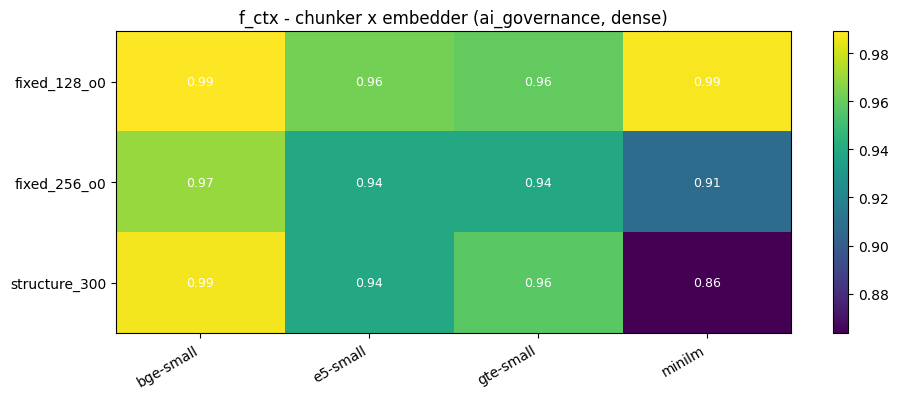

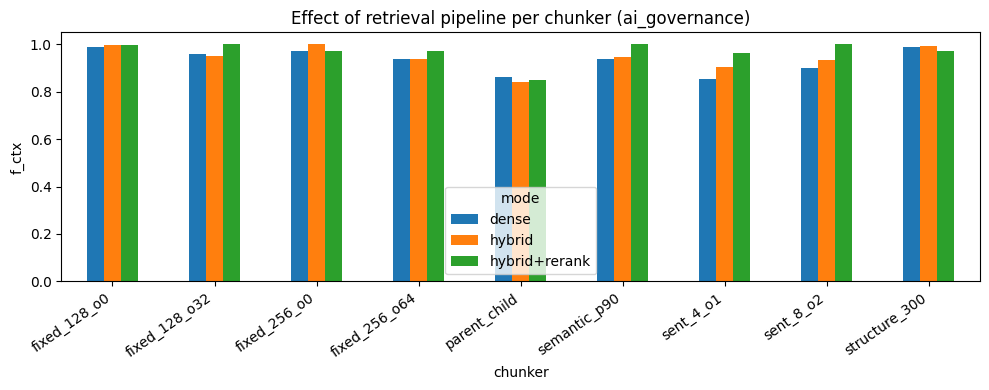

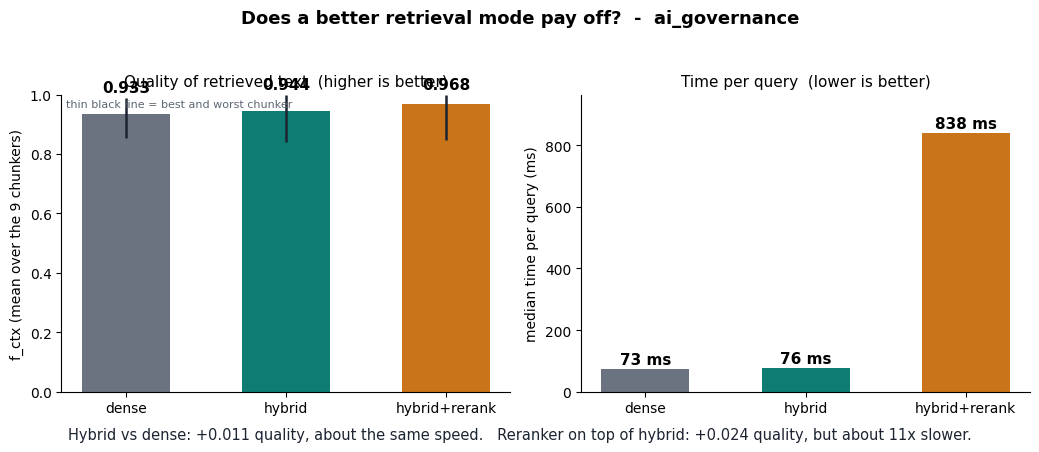

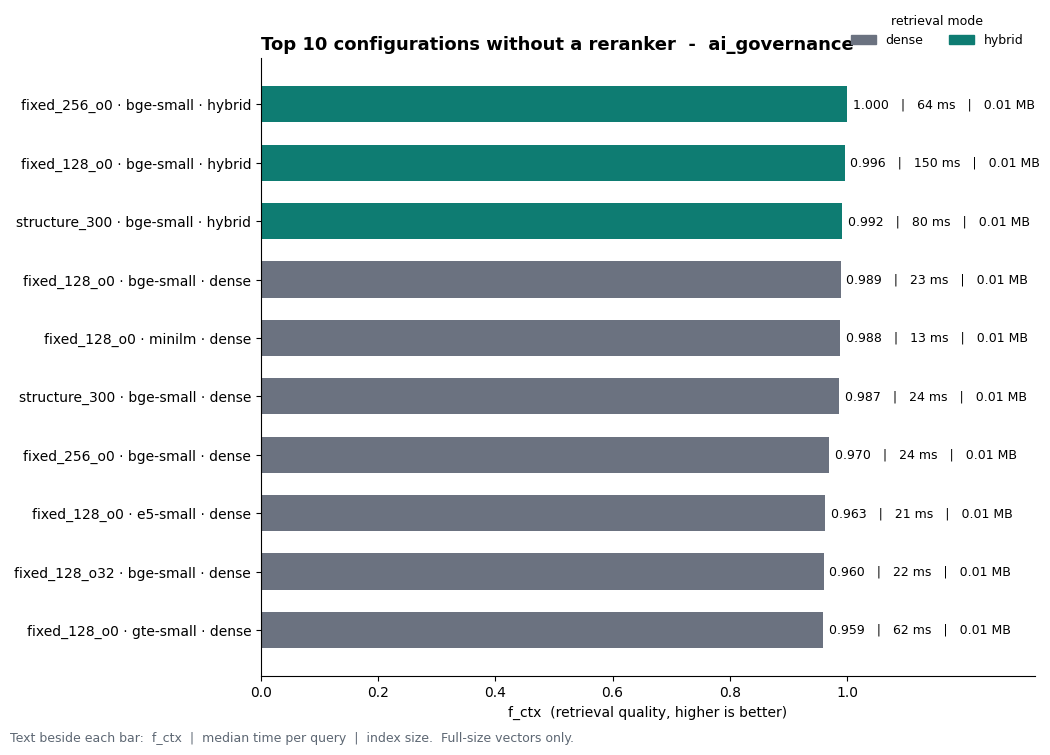

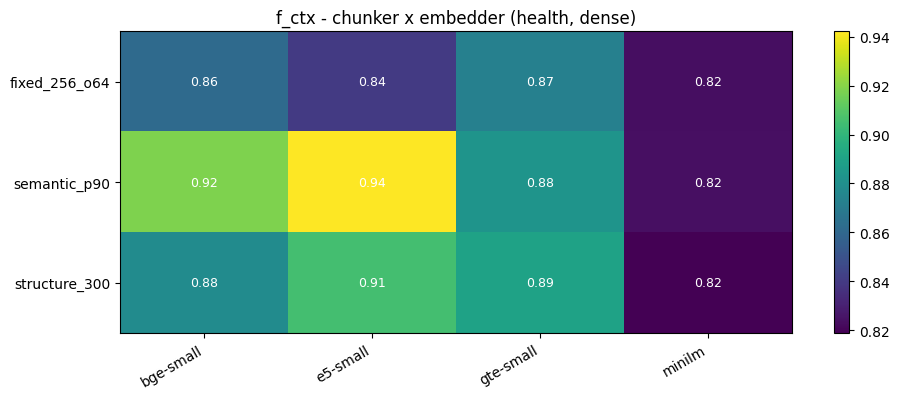

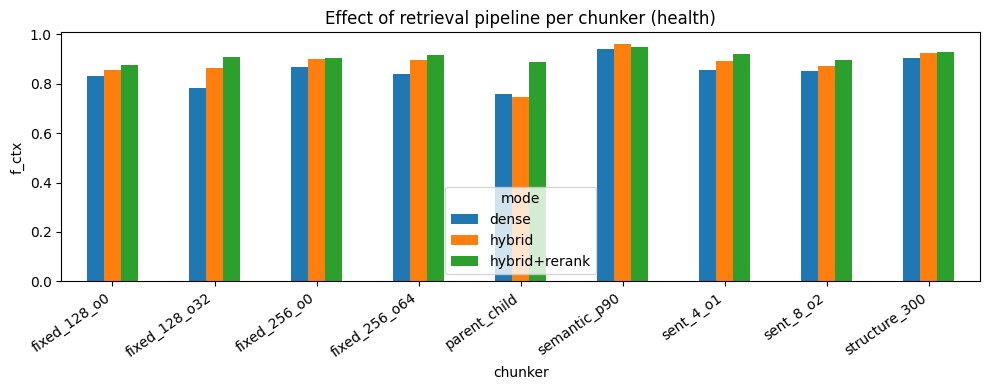

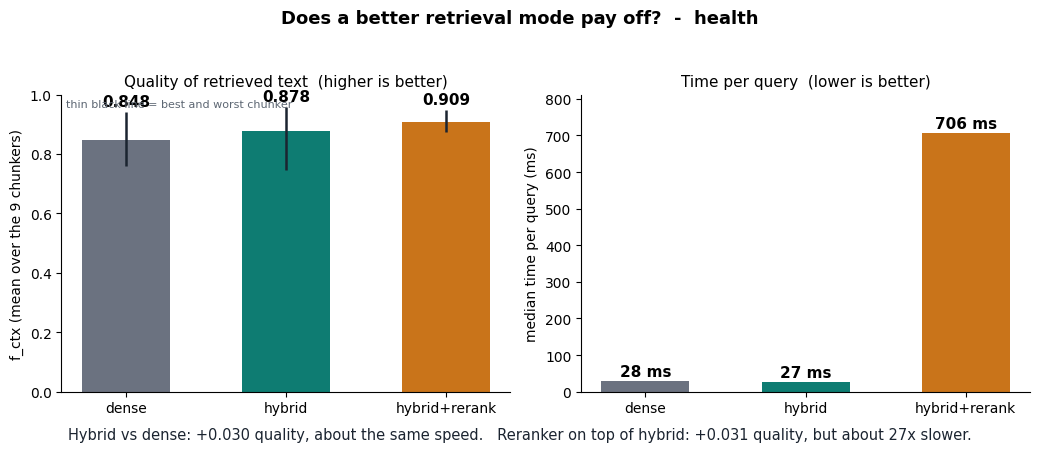

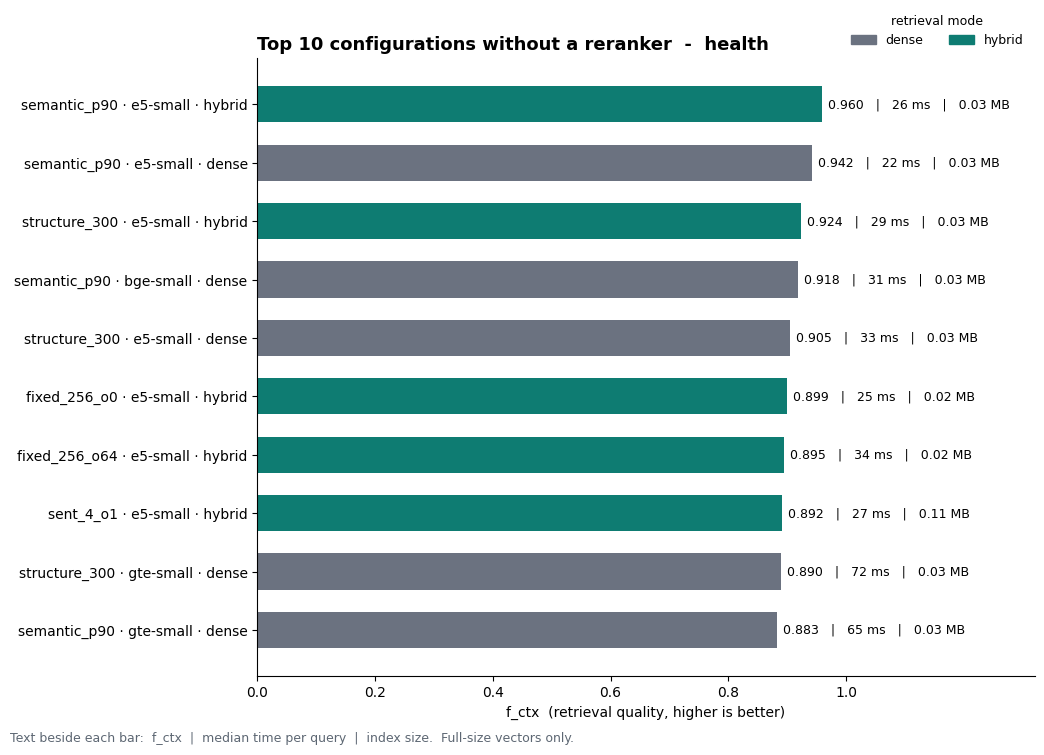

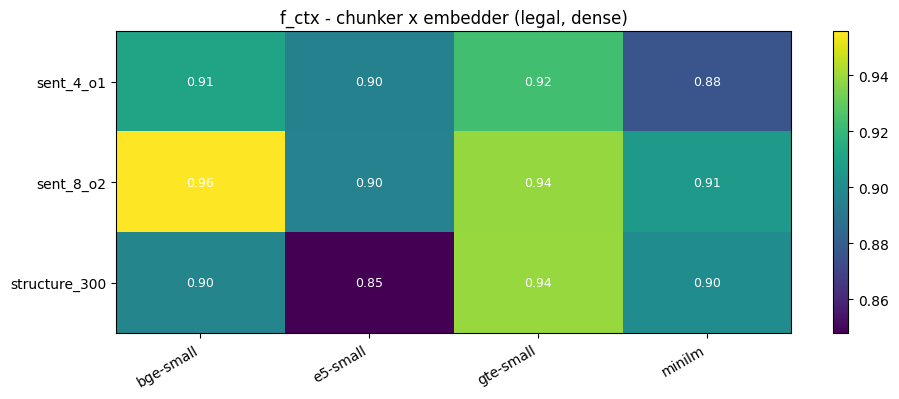

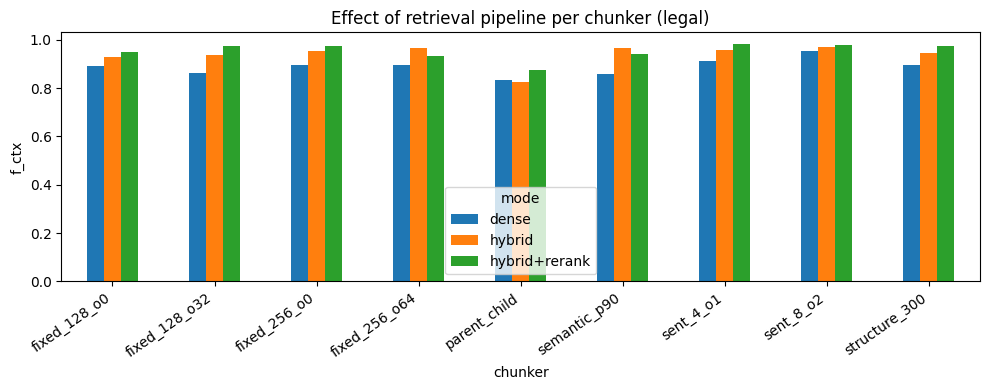

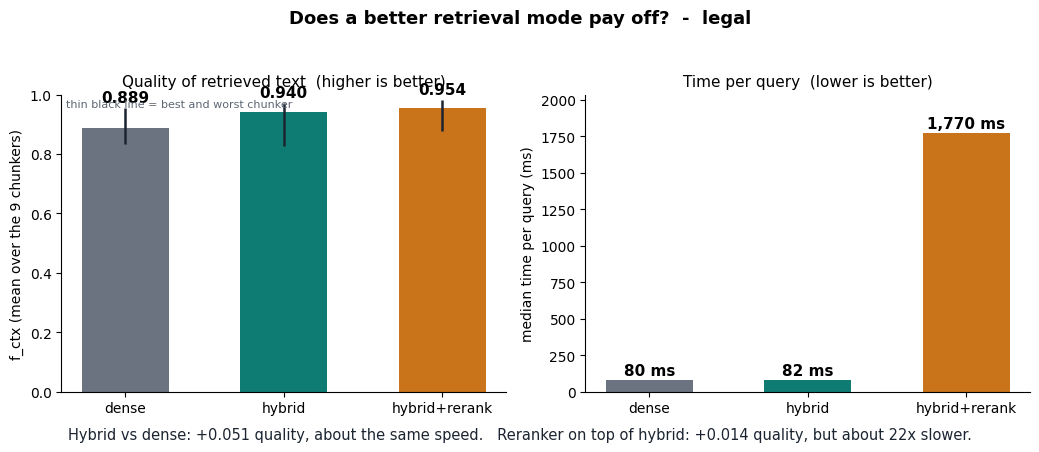

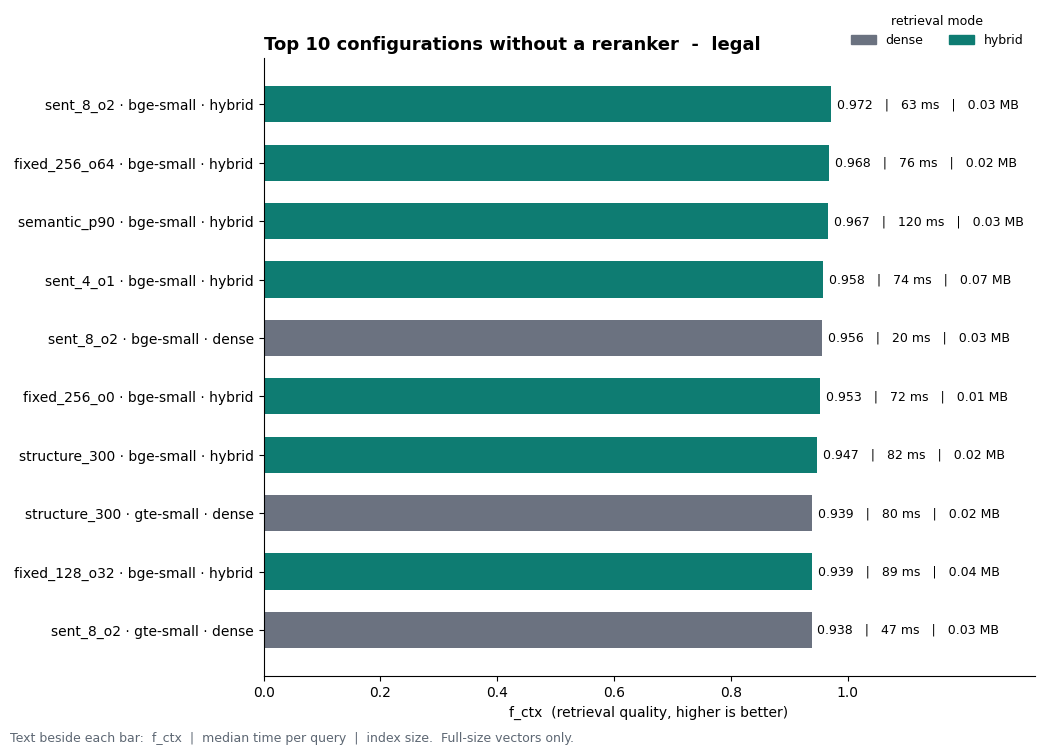

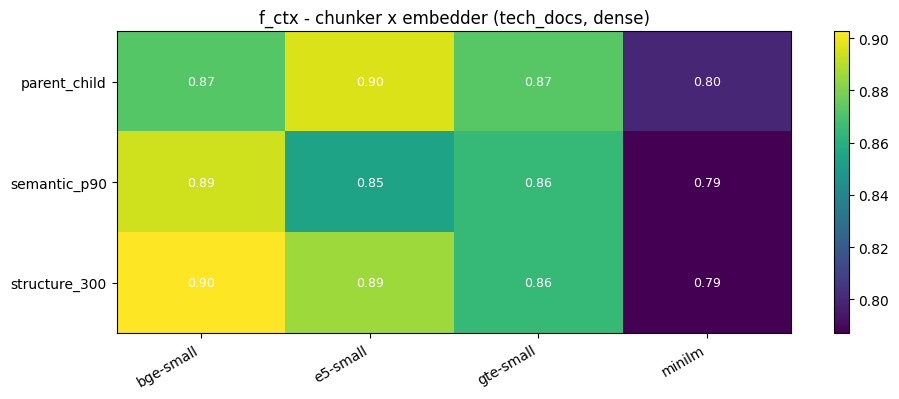

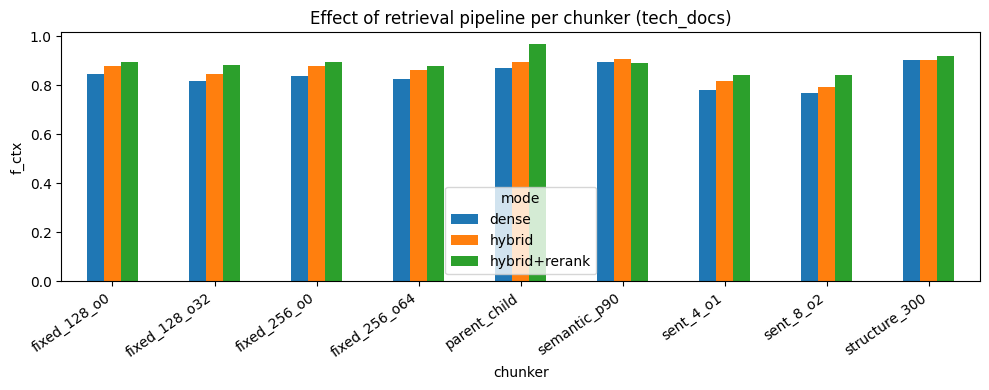

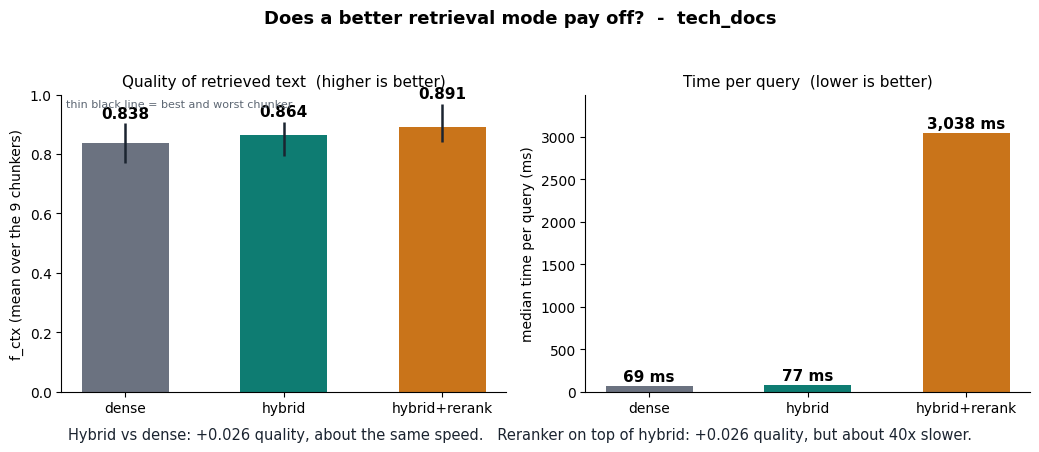

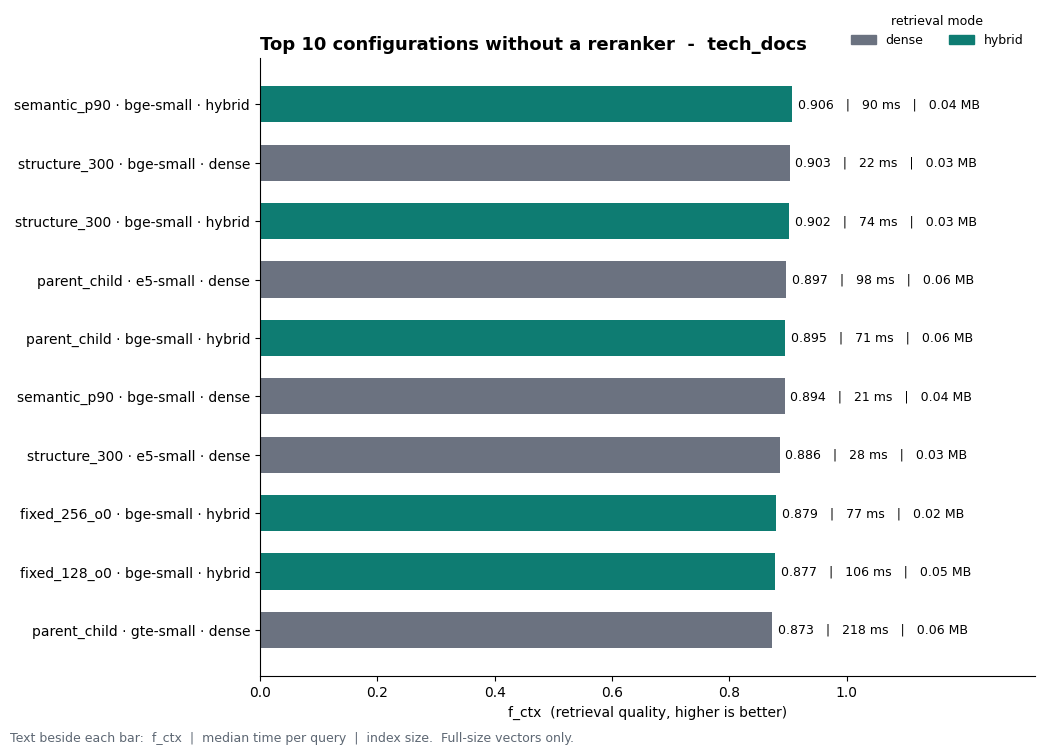

In [22]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
MODE_COL = {"dense": "#6b7280", "hybrid": "#0e7c72", "hybrid+rerank": "#c9741a"}
def _finish(fig, name):
    fig.tight_layout(); fig.savefig(OUT_DIR / name, dpi=160, bbox_inches="tight"); plt.show()
def _clean(ax):
    ax.spines[["top", "right"]].set_visible(False)

def plot_heatmap(corpus):
    d = stage_df("2"); d = d[(d.corpus == corpus) & (d["mode"] == "dense")]
    if d.empty: return
    pv = d.pivot_table(index="chunker", columns="embedder", values="f_ctx")
    fig, ax = plt.subplots(figsize=(1.7 * len(pv.columns) + 3, 0.7 * len(pv) + 2))
    im = ax.imshow(pv.values, aspect="auto")
    ax.set_xticks(range(len(pv.columns))); ax.set_xticklabels(pv.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(pv.index))); ax.set_yticklabels(pv.index)
    for (i, j), v in np.ndenumerate(pv.values): ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white", fontsize=9)
    ax.set_title(f"f_ctx - chunker x embedder ({corpus}, dense)"); fig.colorbar(im)
    _finish(fig, f"heatmap_{corpus}.png")

def plot_pipeline_effect(corpus):
    d = stage_df("3a"); d = d[d.corpus == corpus]
    if d.empty: return
    pv = d.pivot_table(index="chunker", columns="mode", values="f_ctx")[MODES]
    fig, ax = plt.subplots(figsize=(10, 4)); pv.plot(kind="bar", ax=ax)
    ax.set_ylabel("f_ctx"); ax.set_title(f"Effect of retrieval pipeline per chunker ({corpus})"); plt.xticks(rotation=35, ha="right")
    _finish(fig, f"pipeline_{corpus}.png")

def plot_mode_tradeoff(corpus):
    d = results_df(); d = d[(d.corpus == corpus) & (d.stage == "3a")]
    if d.empty:
        d = results_df(); d = d[(d.corpus == corpus) & (d.stage != "3b") & (d["quant"].fillna("") == "")].drop_duplicates("key")
    d = d.dropna(subset=["f_ctx", "lat_p50_ms"])
    order = [m for m in MODE_COL if m in set(d["mode"])]
    if len(order) < 2: return
    g = d.groupby("mode").agg(f=("f_ctx", "mean"), lo=("f_ctx", "min"), hi=("f_ctx", "max"), lat=("lat_p50_ms", "median")).loc[order]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 4.3))
    for x, (m, r) in enumerate(g.iterrows()):
        a1.bar(x, r.f, color=MODE_COL[m], width=0.55); a1.vlines(x, r.lo, r.hi, color="#1b2430", lw=1.8, zorder=3)
        a1.text(x, r.hi + 0.02, f"{r.f:.3f}", ha="center", fontsize=11, fontweight="bold")
        a2.bar(x, r.lat, color=MODE_COL[m], width=0.55)
        a2.text(x, r.lat + g.lat.max() * 0.02, f"{r.lat:,.0f} ms", ha="center", fontsize=11, fontweight="bold")
    for a in (a1, a2):
        a.set_xticks(range(len(order))); a.set_xticklabels(order, fontsize=10); _clean(a)
    a1.set_ylim(0, 1.0); a1.set_ylabel("f_ctx (mean over the 9 chunkers)")
    a1.set_title("Quality of retrieved text  (higher is better)", fontsize=11)
    a1.text(0.01, 0.985, "thin black line = best and worst chunker", transform=a1.transAxes, ha="left", va="top", fontsize=8, color="#5d6773")
    a2.set_ylim(0, g.lat.max() * 1.15); a2.set_ylabel("median time per query (ms)")
    a2.set_title("Time per query  (lower is better)", fontsize=11)
    msg = ""
    if "hybrid" in g.index and "dense" in g.index:
        r_ = g.lat["hybrid"] / max(g.lat["dense"], 1e-9)
        speed = "about the same speed" if 0.5 <= r_ <= 2 else (f"{r_:.1f}x slower" if r_ > 2 else f"{1 / r_:.1f}x faster")
        msg = f"Hybrid vs dense: {g.f['hybrid'] - g.f['dense']:+.3f} quality, {speed}."
    if "hybrid+rerank" in g.index and "hybrid" in g.index:
        msg += f"   Reranker on top of hybrid: {g.f['hybrid+rerank'] - g.f['hybrid']:+.3f} quality, but about {g.lat['hybrid+rerank'] / max(g.lat['hybrid'], 1e-9):,.0f}x slower."
    fig.suptitle(f"Does a better retrieval mode pay off?  -  {corpus}", fontsize=13, fontweight="bold")
    fig.text(0.5, -0.02, msg, ha="center", fontsize=10.5, color="#1b2430")
    fig.tight_layout(rect=(0, 0, 1, 0.94)); fig.savefig(OUT_DIR / f"graph_A_mode_tradeoff_{corpus}.png", dpi=160, bbox_inches="tight"); plt.show()

def plot_best_fast(corpus, top=10):
    d = results_df(); d = d[(d.corpus == corpus) & (d.stage != "3b")].drop_duplicates("key").dropna(subset=["f_ctx"])
    d = d[(d["quant"].fillna("") == "") & d["mode"].isin(["dense", "hybrid"])]
    d = d[d["dim"] == d.groupby("embedder")["dim"].transform("max")]
    t = d.sort_values("f_ctx", ascending=False).head(top).iloc[::-1]
    if t.empty: return
    fig, ax = plt.subplots(figsize=(10.5, 0.55 * len(t) + 1.9))
    ax.barh([f"{r.chunker} · {r.embedder} · {r['mode']}" for _, r in t.iterrows()], t.f_ctx, color=[MODE_COL[m] for m in t["mode"]], height=0.62)
    for y, (_, r) in enumerate(t.iterrows()):
        lat = f"{r.lat_p50_ms:.0f} ms" if pd.notna(r.lat_p50_ms) else "n/a"
        ax.text(r.f_ctx + 0.01, y, f"{r.f_ctx:.3f}   |   {lat}   |   {r.index_mb:.2f} MB", va="center", fontsize=9)
    ax.set_xlim(0, 1.32); ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0]); _clean(ax)
    ax.set_xlabel("f_ctx  (retrieval quality, higher is better)")
    ax.set_title(f"Top {len(t)} configurations without a reranker  -  {corpus}", fontsize=13, fontweight="bold", loc="left")
    ax.legend(handles=[Patch(color=MODE_COL[m], label=m) for m in ("dense", "hybrid")], title="retrieval mode", loc="lower right",
              bbox_to_anchor=(1.0, 1.0), ncol=2, frameon=False, fontsize=9, title_fontsize=9)
    fig.text(0.01, -0.01, "Text beside each bar:  f_ctx  |  median time per query  |  index size.  Full-size vectors only.", fontsize=9, color="#5d6773")
    fig.tight_layout(); fig.savefig(OUT_DIR / f"graph_B_best_fast_{corpus}.png", dpi=160, bbox_inches="tight"); plt.show()

def plot_pareto(corpus):
    plot_mode_tradeoff(corpus); plot_best_fast(corpus)

for corpus in GOLD:
    plot_heatmap(corpus); plot_pipeline_effect(corpus); plot_pareto(corpus)


## 16b. Cross-domain view: does the best chunker depend on the document type?
Uses the Stage 1 results (same embedder, dense retrieval) from every domain. It shows f_ctx per chunker and domain, the best chunker in each domain, and how similar the chunker rankings are between domains (Spearman correlation: 1 = identical ranking, 0 = unrelated, negative = reversed). With only 75 or so questions per domain, small differences are within noise, so read the correlations together with the confidence intervals in section 15.

corpus,ai_governance,health,legal,tech_docs
chunker,,,,
fixed_128_o0,0.989,0.799,0.894,0.846
fixed_128_o32,0.960,0.828,0.864,0.817
fixed_256_o0,0.970,0.849,0.895,0.840
fixed_256_o64,0.939,0.861,0.895,0.824
parent_child,0.864,0.742,0.833,0.872
semantic_p90,0.937,0.918,0.858,0.894
sent_4_o1,0.853,0.851,0.911,0.782
sent_8_o2,0.898,0.830,0.956,0.769
structure_300,0.987,0.878,0.897,0.903


Best chunker per domain: {'ai_governance': 'fixed_128_o0', 'health': 'semantic_p90', 'legal': 'sent_8_o2', 'tech_docs': 'structure_300'}
Mean rank correlation between domains: 0.07  (1 = same ranking everywhere)
Rank of structure_300 (1 = best): {'ai_governance': 2, 'health': 2, 'legal': 3, 'tech_docs': 1}


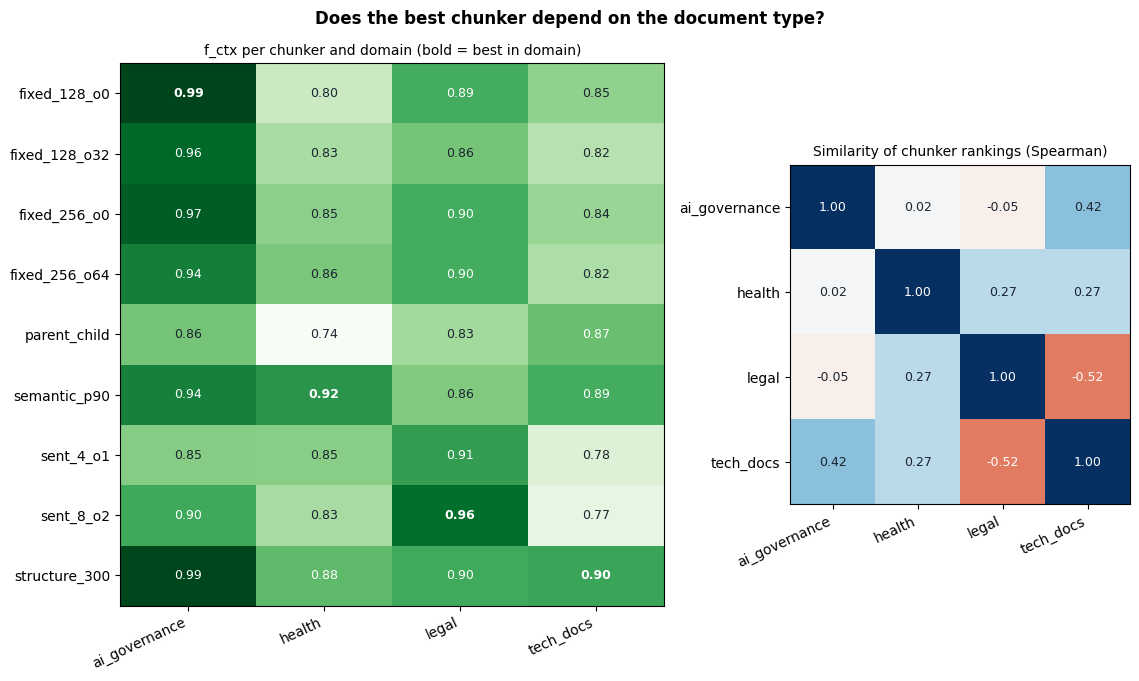

In [23]:
def cross_domain_view(stage="1"):
    d = stage_df(stage)
    if d.empty or d.corpus.nunique() < 2:
        print("Need results for at least two domains."); return None
    pv = d[d["mode"] == "dense"].pivot_table(index="chunker", columns="corpus", values="f_ctx")
    cols = list(pv.columns)
    rho = pv.corr(method="spearman")
    display(pv.round(3)); pv.to_csv(OUT_DIR / "cross_domain_chunkers.csv")
    print("Best chunker per domain:", pv.idxmax().to_dict())
    off = rho.values[np.triu_indices(len(cols), 1)]
    print(f"Mean rank correlation between domains: {np.nanmean(off):.2f}  (1 = same ranking everywhere)")
    if "structure_300" in pv.index:
        print("Rank of structure_300 (1 = best):", pv.rank(ascending=False).loc["structure_300"].astype(int).to_dict())
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 0.5 * len(pv) + 2.4), gridspec_kw=dict(width_ratios=[1.6, 1]))
    im = a1.imshow(pv.values, aspect="auto", cmap="Greens"); a1.set_xticks(range(len(cols))); a1.set_xticklabels(cols, rotation=25, ha="right")
    a1.set_yticks(range(len(pv))); a1.set_yticklabels(pv.index)
    for i in range(pv.shape[0]):
        for k in range(pv.shape[1]):
            a1.text(k, i, f"{pv.values[i, k]:.2f}", ha="center", va="center", fontsize=9, fontweight="bold" if pv.values[i, k] == pv[cols[k]].max() else "normal",
                    color="white" if pv.values[i, k] > np.nanmedian(pv.values) else "#1b2430")
    a1.set_title("f_ctx per chunker and domain (bold = best in domain)", fontsize=10)
    a2.imshow(rho.values, vmin=-1, vmax=1, cmap="RdBu"); a2.set_xticks(range(len(cols))); a2.set_xticklabels(cols, rotation=25, ha="right"); a2.set_yticks(range(len(cols))); a2.set_yticklabels(cols)
    for i in range(len(cols)):
        for k in range(len(cols)): a2.text(k, i, f"{rho.values[i, k]:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(rho.values[i, k]) > 0.5 else "#1b2430")
    a2.set_title("Similarity of chunker rankings (Spearman)", fontsize=10)
    fig.suptitle("Does the best chunker depend on the document type?", fontweight="bold")
    fig.tight_layout(); fig.savefig(OUT_DIR / "graph_C_cross_domain_chunkers.png", dpi=160, bbox_inches="tight"); plt.show()
    return pv, rho
CROSS = cross_domain_view()


## 17. Decision matrix (the main deliverable)
For each corpus and priority (accuracy / speed / low storage cost / balanced) we score every evaluated configuration by a weighted mix of normalised **f_ctx**, **latency** and **index size**, and report the winner. The same logic powers the advisor app below.

In [24]:
WEIGHTS = {"accuracy": (0.8, 0.1, 0.1), "speed": (0.4, 0.5, 0.1), "low_cost": (0.4, 0.1, 0.5), "balanced": (0.5, 0.25, 0.25)}

def _norm(s, invert=False):
    s = s.astype(float); rng = s.max() - s.min()
    z = (s - s.min()) / rng if rng > 0 else pd.Series(1.0, index=s.index)
    return 1 - z if invert else z

def score_table(df, corpus, w):
    d = df[(df.corpus == corpus) & (df.stage != "3b")].drop_duplicates("key").dropna(subset=["f_ctx"]).copy()
    if d.empty: return d
    d["score"] = w[0] * _norm(d.f_ctx) + w[1] * _norm(np.log1p(d.lat_p50_ms), invert=True) + w[2] * _norm(np.log1p(d.index_mb), invert=True)
    return d.sort_values("score", ascending=False)

def build_decision_matrix():
    df = results_df(); rows = []
    for corpus in sorted(df.corpus.unique()):
        for prio, w in WEIGHTS.items():
            t = score_table(df, corpus, w)
            if t.empty: continue
            b = t.iloc[0]
            rows.append(dict(corpus=corpus, priority=prio, chunker=b.chunker, embedder=b.embedder, mode=b["mode"], dim=b.dim, quant=b.quant or "-",
                             f_ctx=round(b.f_ctx, 3), recall=round(b.recall, 3), precision=round(b.precision, 3),
                             lat_p50_ms=round(b.lat_p50_ms, 1), index_mb=round(b.index_mb, 2)))
    return pd.DataFrame(rows)

DECISION = build_decision_matrix()
DECISION.to_csv(OUT_DIR / "decision_matrix.csv", index=False)
display(DECISION)


,corpus,priority,chunker,embedder,mode,dim,quant,f_ctx,recall,precision,lat_p50_ms,index_mb
0,ai_governance,accuracy,fixed_256_o0,bge-small,hybrid,384,-,1.000,1.000,1.000,64.5,0.01
1,ai_governance,speed,fixed_128_o0,minilm,dense,384,-,0.988,1.000,0.977,13.0,0.01
2,ai_governance,low_cost,fixed_128_o0,bge-small,dense,256,binary,0.983,1.000,0.970,25.1,0.00
3,ai_governance,balanced,fixed_128_o0,bge-small,dense,128,-,0.989,0.980,1.000,21.8,0.00
4,health,accuracy,semantic_p90,e5-small,hybrid,384,-,0.960,0.986,0.950,26.2,0.03
5,health,speed,semantic_p90,e5-small,dense,384,-,0.942,0.986,0.925,21.8,0.03
6,health,low_cost,semantic_p90,e5-small,dense,128,-,0.908,0.972,0.879,63.4,0.01
7,health,balanced,semantic_p90,e5-small,hybrid,384,-,0.960,0.986,0.950,26.2,0.03
8,legal,accuracy,fixed_256_o64,bge-small,hybrid,384,-,0.968,1.000,0.946,76.2,0.02
9,legal,speed,sent_8_o2,bge-small,dense,384,-,0.956,0.999,0.926,19.9,0.03


## 18. Cross-provider robustness check (optional but a strong result)
Run Stage 3b once with `PROVIDER=gemini`, then change `PROVIDER` (cell 1 or `.env`) to `openrouter`, re-run Stage 3b, and compare. If the *ranking* of configurations stays the same, your conclusions do not depend on one particular generator / judge.

In [25]:
from scipy.stats import spearmanr

def provider_agreement(prov_a="gemini", prov_b="openrouter", metrics=("groundedness", "correctness")):
    df = results_df(); df = df[df.stage == "3b"]
    a = df[df.provider == prov_a].set_index("key"); b = df[df.provider == prov_b].set_index("key")
    common = a.index.intersection(b.index)
    if len(common) < 3:
        print(f"Need >=3 shared configurations scored by both providers (found {len(common)}). Run Stage 3b with each provider."); return
    for m in metrics:
        rho, p = spearmanr(a.loc[common, m], b.loc[common, m])
        print(f"{m:13s} Spearman rho = {rho:.2f} (p={p:.3f}) over {len(common)} configs | mean {prov_a}={a.loc[common, m].mean():.3f}  mean {prov_b}={b.loc[common, m].mean():.3f}")

provider_agreement("gemini", "openrouter")


Need >=3 shared configurations scored by both providers (found 0). Run Stage 3b with each provider.


## 19. RAG Studio (Streamlit): one app for everything
Writes `rag_studio.py`. Run it from this folder with `streamlit run rag_studio.py`.

It has three tabs:
* **Ask your documents**: ask a question about a corpus in `data/<corpus>/`. The answer cites numbered sources, and you can inspect each source passage.
* **Compare LLM answers**: send the same question to up to four models (Gemini and OpenRouter, using your own key), and see the answers side by side, with latency, the sources used and a word-overlap table between answers. Download the comparison as CSV.
* **Advisor**: recommends a chunking, embedding and retrieval setup for a document type and priority, from `outputs/results.csv`.

Without a key the Ask and Compare tabs run in offline demo mode, so you can try the app before adding keys. API keys are typed into the sidebar, kept in the browser session only, and never written to disk. Install the optional extras you need: `sentence-transformers` (BGE embeddings), `pypdf` (PDF documents), `google-genai` (Gemini) and `openai` (OpenRouter).

In [ ]:
%%writefile rag_studio.py
import hashlib
import html as _html
import importlib.util
import bisect
import math
import re
import time
from collections import Counter
from pathlib import Path

import altair as alt
import numpy as np
import pandas as pd
import streamlit as st

st.set_page_config(page_title="RAG Studio", page_icon=None, layout="wide")

DATA_DIR = Path("data")
RESULTS_PATH = Path("outputs/results.csv")
OFFLINE = "Offline demo (no key)"
TOPK = 5
PROFILES = {"Accuracy first": (0.8, 0.1, 0.1), "Balanced": (0.5, 0.25, 0.25),
            "Speed first": (0.4, 0.5, 0.1), "Low storage": (0.4, 0.1, 0.5)}
HAS_ST = importlib.util.find_spec("sentence_transformers") is not None
GEN_PROMPT = ("Answer the question using ONLY the context below. Cite the sources you use as [1], [2]. "
              "If the context does not contain the answer, reply exactly: I don't know.\n\nContext:\n")
STOP = set("""the a an of to in and or is are was were what how why which who when for on with by as at be it this that does do
document text documents say says said about according please tell me explain describe section""".split())

# Metrics shown in the heatmap: column -> (label, higher_is_better, one-line meaning for the audience)
METRICS = {
    "f_ctx": ("f_ctx (main score)", True, "Balance of recall and precision. The single number used to rank setups."),
    "recall": ("Recall", True, "How much of the evidence text the retrieved passages cover."),
    "precision": ("Precision", True, "How many of the retrieved passages are actually relevant, rank-aware."),
    "hit": ("Hit@k", True, "Share of questions where at least one relevant passage was retrieved."),
    "mrr": ("MRR", True, "How early the first relevant passage appears (1 = always first)."),
    "lat_p50_ms": ("Latency p50 (ms)", False, "Median time to retrieve for one question. Lower is better."),
    "index_mb": ("Index size (MB)", False, "Disk or memory used by the vector index. Lower is better."),
}

# ----------------------------------------------------------------- visual design
PALETTE = {"accent": "#12a39a", "accent_dark": "#0b6e6e", "navy": "#14213d"}

# Colours are theme-neutral on purpose: text inherits the Streamlit theme and panels use translucent fills,
# so the page stays readable in both light and dark mode.
st.markdown(f"""
<style>
  .block-container {{ padding-top: 3.6rem; padding-bottom: 3rem; max-width: 1250px; }}
  .hero {{ background: linear-gradient(120deg, {PALETTE['navy']} 0%, #1f3b63 55%, {PALETTE['accent_dark']} 100%);
           border-radius: 16px; padding: 1.6rem 1.9rem; margin-bottom: 1.4rem; }}
  .hero h1 {{ color: #ffffff !important; margin: 0 0 .25rem 0; font-size: 2rem; }}
  .hero p {{ color: #d5e3f2 !important; margin: 0; font-size: 1.02rem; }}
  .step {{ display: flex; gap: .8rem; align-items: flex-start; margin: .2rem 0 .6rem 0; }}
  .step .num {{ background: {PALETTE['accent_dark']}; color: #ffffff; width: 1.8rem; height: 1.8rem; min-width: 1.8rem;
                border-radius: 50%; display: flex; align-items: center; justify-content: center; font-weight: 700; font-size: .95rem; }}
  .step .txt {{ font-size: 1.02rem; line-height: 1.5; color: inherit; }}
  .step .txt b {{ color: {PALETTE['accent']}; }}
  .callout {{ background: rgba(18,163,154,.13); border-left: 4px solid {PALETTE['accent']}; border-radius: 8px;
              padding: .85rem 1.1rem; margin: .6rem 0 1rem 0; line-height: 1.55; color: inherit; }}
  .callout b {{ color: {PALETTE['accent']}; }}
  .rec {{ border: 1px solid rgba(128,128,128,.35); border-left: 5px solid {PALETTE['accent']}; border-radius: 12px;
          padding: 1.1rem 1.3rem; background: rgba(128,128,128,.07); margin-bottom: .9rem; }}
  .rec .label {{ text-transform: uppercase; letter-spacing: .08em; font-size: .75rem; opacity: .7; font-weight: 600; }}
  .rec .title {{ font-size: 1.25rem; font-weight: 700; margin-top: .25rem; color: inherit; }}
  div[data-testid="stMetric"] {{ background: rgba(128,128,128,.08); border: 1px solid rgba(128,128,128,.3);
                                 border-radius: 12px; padding: .75rem 1rem; }}
  button[data-baseweb="tab"] {{ font-weight: 600; font-size: 1.02rem; }}
  button[data-baseweb="tab"][aria-selected="true"] {{ color: {PALETTE['accent']}; }}
  div[data-baseweb="tab-highlight"] {{ background-color: {PALETTE['accent']} !important; }}
  .pill {{ display: inline-block; background: rgba(18,163,154,.16); border: 1px solid rgba(18,163,154,.5); color: inherit;
           border-radius: 999px; padding: .12rem .75rem; font-size: .82rem; font-weight: 600; margin: 0 .4rem .35rem 0; }}
  .pill.muted {{ background: rgba(128,128,128,.12); border-color: rgba(128,128,128,.4); }}
  .q {{ font-size: 1.12rem; font-weight: 700; margin-bottom: .5rem; }}
  .lbl {{ text-transform: uppercase; letter-spacing: .08em; font-size: .72rem; opacity: .65; font-weight: 600; margin: .4rem 0 .15rem 0; }}
  .src {{ line-height: 1.65; font-size: .95rem; }}
  mark {{ background: rgba(255,183,3,.4); color: inherit; padding: 0 .12rem; border-radius: 3px; }}
</style>
""", unsafe_allow_html=True)


def step(n, text):
    st.markdown(f'<div class="step"><div class="num">{n}</div><div class="txt">{text}</div></div>', unsafe_allow_html=True)


def callout(text):
    st.markdown(f'<div class="callout">{text}</div>', unsafe_allow_html=True)


# ----------------------------------------------------------------- chunking (character spans; same methods as the notebook)
BLOCK = re.compile(r"\S.*?(?=\n\s*\n|\Z)", re.S)
HEAD = re.compile(r"^(#{1,6}\s|(Section|SECTION|Article|ARTICLE|Chapter|CHAPTER|Clause|Rule|Regulation)\s+\d+|\d+(\.\d+)*[.)]?\s+[A-Z])")
SENT = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(\[`])")


def wc(text, a, b):
    return len(text[a:b].split())


def chunk_fixed(text, size=256, overlap=64, s=0, e=None):
    e = len(text) if e is None else e
    w = [(m.start() + s, m.end() + s) for m in re.finditer(r"\S+", text[s:e])]
    out, step_ = [], max(1, size - overlap)
    for i in range(0, len(w), step_):
        j = min(i + size, len(w))
        out.append((w[i][0], w[j - 1][1]))
        if j == len(w):
            break
    return out


def sentence_spans(text):
    sents = []
    for m in BLOCK.finditer(text):
        bs, be = m.span(); blk = text[bs:be]
        if blk.startswith(("#", "```")):
            sents.append((bs, be)); continue
        last = 0
        for x in SENT.finditer(blk):
            sents.append((bs + last, bs + x.start())); last = x.end()
        sents.append((bs + last, be))
    return [x for x in sents if x[1] > x[0]]


def chunk_sentences(text, n=4, overlap=1):
    sp = sentence_spans(text)
    out, step_ = [], max(1, n - overlap)
    for i in range(0, len(sp), step_):
        j = min(i + n, len(sp))
        out.append((sp[i][0], sp[j - 1][1]))
        if j == len(sp):
            break
    return out


def chunk_structure(text, max_words=300, min_words=40):
    cur, cw, groups = None, 0, []
    for m in BLOCK.finditer(text):
        a, b = m.span(); w = wc(text, a, b)
        head = bool(HEAD.match(text[a:b])) and (b - a) < 200
        if cur is None:
            cur, cw = [a, b], w
        elif (head and cw >= min_words) or (cw + w > max_words and cw >= min_words):
            groups.append(tuple(cur)); cur, cw = [a, b], w
        else:
            cur[1] = b; cw += w
    if cur:
        groups.append(tuple(cur))
    out = []
    for a, b in groups:                                   # sections longer than max_words are cut into windows
        out += chunk_fixed(text, max_words, 0, a, b) if wc(text, a, b) > max_words else [(a, b)]
    return out


def chunk_semantic(text, embed_fn, percentile=90, buffer=1, min_words=40, max_words=300):
    """Cut where the meaning changes most: compare neighbouring sentence windows and split at the biggest jumps."""
    sp = sentence_spans(text)
    if len(sp) < 3:
        return [(sp[0][0], sp[-1][1])] if sp else []
    sents = [text[a:b] for a, b in sp]
    combo = [" ".join(sents[max(0, i - buffer): i + buffer + 1]) for i in range(len(sents))]
    E = embed_fn(combo)
    dist = 1 - np.sum(E[:-1] * E[1:], axis=1)
    thr = np.percentile(dist, percentile)
    groups, cur = [], [0]
    for i, d in enumerate(dist):
        if d > thr:
            groups.append(cur); cur = [i + 1]
        else:
            cur.append(i + 1)
    groups.append(cur)
    merged = []
    for g in groups:
        a, b = sp[g[0]][0], sp[g[-1]][1]
        if merged and wc(text, *merged[-1]) < min_words:
            merged[-1] = (merged[-1][0], b)
        else:
            merged.append((a, b))
    if len(merged) > 1 and wc(text, *merged[-1]) < min_words:
        last = merged.pop(); merged[-1] = (merged[-1][0], last[1])
    final = []
    for a, b in merged:
        final += chunk_fixed(text, max_words, 0, a, b) if wc(text, a, b) > max_words else [(a, b)]
    return final


def chunk_parent_child(text, child=100, parent=400):
    """Index small child pieces, but return the larger parent section each child belongs to."""
    parents = chunk_structure(text, parent); pst = [p[0] for p in parents]
    out = []
    for a, b in chunk_fixed(text, child, 0):
        pi = max(0, bisect.bisect_right(pst, a) - 1)
        out.append((a, b, parents[pi][0], parents[pi][1]))
    return out


# The nine chunking methods from the study (same names as the heatmap rows).
CHUNKERS = {
    "fixed_128_o0":  dict(kind="fixed", size=128, overlap=0, info="Fixed windows of 128 words, no overlap. Small, precise chunks."),
    "fixed_128_o32": dict(kind="fixed", size=128, overlap=32, info="128-word windows; each shares 32 words with the previous one."),
    "fixed_256_o0":  dict(kind="fixed", size=256, overlap=0, info="Fixed windows of 256 words, no overlap. Larger chunks, more context."),
    "fixed_256_o64": dict(kind="fixed", size=256, overlap=64, info="256-word windows; each shares 64 words with the previous one."),
    "sent_4_o1":     dict(kind="sent", n=4, overlap=1, info="Groups of 4 whole sentences, 1 sentence of overlap."),
    "sent_8_o2":     dict(kind="sent", n=8, overlap=2, info="Groups of 8 whole sentences, 2 sentences of overlap."),
    "semantic_p90":  dict(kind="semantic", percentile=90, max_words=300, info="Splits where the topic changes most, up to 300 words."),
    "structure_300": dict(kind="structure", max_words=300, info="Follows headings and paragraphs, up to 300 words per chunk."),
    "parent_child":  dict(kind="parent_child", child=100, parent=400, info="Searches small 100-word pieces, shows the 400-word section around them."),
}


def make_spans(text, spec, embed_fn=None):
    """Returns (start, end, parent_start, parent_end) per chunk; parent_* is None except for parent_child."""
    k = spec["kind"]
    if k == "fixed":
        return [(a, b, None, None) for a, b in chunk_fixed(text, spec["size"], spec["overlap"])]
    if k == "sent":
        return [(a, b, None, None) for a, b in chunk_sentences(text, spec["n"], spec["overlap"])]
    if k == "semantic":
        return [(a, b, None, None) for a, b in chunk_semantic(text, embed_fn, spec["percentile"], max_words=spec["max_words"])]
    if k == "structure":
        return [(a, b, None, None) for a, b in chunk_structure(text, spec["max_words"])]
    return chunk_parent_child(text, spec["child"], spec["parent"])


# ----------------------------------------------------------------- documents
def clean(t):
    t = t.replace("\r", "")
    t = re.sub(r"[ \t]+", " ", t)
    return re.sub(r"\n{3,}", "\n\n", t).strip()


def read_file(p):
    s = p.suffix.lower()
    try:
        if s in (".md", ".txt"):
            return p.read_text(errors="ignore")
        if s in (".html", ".htm"):
            t = re.sub(r"(?is)<(script|style).*?</\1>", " ", p.read_text(errors="ignore"))
            return _html.unescape(re.sub(r"<[^>]+>", " ", t))
        if s == ".pdf":
            from pypdf import PdfReader
            return "\n\n".join((pg.extract_text() or "") for pg in PdfReader(str(p)).pages)
    except Exception as e:
        st.warning(f"Could not read {p.name}: {e}")
    return None


def list_corpora():
    return sorted(d.name for d in DATA_DIR.iterdir() if d.is_dir()) if DATA_DIR.exists() else []


def load_docs(corpus):
    docs = []
    for p in sorted((DATA_DIR / corpus).glob("*")):
        t = read_file(p)
        if t and len(clean(t).split()) >= 50:
            docs.append((p.stem, clean(t)))
    return docs

# ----------------------------------------------------------------- embeddings, BM25, index
# The embedding models from the study (same names as the heatmap columns) plus an offline baseline.
EMBEDDERS = {
    "bge-small":   dict(kind="hf", model_id="BAAI/bge-small-en-v1.5", q_prefix="Represent this sentence for searching relevant passages: ",
                        info="BAAI bge-small-en-v1.5, 384 dimensions. Needs sentence-transformers."),
    "e5-small":    dict(kind="hf", model_id="intfloat/e5-small-v2", q_prefix="query: ", d_prefix="passage: ",
                        info="intfloat e5-small-v2, 384 dimensions. Needs sentence-transformers."),
    "gte-small":   dict(kind="hf", model_id="thenlper/gte-small",
                        info="thenlper gte-small, 384 dimensions. Needs sentence-transformers."),
    "minilm":      dict(kind="hf", model_id="sentence-transformers/all-MiniLM-L6-v2",
                        info="all-MiniLM-L6-v2, 384 dimensions. Smallest and fastest."),
    "hashing-bow": dict(kind="hash", info="Offline keyword hashing, 512 dimensions. No download, lowest quality."),
}


def hash_embed(texts, dim=512):
    X = np.zeros((len(texts), dim), dtype=np.float32)
    for i, t in enumerate(texts):
        for w in re.findall(r"\w+", t.lower()):
            X[i, int(hashlib.md5(w.encode()).hexdigest(), 16) % dim] += 1
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)


@st.cache_resource(show_spinner="Loading embedding model (first time only)...")
def get_st_model(model_id):
    from sentence_transformers import SentenceTransformer
    m = SentenceTransformer(model_id, device="cpu")
    try:
        m.max_seq_length = min(512, m.max_seq_length)
    except Exception:
        pass
    return m


def embed(texts, name, query=False):
    cfg = EMBEDDERS[name]
    if cfg["kind"] == "hash":
        return hash_embed(texts)
    prefix = cfg.get("q_prefix", "") if query else cfg.get("d_prefix", "")
    return get_st_model(cfg["model_id"]).encode([prefix + t for t in texts], normalize_embeddings=True,
                                                batch_size=32, show_progress_bar=False)


TOK = lambda s: re.findall(r"\w+", s.lower())


class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.tf = [Counter(d) for d in docs]
        self.dl = np.array([len(d) for d in docs], float)
        self.avg = self.dl.mean() if len(docs) else 1.0
        self.k1, self.b = k1, b
        df = Counter(t for c in self.tf for t in c); N = len(docs)
        self.idf = {t: math.log(1 + (N - n + 0.5) / (n + 0.5)) for t, n in df.items()}

    def scores(self, q):
        out = np.zeros(len(self.tf))
        for i, c in enumerate(self.tf):
            norm = self.k1 * (1 - self.b + self.b * self.dl[i] / self.avg)
            out[i] = sum(self.idf[t] * c[t] * (self.k1 + 1) / (c[t] + norm) for t in set(q) if t in c)
        return out


@st.cache_resource(show_spinner="Indexing documents (first time for this setting)...")
def build_index(corpus, chunker_name, embedder):
    spec = CHUNKERS[chunker_name]
    sem_name = "minilm" if HAS_ST else "hashing-bow"           # the semantic chunker uses MiniLM, as in the study
    spans, show = [], []
    for doc_id, text in load_docs(corpus):
        for a, b, pa, pb in make_spans(text, spec, lambda x: embed(x, sem_name)):
            spans.append((doc_id, a, b, text[a:b]))
            show.append((doc_id, pa, pb, text[pa:pb]) if pa is not None else (doc_id, a, b, text[a:b]))
    if not spans:
        return None
    return {"spans": spans, "show": show, "X": embed([x[3] for x in spans], embedder),
            "bm25": BM25([TOK(x[3]) for x in spans]), "embedder": embedder}


def retrieve(idx, question, mode, k=TOPK):
    q = embed([question], idx["embedder"], query=True)[0]
    ranked = [int(i) for i in np.argsort(-(idx["X"] @ q))[:30]]
    if mode == "hybrid":                                   # reciprocal rank fusion of dense and BM25 rankings
        bm_rank = [int(i) for i in np.argsort(-idx["bm25"].scores(TOK(question)))[:30]]
        score = {}
        for r, i in enumerate(ranked):
            score[i] = score.get(i, 0) + 1 / (60 + r + 1)
        for r, i in enumerate(bm_rank):
            score[i] = score.get(i, 0) + 1 / (60 + r + 1)
        ranked = sorted(score, key=score.get, reverse=True)
    out, seen = [], set()
    for i in ranked:                                       # parent_child: several children can share one parent
        u = idx["show"][i]
        if u[:3] in seen:
            continue
        seen.add(u[:3]); out.append(u)
        if len(out) == k:
            break
    return out


# ----------------------------------------------------------------- answers
def build_prompt(question, units):
    ctx = "\n\n".join(f"[{i}] {u[3]}" for i, u in enumerate(units, 1))
    return GEN_PROMPT + ctx + f"\n\nQuestion: {question}\nAnswer:"


def demo_answer(question, units):
    """Offline mode: returns the single sentence that shares the most question words, with its source number."""
    qw = set(TOK(question)) - STOP; best = None
    for n, (_, _, _, t) in enumerate(units, 1):
        for line in t.split("\n"):
            if line.lstrip().startswith("#"):
                continue                                   # skip headings
            for sent in re.split(r"(?<=[.!?])\s+", line):
                sent = sent.strip()
                if len(sent) < 20:
                    continue
                overlap = len(qw & set(TOK(sent)))
                if overlap and (best is None or overlap > best[0]):
                    best = (overlap, sent, n)
    if not best:
        return "I don't know."
    return f"{best[1][:400]} [{best[2]}]"


# ----------------------------------------------------------------- language-model providers
# Most providers speak the OpenAI "chat completions" format, so one code path serves them; Gemini and Anthropic have their own.
PROVIDERS = {
    "Gemini":         dict(kind="gemini", base="https://generativelanguage.googleapis.com/v1beta", hint="AIza...",
                           url="aistudio.google.com/apikey", example="gemini-2.5-flash"),
    "OpenRouter":     dict(kind="openai", base="https://openrouter.ai/api/v1", hint="sk-or-...",
                           url="openrouter.ai/keys", example="meta-llama/llama-3.3-70b-instruct:free"),
    "OpenAI":         dict(kind="openai", base="https://api.openai.com/v1", hint="sk-...",
                           url="platform.openai.com/api-keys", example="gpt-4o-mini"),
    "Groq":           dict(kind="openai", base="https://api.groq.com/openai/v1", hint="gsk_...",
                           url="console.groq.com/keys", example="llama-3.3-70b-versatile"),
    "SiliconFlow":    dict(kind="openai", base="https://api.siliconflow.com/v1", hint="sk-...",
                           url="cloud.siliconflow.com", example="Qwen/Qwen2.5-7B-Instruct", list_params={"sub_type": "chat"}),
    "Together AI":    dict(kind="openai", base="https://api.together.xyz/v1", hint="your Together key",
                           url="api.together.ai/settings/api-keys", example="meta-llama/Llama-3.3-70B-Instruct-Turbo"),
    "DeepSeek":       dict(kind="openai", base="https://api.deepseek.com/v1", hint="sk-...",
                           url="platform.deepseek.com/api_keys", example="deepseek-chat"),
    "Mistral":        dict(kind="openai", base="https://api.mistral.ai/v1", hint="your Mistral key",
                           url="console.mistral.ai/api-keys", example="mistral-small-latest"),
    "Z.ai":           dict(kind="openai", base="https://api.z.ai/api/paas/v4", hint="your Z.ai key",
                           url="z.ai/manage-apikey/apikey-list", example="glm-4.5-air",
                           fallback=["glm-5.1", "glm-4.6", "glm-4.5", "glm-4.5-air", "glm-4.5-flash"]),
    "Anthropic":      dict(kind="anthropic", base="https://api.anthropic.com/v1", hint="sk-ant-...",
                           url="console.anthropic.com/settings/keys", example="claude-haiku-5-5"),
    "Ollama (local)": dict(kind="ollama", base="http://localhost:11434", hint="", url="ollama.com/download",
                           example="llama3.2", needs_key=False),
}
NOT_CHAT = ("embed", "whisper", "tts", "dall-e", "image", "imagen", "moderation", "audio", "transcribe",
            "realtime", "rerank", "guard", "ocr", "sora", "veo", "live", "stable-diffusion", "flux")


def clean_key(k):
    """Removes spaces, quotes and a leading 'Bearer' that often come along when a key is pasted."""
    k = (k or "").strip().strip("\"'").strip()
    return k[7:].strip() if k.lower().startswith("bearer ") else k


def _api_error(r):
    try:
        j = r.json(); e = j.get("error", j) if isinstance(j, dict) else j
        msg = e.get("message") if isinstance(e, dict) else e
        return f"HTTP {r.status_code}: {msg or r.text[:200]}"
    except Exception:
        return f"HTTP {r.status_code}: {r.text[:200]}"


def _headers(prov, key):
    kind = PROVIDERS[prov]["kind"]
    if kind == "gemini":
        return {"x-goog-api-key": key}
    if kind == "anthropic":
        return {"x-api-key": key, "anthropic-version": "2023-06-01", "content-type": "application/json"}
    h = {"Content-Type": "application/json"}
    if key:
        h["Authorization"] = f"Bearer {key}"
    if prov == "OpenRouter":
        h["X-Title"] = "RAG Studio"
    return h


def _http(method, url, prov, **kw):
    """requests wrapper with a readable message when the server cannot be reached."""
    import requests
    try:
        return requests.request(method, url, timeout=kw.pop("timeout", 120), **kw)
    except requests.exceptions.ConnectionError:
        hint = " Is Ollama running? Start it with: ollama serve" if PROVIDERS[prov]["kind"] == "ollama" else " Check your internet connection."
        raise RuntimeError(f"Cannot reach {prov} at {url.split('/v1')[0].split('/api')[0]}.{hint}")
    except requests.exceptions.Timeout:
        raise RuntimeError(f"{prov} took too long to respond. Try again or pick a faster model.")


def _post(url, prov, headers, body):
    r = _http("POST", url, prov, headers=headers, json=body)
    if r.status_code == 400 and "temperature" in body and "temperature" in r.text.lower():
        body = {k: v for k, v in body.items() if k != "temperature"}      # some newer models only allow the default temperature
        r = _http("POST", url, prov, headers=headers, json=body)
    return r


def _root(base):
    b = base.rstrip("/")
    return b[:-3] if b.endswith("/v1") else b


def call_llm(provider, key, model, prompt, units, question, base=None):
    if provider == OFFLINE:
        return demo_answer(question, units)
    cfg = PROVIDERS[provider]; kind = cfg["kind"]
    base = (base or cfg["base"]).strip().rstrip("/")
    if cfg.get("needs_key", True) and not key:
        raise RuntimeError(f"No {provider} API key entered in the sidebar.")
    if not model:
        raise RuntimeError("Choose a model in the sidebar, or type a model id.")
    h = _headers(provider, key)
    if kind == "gemini":
        r = _http("POST", f"{base}/models/{model}:generateContent", provider, headers=h,
                  json={"contents": [{"parts": [{"text": prompt}]}], "generationConfig": {"temperature": 0}})
    elif kind == "anthropic":
        r = _post(f"{base}/messages", provider, h, {"model": model, "max_tokens": 1024, "temperature": 0,
                                                    "messages": [{"role": "user", "content": prompt}]})
    else:
        url = f"{_root(base)}/v1/chat/completions" if kind == "ollama" else f"{base}/chat/completions"
        r = _post(url, provider, h, {"model": model, "temperature": 0, "messages": [{"role": "user", "content": prompt}]})
    if r.status_code in (401, 403) and cfg.get("needs_key", True):
        raise RuntimeError(f"{provider} rejected the API key ({r.status_code}). Paste the key again in the sidebar. ({_api_error(r)})")
    if r.status_code != 200:
        raise RuntimeError(_api_error(r))
    data = r.json()
    if isinstance(data, dict) and data.get("error") and not data.get("choices"):
        raise RuntimeError(_api_error(r) if not isinstance(data["error"], dict) else data["error"].get("message", str(data["error"])))
    if kind == "gemini":
        parts = ((data.get("candidates") or [{}])[0].get("content") or {}).get("parts") or []
        return "".join(x.get("text", "") for x in parts)
    if kind == "anthropic":
        return "".join(b.get("text", "") for b in data.get("content", []) if b.get("type") == "text")
    c = data["choices"][0]["message"].get("content")
    if isinstance(c, list):
        c = "".join(x.get("text", "") for x in c if isinstance(x, dict))
    return c or ""


def fetch_models(provider, key, base=None):
    """Returns ([(label, model_id)], note). Raises RuntimeError with a readable message if the key or server is wrong."""
    cfg = PROVIDERS[provider]; kind = cfg["kind"]
    base = (base or cfg["base"]).strip().rstrip("/")
    h = _headers(provider, key)

    def check(r):
        if r.status_code in (401, 403):
            raise RuntimeError(f"{provider} says this API key is not valid ({_api_error(r)}). Create a key at {cfg['url']} and paste it again.")
        if r.status_code != 200:
            raise RuntimeError(_api_error(r))
        return r.json()

    if kind == "gemini":
        out, token = [], None
        while True:
            data = check(_http("GET", f"{base}/models", provider, headers=h, timeout=30,
                               params={"pageSize": 100, **({"pageToken": token} if token else {})}))
            for m in data.get("models", []):
                mid = m["name"].replace("models/", "")
                if "generateContent" in m.get("supportedGenerationMethods", []) and not any(x in mid.lower() for x in NOT_CHAT):
                    out.append((mid, mid))
            token = data.get("nextPageToken")
            if not token:
                return sorted(out), ""
    if kind == "anthropic":
        data = check(_http("GET", f"{base}/models", provider, headers=h, timeout=30, params={"limit": 1000}))
        return [(m["id"] if not m.get("display_name") else f'{m["id"]}  ({m["display_name"]})', m["id"]) for m in data.get("data", [])], ""
    if kind == "ollama":
        data = check(_http("GET", f"{_root(base)}/api/tags", provider, headers=h, timeout=15))
        names = sorted(m["name"] for m in data.get("models", []))
        if not names:
            return [], "Ollama is running but has no models yet. Download one with: ollama pull llama3.2"
        return [(n, n) for n in names], ""
    if provider == "OpenRouter":                                          # the model list is public; /key checks the key itself
        check(_http("GET", f"{base}/key", provider, headers=h, timeout=30))
    r = _http("GET", f"{base}/models", provider, headers=h, timeout=30, params=cfg.get("list_params"))
    if r.status_code == 404 and cfg.get("fallback"):
        return [(m, m) for m in cfg["fallback"]], "This provider has no model-list endpoint, so a built-in list is shown. You can type any other model id."
    data = check(r)
    items = data if isinstance(data, list) else data.get("data", [])      # Together returns a bare list
    rows = []
    for m in items:
        mid = m.get("id") or m.get("name") or ""
        if not mid or any(x in mid.lower() for x in NOT_CHAT):
            continue
        if m.get("type") not in (None, "chat", "language", "code"):         # Together tags each model with a type
            continue
        pr = m.get("pricing") or {}
        free = provider == "OpenRouter" and (mid.endswith(":free") or (str(pr.get("prompt", "1")) == "0" and str(pr.get("completion", "1")) == "0"))
        rows.append((mid + ("  (free)" if free else ""), mid))
    if not rows and cfg.get("fallback"):
        return [(m, m) for m in cfg["fallback"]], "No models were listed, so a built-in list is shown. You can type any other model id."
    return sorted(rows, key=lambda x: ("(free)" not in x[0], x[1])), ""


_ENTITY_WORDS = {"amp", "lt", "gt", "quot", "39", "x27"}


def highlight(text, question):
    words = sorted({w for w in TOK(question) if w not in STOP and w not in _ENTITY_WORDS and len(w) > 2}, key=len, reverse=True)
    t = _html.escape(text)
    if words:
        t = re.sub(r"\b(" + "|".join(map(re.escape, words)) + r")\b", lambda m: f"<mark>{m.group(0)}</mark>", t, flags=re.I)
    return t.replace("\n", "<br>")


def show_sources(units, question):
    for n, (d, s_, e_, t) in enumerate(units, 1):
        with st.expander(f"Source [{n}]   {d}   |   {len(t.split())} words"):
            st.markdown(f'<div class="src">{highlight(t, question)}</div>', unsafe_allow_html=True)
            st.caption(f"Characters {s_} to {e_} of the document. Words from your question are highlighted.")


# ----------------------------------------------------------------- results helpers (heatmap + advisor)
def load_results():
    if not RESULTS_PATH.exists():
        return None
    return pd.read_csv(RESULTS_PATH, dtype={"stage": str, "quant": str})


def heatmap_frame(raw, corp, mode, metric):
    """chunker x embedder grid. Uses the notebook's Stage 2 runs (the full grid) and ignores dimension/quantisation variants,
    so every cell is a like-for-like comparison and nothing is averaged across different setups."""
    d = raw[(raw.corpus == corp) & (raw["mode"] == mode) & (raw.quant.fillna("") == "") & (raw.stage != "3b")]
    d = d[~d.key.str.contains("@", regex=False)].dropna(subset=[metric])
    s2 = d[d.stage == "2"]
    if s2.embedder.nunique() >= 2:
        d = s2
    pv = d.pivot_table(index="chunker", columns="embedder", values=metric, aggfunc="mean")
    full_rows = pv.dropna(how="any")                       # only chunkers tested with every embedder -> no empty cells
    if pv.shape[1] >= 2 and not full_rows.empty:
        pv = full_rows
    return pv.dropna(axis=1, how="all")


def heatmap_chart(pv, label, higher_better):
    """Altair heatmap: rows = chunker, columns = embedder, colour = metric. Best cell gets a gold outline."""
    long = pv.reset_index().melt(id_vars="chunker", var_name="embedder", value_name="value").dropna()
    best_val = long.value.max() if higher_better else long.value.min()
    long["is_best"] = long.value == best_val
    lo, hi = float(long.value.min()), float(long.value.max())
    cut = lo + (hi - lo) * 0.5
    scale = alt.Scale(scheme="tealblues" if higher_better else "orangered", reverse=not higher_better)
    band = dict(paddingInner=0.06, paddingOuter=0.02)
    base = alt.Chart(long).encode(
        x=alt.X("embedder:N", title="Embedding model", scale=alt.Scale(**band), axis=alt.Axis(labelAngle=0, labelFontSize=13, titleFontSize=13)),
        y=alt.Y("chunker:N", title="Chunking method", scale=alt.Scale(**band), axis=alt.Axis(labelFontSize=13, titleFontSize=13, labelLimit=260)))
    rect = base.mark_rect(cornerRadius=6).encode(
        color=alt.Color("value:Q", scale=scale, legend=alt.Legend(title=label, orient="bottom", direction="horizontal", gradientLength=320)),
        tooltip=[alt.Tooltip("chunker:N", title="Chunking"), alt.Tooltip("embedder:N", title="Embedding"),
                 alt.Tooltip("value:Q", title=label, format=".3f")])
    light_cell = (alt.datum.value < cut) if higher_better else (alt.datum.value > cut)   # pale cells need dark text
    text = base.mark_text(fontSize=17, fontWeight="bold").encode(
        text=alt.Text("value:Q", format=".2f"), color=alt.condition(light_cell, alt.value("#14213d"), alt.value("#ffffff")))
    best = base.mark_rect(fill=None, stroke="#ffb703", strokeWidth=4, cornerRadius=6).transform_filter(alt.datum.is_best)
    return (rect + text + best).properties(height=max(200, 78 * pv.shape[0] + 40)).configure_view(strokeWidth=0)


def bar_chart(df, x, y, color_field, title, fmt=".3f"):
    base = alt.Chart(df).encode(
        x=alt.X(f"{x}:N", title=None, axis=alt.Axis(labelAngle=-20, labelLimit=200)),
        y=alt.Y(f"{y}:Q", title=title),
        color=alt.Color(f"{color_field}:N", legend=alt.Legend(title=None), scale=alt.Scale(scheme="tableau10")))
    bars = base.mark_bar(cornerRadiusTopLeft=4, cornerRadiusTopRight=4)
    return bars.properties(height=300).configure_view(strokeWidth=0)


def plain_findings(pv, label, higher_better, corpus, mode):
    """Auto-generated plain-language reading of the heatmap, so the numbers can be narrated."""
    stacked = pv.stack().dropna()
    if stacked.empty:
        return []
    pick = stacked.idxmax() if higher_better else stacked.idxmin()
    worst = stacked.idxmin() if higher_better else stacked.idxmax()
    ties = int((stacked.round(6) == round(float(stacked[pick]), 6)).sum()) - 1
    tie_txt = f" ({ties} other cell{'s' if ties != 1 else ''} tied with it, so these setups are equally good on this metric)" if ties > 0 else ""
    out = [f"Best cell: <b>{pick[0]}</b> with <b>{pick[1]}</b> scores <b>{stacked[pick]:.3f}</b> on {label}{tie_txt}.",
           f"Weakest cell: <b>{worst[0]}</b> with <b>{worst[1]}</b> scores <b>{stacked[worst]:.3f}</b>."]
    spread = stacked.max() - stacked.min()
    out.append(f"The gap between best and worst is <b>{spread:.3f}</b>, so the choice of setup {'matters a lot' if spread > 0.1 else 'matters only a little'} for this corpus.")
    row_avg, col_avg = pv.mean(axis=1), pv.mean(axis=0)
    if pv.shape[0] > 1:
        rb = row_avg.idxmax() if higher_better else row_avg.idxmin()
        out.append(f"Across all embedding models, the best chunking method on average is <b>{rb}</b> (mean {row_avg[rb]:.3f}).")
    if pv.shape[1] > 1:
        cb = col_avg.idxmax() if higher_better else col_avg.idxmin()
        out.append(f"Across all chunking methods, the best embedding model on average is <b>{cb}</b> (mean {col_avg[cb]:.3f}).")
    if pv.shape[0] > 1 and pv.shape[1] > 1:
        r_gap, c_gap = row_avg.max() - row_avg.min(), col_avg.max() - col_avg.min()
        driver = "chunking method" if r_gap > c_gap else "embedding model"
        out.append(f"Comparing the row averages with the column averages, the <b>{driver}</b> changes the score more than the other choice does.")
    return out

# ----------------------------------------------------------------- ITU-T F.748.52 helpers
F748_URL = "https://handle.itu.int/11.1002/1000/16242"
STATUS_COLORS = {"Implemented": "#12a39a", "Partial": "#f2a900", "Out of scope": "#8a94a6", "Not implemented": "#d64545"}
F748_ALIGNMENT_DEFAULT = [
    ("7.1", "Data access", "Partial", "Text, HTML, PDF and markdown corpora; no images or video; not large-scale"),
    ("7.2", "Data segmentation", "Implemented", "Fixed-length, sentence/punctuation, semantic, structure-aware and parent-child; configurable size and overlap. Recursive-character splitting not included"),
    ("7.3", "Data indexing", "Partial", "Dense vector index (FAISS) and inverted-index scoring (BM25); no layer, list or graph indexes"),
    ("7.4", "Data updates", "Out of scope", "Static corpus; embeddings are cached per text set, not updated incrementally or in real time"),
    ("7.5", "Data storage", "Partial", "Index compression studied (dimension truncation, binary codes); no distributed storage, backup or partitioning"),
    ("8.1.1", "Retrieval modes", "Implemented", "Semantic (dense), keyword (BM25), hybrid and combined retrieval with reranking; no MMR, iterative or cross-modal retrieval"),
    ("8.1.2", "Retrieval quality", "Implemented", "P_A, R_A and MAP at n = 5 (eq. 1-4) plus span-based recall, precision and f_ctx"),
    ("8.2.1", "Answer relevance (Table A.1)", "Implemented", "5-level LLM grade; multi-reviewer averaging through human rating sheets"),
    ("8.2.2", "Answer reliability / faithfulness (Table A.2)", "Implemented", "5-level LLM grade against the retrieved context (clause text cites A.1; read as A.2)"),
    ("8.2.3", "Answer truthfulness (Table A.3)", "Implemented", "5-level LLM grade against the reference answer and context"),
    ("8.2.4", "Answer correctness (eq. 5)", "Implemented", "Exact-match rate plus a judged correctness score (exact match is very strict for free-text answers)"),
    ("8.2.5", "Context relevance (Table A.4)", "Not implemented", "Table A.4 grades coherence with preceding and following text; not meaningful for single-turn QA"),
    ("8.3.1-8.3.5", "Optimization capabilities", "Partial", "Reranking, hybrid fusion, parent-child retrieval, constrained prompt template and context numbering; no query rewrite, HyDE, embedding fine-tuning, hallucination correction or feedback loop"),
    ("9.1", "Application maturity", "Partial", "Modular components (loader, embedder, vector store, retriever, generator), configurable by script and by the Streamlit app; text only; no API or SDK"),
    ("9.2.1", "Robustness (noise, counterfactual)", "Not implemented", "No noisy-document or counterfactual test sets"),
    ("9.2.2", "Security", "Out of scope", "Research prototype; only public documents are sent to the LLM provider"),
    ("9.2.3", "Throughput (TPS)", "Implemented", "Retrieval-level TPS with 1 and several threads (notebook, section 14b)"),
    ("9.2.4", "Response time", "Implemented", "Retrieval response time and end-to-end non-streaming response time (notebook, section 14b)"),
    ("9.2.5", "Negative rejection (eq. 11-13)", "Implemented", "P_ERR, P_EAR, P_NRR on the unanswerable and answerable questions of Stage 3b"),
    ("9.2.6", "Information integration (eq. 14)", "Implemented", "P_MIR on the multi-hop questions of Stage 3b"),
]
F748_RET = {   # column in results.csv -> (label, plain-words meaning)
    "map5": ("MAP@5", "Average precision at n = 5 (eq. 4). Rewards finding the evidence early in the top 5; 1.0 means every evidence passage sits at the top."),
    "std_precision": ("P_A", "Accuracy (eq. 1): the share of the 5 retrieved passages that are relevant."),
    "std_recall": ("R_A", "Recall (eq. 2-3): the share of the gold evidence passages that appear among the 5 retrieved."),
}
F748_SCALES = {
    "Answer relevance (Annex A, clause 8.2.1)": [
        (1, "Unrelated to the question"), (2, "Only touches the fringes"), (3, "Partly relevant but misses the core points"),
        (4, "Closely related and useful"), (5, "Answers the core points directly, accurately and usefully")],
    "Faithfulness: match with the retrieved context (clause 8.2.2)": [
        (1, "Only keyword overlap, no real link to the context"), (2, "Refers to the context but much is fabricated"),
        (3, "Mostly consistent, with a small amount of fabricated content"), (4, "Consistent but incomplete (omissions)"),
        (5, "Consistent and complete")],
    "Truthfulness: consistency with the reference and context (clause 8.2.3)": [
        (1, "Contradicts them or is false"), (2, "Partly consistent, with significant errors or omissions"),
        (3, "Generally consistent, with minor inaccuracies"), (4, "Highly consistent and reliable"),
        (5, "Fully consistent, no errors or omissions")],
}


def load_alignment():
    f = RESULTS_PATH.parent / "f748_alignment.csv"
    try:
        if f.exists():
            d = pd.read_csv(f)
            if {"Clause", "Requirement", "Status"} <= set(d.columns) and len(d):
                d = d.rename(columns={"How this study covers it": "Coverage"}) if "Coverage" not in d.columns else d
                return d[["Clause", "Requirement", "Status", "Coverage"]]
    except Exception:
        pass
    return pd.DataFrame(F748_ALIGNMENT_DEFAULT, columns=["Clause", "Requirement", "Status", "Coverage"])


def read_out(name):
    f = RESULTS_PATH.parent / name
    try:
        return pd.read_csv(f) if f.exists() else None
    except Exception:
        return None


def style_status(df):
    def col(v):
        return f"background-color: {STATUS_COLORS.get(v, '#888888')}33; font-weight: 600;"
    return df.style.map(col, subset=["Status"]) if hasattr(df.style, "map") else df.style.applymap(col, subset=["Status"])


def grouped_bar(df, id_col, value_cols, title, domain=None):
    long = df.melt(id_vars=id_col, value_vars=value_cols, var_name="Measure", value_name="Value").dropna()
    if long.empty:
        return None
    ch = alt.Chart(long).mark_bar(cornerRadiusTopLeft=4, cornerRadiusTopRight=4).encode(
        x=alt.X(f"{id_col}:N", title=None, axis=alt.Axis(labelAngle=-25, labelLimit=260)), xOffset="Measure:N",
        y=alt.Y("Value:Q", title=title, scale=alt.Scale(domain=domain) if domain else alt.Undefined),
        color=alt.Color("Measure:N", scale=alt.Scale(scheme="tableau10"), legend=alt.Legend(title=None, orient="bottom")),
        tooltip=[id_col, "Measure", alt.Tooltip("Value:Q", format=".2f")])
    return ch.properties(height=330)


def fmt_pct(v):
    return "n/a" if pd.isna(v) else f"{100 * v:.0f}%"


def fmt_lvl(v):
    return "n/a" if pd.isna(v) else f"{v:.2f} / 5"


# ----------------------------------------------------------------- sidebar
st.session_state.setdefault("models", {})
st.session_state.setdefault("api_keys", {})
st.session_state.setdefault("bases", {})
with st.sidebar:
    st.markdown("### Language model")
    st.caption("Used by the Ask your documents tab. Without a key, the offline demo returns the best-matching sentence.")
    provider = st.selectbox("Provider", [OFFLINE] + list(PROVIDERS), key="prov")
    api_key, base_url, model_id = "", None, "offline-demo"
    if provider != OFFLINE:
        cfg = PROVIDERS[provider]; needs_key = cfg.get("needs_key", True)
        if needs_key:
            api_key = clean_key(st.text_input(f"{provider} API key", type="password", key=f"key_{provider}",
                                              value=st.session_state["api_keys"].get(provider, ""), placeholder=cfg["hint"],
                                              help=f"Get a key at {cfg['url']}. Kept in this browser session only; never saved to disk."))
            st.session_state["api_keys"][provider] = api_key
        with st.expander("Advanced: server address", expanded=(cfg["kind"] == "ollama")):
            base_url = st.text_input("Base URL", key=f"base_{provider}", value=st.session_state["bases"].get(provider, cfg["base"]),
                                     help="Change this for a regional endpoint or a remote Ollama server.").strip()
            st.session_state["bases"][provider] = base_url
        if st.button(f"Load {provider} models", key=f"load_{provider}", disabled=(needs_key and not api_key), width="stretch"):
            try:
                with st.spinner("Loading models..."):
                    found, note = fetch_models(provider, api_key, base_url)
                st.session_state["models"][provider] = found
                if found:
                    st.success(f"{len(found)} models available")
                if note:
                    st.info(note)
            except Exception as e:
                st.error(f"Could not load models: {e}")
        found = st.session_state["models"].get(provider) or []
        picked = dict(found)[st.selectbox("Model", [l for l, _ in found], key=f"model_{provider}")] if found else ""
        custom = st.text_input("Or type a model id", key=f"custom_{provider}", placeholder=f"e.g. {cfg['example']}")
        model_id = custom.strip() or picked
        if not model_id:
            st.caption("Load the models for this key, or type a model id, before asking a question.")

# ----------------------------------------------------------------- header
st.markdown("""
<div class="hero">
  <h1>RAG Studio</h1>
  <p>How chunking, embedding and retrieval choices change the quality of a document question-answering system.</p>
</div>
""", unsafe_allow_html=True)

tab_res, tab_itu, tab_ask = st.tabs(["Results and Advisor", "ITU-T F.748.52", "Ask your documents"])

# ================================================================= TAB 1: results + advisor
with tab_res:
    raw = load_results()
    if raw is None:
        st.info("Run the notebook first; it writes outputs/results.csv.")
    else:
        base = raw[raw.stage != "3b"].drop_duplicates("key").dropna(subset=["f_ctx"])
        if base.empty:
            st.warning("outputs/results.csv has no retrieval results yet.")
        else:
            # ---- controls
            c1, c2, c3 = st.columns([1.2, 1.2, 1])
            corp = c1.selectbox("Document type (corpus)", sorted(base.corpus.unique()), key="res_corpus")
            metric = c2.selectbox("Metric on the heatmap", list(METRICS), format_func=lambda m: METRICS[m][0], key="res_metric")
            modes_here = sorted(base[base.corpus == corp]["mode"].dropna().unique(), key=lambda m: ["dense", "hybrid", "hybrid+rerank"].index(m) if m in ["dense", "hybrid", "hybrid+rerank"] else 9)
            res_mode = c3.selectbox("Retrieval mode", modes_here, key="res_mode")
            label, higher_better, meaning = METRICS[metric]

            full = base[(base.corpus == corp) & (base.quant.fillna("") == "") & (~base.key.str.contains("@", regex=False))]

            # ---- Section 1: heatmap
            st.markdown("## 1. The heatmap: which combination works best?")
            step(1, "Each <b>row</b> is a way of cutting documents into chunks. Each <b>column</b> is an embedding model that turns chunks into vectors.")
            step(2, f"Each <b>cell</b> shows <b>{label}</b> for that pair, averaged over all test questions for the <b>{corp}</b> corpus. {meaning}")
            step(3, "<b>Darker colour means better</b>" + ("" if higher_better else " (colours are reversed here because lower is better)") + ". The cell with the gold outline is the best one.")

            pv = heatmap_frame(raw, corp, res_mode, metric)
            if pv.empty or pv.shape[1] < 2:
                st.info("The heatmap needs at least two embedding models tested on the same chunking methods. "
                        f"That comparison was only run for dense retrieval, so choose 'dense' as the retrieval mode (current: {res_mode}).")
            else:
                st.caption(f"Showing the {pv.shape[0]} chunking methods that were tested with all {pv.shape[1]} embedding models, "
                           "so every cell is a fair, like-for-like comparison.")
                st.altair_chart(heatmap_chart(pv, label, higher_better), width="stretch")
                st.markdown("#### What the heatmap says, in plain words")
                for line in plain_findings(pv, label, higher_better, corp, res_mode):
                    st.markdown(f"- {line}", unsafe_allow_html=True)
                with st.expander("Show the numbers behind the heatmap"):
                    st.dataframe(pv.round(3), width="stretch")

            # ---- Section 2: effect of retrieval mode
            st.markdown("## 2. Does a smarter retrieval mode pay off?")
            st.caption("Same chunking methods, three ways of searching: dense (meaning only), hybrid (meaning plus keywords) and hybrid with a reranker.")
            s3a = raw[(raw.corpus == corp) & (raw.stage == "3a") & (raw.quant.fillna("") == "")].dropna(subset=["f_ctx"])
            mode_src = s3a if not s3a.empty else full
            mode_df = mode_src.groupby(["chunker", "mode"], as_index=False)["f_ctx"].mean() if not mode_src.empty else pd.DataFrame()
            if mode_df.empty or mode_df["mode"].nunique() < 2:
                st.info("Only one retrieval mode was run for this corpus, so there is nothing to compare.")
            else:
                g1, g2 = st.columns(2)
                with g1:
                    st.markdown("**Quality (f_ctx) by chunking method**")
                    ch = alt.Chart(mode_df).mark_bar(cornerRadiusTopLeft=4, cornerRadiusTopRight=4).encode(
                        x=alt.X("chunker:N", title=None, axis=alt.Axis(labelAngle=-20, labelLimit=180)),
                        xOffset="mode:N", y=alt.Y("f_ctx:Q", title="f_ctx"),
                        color=alt.Color("mode:N", legend=alt.Legend(title="Retrieval mode"), scale=alt.Scale(scheme="tableau10")),
                        tooltip=["chunker", "mode", alt.Tooltip("f_ctx:Q", format=".3f")]).properties(height=320)
                    st.altair_chart(ch, width="stretch")
                with g2:
                    lat = mode_src.dropna(subset=["lat_p50_ms"]).groupby("mode", as_index=False)["lat_p50_ms"].median()
                    st.markdown("**Median time per question (ms)**")
                    if lat.empty:
                        st.caption("No latency measurements available.")
                    else:
                        cl = alt.Chart(lat).mark_bar(cornerRadiusTopLeft=4, cornerRadiusTopRight=4).encode(
                            x=alt.X("mode:N", title=None, axis=alt.Axis(labelAngle=0)), y=alt.Y("lat_p50_ms:Q", title="Latency p50 (ms)"),
                            color=alt.Color("mode:N", legend=None, scale=alt.Scale(scheme="tableau10")),
                            tooltip=["mode", alt.Tooltip("lat_p50_ms:Q", format=".0f")]).properties(height=320)
                        st.altair_chart(cl, width="stretch")
                best_mode = mode_df.groupby("mode")["f_ctx"].mean().sort_values(ascending=False)
                callout(f"On average, <b>{best_mode.index[0]}</b> gives the best quality ({best_mode.iloc[0]:.3f} f_ctx). "
                        "Compare this with the right-hand chart to decide whether the extra time is worth the quality gain.")

            # ---- Section 3: advisor
            st.markdown("## 3. Advisor: which setup should I use?")
            st.caption("Pick what matters most. The advisor ranks every tested setup for this corpus using that priority.")
            prof = st.radio("What matters most?", list(PROFILES), index=1, horizontal=True, key="adv_prof")
            d = full.copy()
            if d.empty:
                st.warning("No configurations for this document type.")
            else:
                def mm(s):
                    s = s.astype(float); r = s.max() - s.min()
                    return (s - s.min()) / r if r > 0 else pd.Series(1.0, index=s.index)
                w = PROFILES[prof]; lat_ = d.lat_p50_ms.fillna(d.lat_p50_ms.median()).fillna(0)
                d["score"] = (w[0] * mm(d.f_ctx) + w[1] * (1 - mm(np.log1p(lat_))) + w[2] * (1 - mm(np.log1p(d.index_mb.fillna(0))))) / sum(w)
                d = d.sort_values(["score", "f_ctx"], ascending=False)
                b = d.iloc[0]
                st.markdown(f"""
                <div class="rec">
                  <div class="label">Recommended setup ({prof.lower()})</div>
                  <div class="title">{b.chunker} &nbsp;+&nbsp; {b.embedder} &nbsp;+&nbsp; {b['mode']}</div>
                </div>""", unsafe_allow_html=True)
                m1, m2, m3, m4 = st.columns(4)
                m1.metric("f_ctx", f"{b.f_ctx:.3f}")
                m2.metric("Recall", f"{b.recall:.3f}")
                m3.metric("Latency p50", f"{b.lat_p50_ms:.0f} ms" if pd.notna(b.lat_p50_ms) else "n/a")
                m4.metric("Index size", f"{b.index_mb:.2f} MB" if pd.notna(b.index_mb) else "n/a")

                st.markdown("**Top 10 setups for this priority**")
                top = d.head(10).copy()
                top["setup"] = top.chunker + " | " + top.embedder + " | " + top["mode"]
                rank_chart = alt.Chart(top).mark_bar(cornerRadiusTopRight=4, cornerRadiusBottomRight=4, color=PALETTE["accent"]).encode(
                    y=alt.Y("setup:N", sort="-x", title=None, axis=alt.Axis(labelLimit=420)),
                    x=alt.X("score:Q", title="Advisor score (0 to 1)", scale=alt.Scale(domain=[0, 1])),
                    tooltip=["setup", alt.Tooltip("score:Q", format=".3f"), alt.Tooltip("f_ctx:Q", format=".3f"),
                             alt.Tooltip("lat_p50_ms:Q", format=".0f"), alt.Tooltip("index_mb:Q", format=".2f")]).properties(height=34 * len(top) + 40)
                st.altair_chart(rank_chart, width="stretch")
                with st.expander("Show the full ranking table"):
                    st.dataframe(d.head(10)[["chunker", "embedder", "mode", "f_ctx", "recall", "precision", "lat_p50_ms", "index_mb", "score"]].round(3),
                                 width="stretch", hide_index=True)
                st.caption("Ranked within this document type, with full-size vectors only. Scores use the priority you picked. "
                           "Latency comes from a small CPU test, so treat small differences as noise.")

# ================================================================= TAB 2: ITU-T F.748.52
with tab_itu:
    ri = load_results()
    align = load_alignment()
    align["Coverage"] = align["Coverage"].astype(str).str.replace("(cell above)", "(notebook, section 14b)", regex=False)
    st.markdown("## ITU-T F.748.52 evaluation")
    st.caption("International standard for evaluating retrieval-augmented generation (RAG).")
    with st.container(border=True):
        st.markdown("**ITU-T Recommendation F.748.52 (03/2025)**: Requirements and evaluation methods for retrieval augmented generation "
                    "of large scale pre-trained models. Approved 2025-03-16, status in force, maintained by ITU-T Study Group 21. "
                    f"[Read the standard]({F748_URL}).")
        callout("This study is <b>aligned with</b> the standard, <b>not conformant</b>. Full conformance would also need image and video support, "
                "distributed storage and a security system. Section 6 lists every clause and how it is covered.")

    cnt = align.Status.value_counts()
    k1, k2, k3, k4, k5 = st.columns(5)
    k1.metric("Clauses reviewed", len(align))
    k2.metric("Implemented", int(cnt.get("Implemented", 0)))
    k3.metric("Partial", int(cnt.get("Partial", 0)))
    k4.metric("Out of scope", int(cnt.get("Out of scope", 0)))
    k5.metric("Not implemented", int(cnt.get("Not implemented", 0)))

    have_ret = ri is not None and {"map5", "std_precision", "std_recall"} <= set(ri.columns) and ri.std_precision.notna().any()
    q3_all = ri[ri.stage == "3b"] if ri is not None else pd.DataFrame()
    ans_cols = ["neg_nrr", "neg_ear", "integration_rate", "exact_match", "rel_level", "faith_level", "truth_level", "abstain_rate"]
    have_ans = (not q3_all.empty) and any(c in q3_all.columns and q3_all[c].notna().any() for c in ans_cols)
    perf_df, hv_df = read_out("f748_performance.csv"), read_out("f748_human_vs_llm.csv")
    yn = lambda b: "Yes" if b else "Not yet"

    st.markdown("### What is measured and where")
    at_glance = pd.DataFrame([
        ("8.1.2 (eq. 1-4)", "Accuracy P_A, recall R_A, MAP at n = 5", "Every run", yn(have_ret)),
        ("8.2.1-8.2.3, Annex A", "Answer relevance, faithfulness, truthfulness (5-level scales)", "Stage 3b LLM judge", yn(have_ans)),
        ("8.2.4 (eq. 5)", "Exact-match rate", "Stage 3b", yn(have_ans)),
        ("9.2.5 (eq. 11-13)", "Negative rejection: P_ERR, P_EAR, P_NRR", "Stage 3b", yn(have_ans)),
        ("9.2.6 (eq. 14)", "Information integration P_MIR (multi-document questions)", "Stage 3b", yn(have_ans)),
        ("9.2.3-9.2.4 (eq. 9-10)", "Throughput (TPS) and response time", "Performance test", yn(perf_df is not None)),
        ("Annex A reviewers", "Human vs LLM grades: agreement", "Human rating sheets", yn(hv_df is not None)),
    ], columns=["Clause", "Measure", "Where it is computed", "Results found"])
    st.dataframe(at_glance, width="stretch", hide_index=True)

    # ---- global corpus selector
    corp_choices = sorted(ri.corpus.dropna().unique()) if ri is not None and "corpus" in ri.columns else []
    corp_i = st.selectbox("Document type (corpus) for sections 2 to 4", corp_choices, key="itu_corpus") if corp_choices else None

    # ---------------- 2. retrieval quality
    st.markdown("## 2. Retrieval quality (clause 8.1.2)")
    if not have_ret or corp_i is None:
        st.info("No F.748.52 retrieval measures yet. Re-run the notebook stages so outputs/results.csv contains std_precision, std_recall and map5.")
    else:
        rb = ri[ri.stage != "3b"].drop_duplicates("key").dropna(subset=["std_precision"])
        rbc = rb[rb.corpus == corp_i]
        if rbc.empty:
            st.info("No retrieval results for this corpus.")
        else:
            for m_, (lab_, mean_) in F748_RET.items():
                step({"map5": 1, "std_precision": 2, "std_recall": 3}[m_], f"<b>{lab_}</b>: {mean_}")
            c1, c2 = st.columns(2)
            ret_metric = c1.selectbox("Measure on the heatmap", list(F748_RET), format_func=lambda m: F748_RET[m][0], key="itu_ret_metric")
            ret_modes = sorted(rbc["mode"].dropna().unique(), key=lambda m: ["dense", "hybrid", "hybrid+rerank"].index(m) if m in ["dense", "hybrid", "hybrid+rerank"] else 9)
            ret_mode = c2.selectbox("Retrieval mode", ret_modes, key="itu_ret_mode")
            lab = F748_RET[ret_metric][0]
            pv = heatmap_frame(ri, corp_i, ret_mode, ret_metric)
            if pv.empty or pv.shape[1] < 2:
                st.info("The heatmap needs at least two embedding models tested on the same chunking methods. Choose 'dense' as the retrieval mode.")
            else:
                st.caption(f"Showing the {pv.shape[0]} chunking methods tested with all {pv.shape[1]} embedding models. Darker is better; the gold outline marks the best cell.")
                st.altair_chart(heatmap_chart(pv, lab, True), width="stretch")
                st.markdown("#### What the heatmap says, in plain words")
                for line in plain_findings(pv, lab, True, corp_i, ret_mode):
                    st.markdown(f"- {line}", unsafe_allow_html=True)

            s3 = ri[(ri.corpus == corp_i) & (ri.stage == "3a")].dropna(subset=["map5"])
            if not s3.empty and s3["mode"].nunique() > 1:
                st.markdown("#### Does a smarter retrieval mode help? (MAP@5 by chunking method)")
                md = s3.groupby(["chunker", "mode"], as_index=False)["map5"].mean()
                st.altair_chart(alt.Chart(md).mark_bar(cornerRadiusTopLeft=4, cornerRadiusTopRight=4).encode(
                    x=alt.X("chunker:N", title=None, axis=alt.Axis(labelAngle=-20, labelLimit=180)), xOffset="mode:N",
                    y=alt.Y("map5:Q", title="MAP@5", scale=alt.Scale(domain=[0, 1])),
                    color=alt.Color("mode:N", legend=alt.Legend(title="Retrieval mode"), scale=alt.Scale(scheme="tableau10")),
                    tooltip=["chunker", "mode", alt.Tooltip("map5:Q", format=".3f")]).properties(height=320), width="stretch")

            st.markdown("#### Best configurations by MAP@5")
            t1c1, t1c2 = st.columns([1, 1])
            topn = t1c1.slider("How many to show", 5, 25, 10, key="itu_topn")
            incl = t1c2.checkbox("Include reduced-size and compressed variants", value=True, key="itu_incl")
            t1 = rbc.copy()
            if not incl:
                t1 = t1[(t1["quant"].fillna("") == "") & ~t1.key.str.contains("@", regex=False)]
            t1 = t1.assign(**{"P_A (%)": t1.std_precision * 100, "R_A (%)": t1.std_recall * 100, "MAP@5": t1.map5})
            t1 = t1.sort_values(["MAP@5", "P_A (%)", "R_A (%)"], ascending=False)
            show = t1[["chunker", "embedder", "mode", "dim", "quant", "P_A (%)", "R_A (%)", "MAP@5"]].head(topn).reset_index(drop=True)
            st.dataframe(show, width="stretch", hide_index=True, column_config={
                "P_A (%)": st.column_config.ProgressColumn("P_A (%)", min_value=0, max_value=100, format="%.1f"),
                "R_A (%)": st.column_config.ProgressColumn("R_A (%)", min_value=0, max_value=100, format="%.1f"),
                "MAP@5": st.column_config.ProgressColumn("MAP@5", min_value=0, max_value=1, format="%.3f")})
            full_t1 = rb.assign(**{"P_A (%)": rb.std_precision * 100, "R_A (%)": rb.std_recall * 100, "MAP@5": rb.map5})[
                ["corpus", "chunker", "embedder", "mode", "dim", "quant", "P_A (%)", "R_A (%)", "MAP@5"]]
            st.download_button("Download retrieval table, all corpora (CSV)", full_t1.to_csv(index=False), "f748_retrieval_quality.csv", "text/csv")

    # ---------------- 3. answer quality
    st.markdown("## 3. Answer quality (clauses 8.2, 9.2.5 and 9.2.6)")
    if not have_ans or corp_i is None:
        st.info("Stage 3b has not produced the answer measures yet. Run Stage 3b in the notebook with an LLM configured, then restart this app.")
    else:
        q3 = q3_all
        provs = sorted(q3.provider.dropna().astype(str).unique()) if "provider" in q3.columns else []
        if len(provs) > 1:
            prov_i = st.selectbox("LLM provider", provs, key="itu_prov")
            q3 = q3[q3.provider.astype(str) == prov_i]
        q3c = q3[q3.corpus == corp_i]
        if q3c.empty:
            st.info("No Stage 3b results for this corpus.")
        else:
            step(1, "<b>Relevance, faithfulness, truthfulness</b> are graded 1 to 5 by an LLM judge using the Annex A scales (open the scales below).")
            step(2, "<b>Negative rejection</b>: <b>P_ERR</b> is the share of unanswerable questions the system correctly refused. <b>P_EAR</b> is the share of answerable questions answered correctly. <b>P_NRR</b> is the average of the two.")
            step(3, "<b>P_MIR</b> is the share of multi-document questions answered fully correctly. <b>Exact match</b> counts only answers identical to the reference, so it is very strict.")
            best = q3c.sort_values("f_ctx", ascending=False).iloc[0]
            st.markdown(f"#### Scorecard: best retrieval setup in this corpus")
            st.markdown(f'<span class="pill">{best.chunker}</span><span class="pill">{best.embedder}</span><span class="pill">{best["mode"]}</span>'
                        f'<span class="pill muted">{_html.escape(str(best.get("llm_model", "")))}</span>', unsafe_allow_html=True)
            a1, a2, a3, a4 = st.columns(4)
            a1.metric("P_NRR (negative rejection)", fmt_pct(best.get("neg_nrr")))
            a2.metric("P_ERR (refuses unanswerable)", fmt_pct(best.get("abstain_rate")))
            a3.metric("P_EAR (answers answerable)", fmt_pct(best.get("neg_ear")))
            a4.metric("P_MIR (multi-document)", fmt_pct(best.get("integration_rate")))
            b1, b2, b3, b4 = st.columns(4)
            b1.metric("Relevance", fmt_lvl(best.get("rel_level")))
            b2.metric("Faithfulness", fmt_lvl(best.get("faith_level")))
            b3.metric("Truthfulness", fmt_lvl(best.get("truth_level")))
            b4.metric("Exact match", fmt_pct(best.get("exact_match")))

            t2 = q3c.assign(Setup=q3c.chunker + " / " + q3c.embedder + " / " + q3c["mode"],
                            **{"P_ERR (%)": q3c.abstain_rate * 100, "P_EAR (%)": q3c.neg_ear * 100, "P_NRR (%)": q3c.neg_nrr * 100,
                               "P_MIR (%)": q3c.integration_rate * 100, "Exact match (%)": q3c.exact_match * 100,
                               "Relevance (1-5)": q3c.rel_level, "Faithfulness (1-5)": q3c.faith_level, "Truthfulness (1-5)": q3c.truth_level})
            g1, g2 = st.columns(2)
            with g1:
                st.markdown("**Annex A grades (1 to 5)**")
                ch = grouped_bar(t2, "Setup", ["Relevance (1-5)", "Faithfulness (1-5)", "Truthfulness (1-5)"], "Grade (1 to 5)", [0, 5])
                st.altair_chart(ch, width="stretch") if ch is not None else st.caption("No grades available.")
            with g2:
                st.markdown("**Rates (%)**")
                ch = grouped_bar(t2, "Setup", ["P_ERR (%)", "P_EAR (%)", "P_NRR (%)", "P_MIR (%)", "Exact match (%)"], "Percent", [0, 100])
                st.altair_chart(ch, width="stretch") if ch is not None else st.caption("No rates available.")
            cols_t2 = ["chunker", "embedder", "mode", "P_ERR (%)", "P_EAR (%)", "P_NRR (%)", "P_MIR (%)", "Exact match (%)",
                       "Relevance (1-5)", "Faithfulness (1-5)", "Truthfulness (1-5)"]
            st.dataframe(t2[cols_t2].round(2).reset_index(drop=True), width="stretch", hide_index=True)
            st.download_button("Download answer-quality table (CSV)", t2[["corpus"] + cols_t2].round(3).to_csv(index=False), "f748_answer_quality.csv", "text/csv")
            with st.expander("Annex A grading scales used by the LLM judge"):
                for title_, rows_ in F748_SCALES.items():
                    st.markdown(f"**{title_}**")
                    st.dataframe(pd.DataFrame(rows_, columns=["Grade", "Meaning"]), width="stretch", hide_index=True)

    # ---------------- 4. performance
    st.markdown("## 4. Throughput and response time (clauses 9.2.3 and 9.2.4)")
    if perf_df is None or corp_i is None:
        st.info("No performance results found. Run the F.748.52 performance cell in the notebook (it writes outputs/f748_performance.csv).")
    else:
        pc = perf_df[perf_df.corpus == corp_i] if "corpus" in perf_df.columns else perf_df
        if pc.empty:
            st.info("No performance results for this corpus.")
        else:
            r0 = pc.iloc[0]
            st.caption(f"Measured on {r0.get('chunker', '?')} with {r0.get('embedder', '?')}, on a small CPU test. Treat small differences as noise.")
            tps_cols = [c for c in pc.columns if str(c).startswith("retrieval_TPS")]
            p1, p2, p3 = st.columns(3)
            with p1:
                st.markdown("**Retrieval response time (ms)**")
                st.altair_chart(alt.Chart(pc).mark_bar(cornerRadiusTopLeft=4, cornerRadiusTopRight=4).encode(
                    x=alt.X("mode:N", title=None, axis=alt.Axis(labelAngle=0)), y=alt.Y("retrieval_response_ms:Q", title="Milliseconds (median)"),
                    color=alt.Color("mode:N", legend=None, scale=alt.Scale(scheme="tableau10")),
                    tooltip=["mode", alt.Tooltip("retrieval_response_ms:Q", format=".1f")]).properties(height=300), width="stretch")
            with p2:
                st.markdown("**Throughput (queries per second)**")
                ch = grouped_bar(pc, "mode", tps_cols, "Queries per second") if tps_cols else None
                st.altair_chart(ch, width="stretch") if ch is not None else st.caption("No throughput values.")
            with p3:
                st.markdown("**End-to-end response time (s)**")
                if "end_to_end_response_s" in pc.columns and pc.end_to_end_response_s.notna().any():
                    st.altair_chart(alt.Chart(pc.dropna(subset=["end_to_end_response_s"])).mark_bar(cornerRadiusTopLeft=4, cornerRadiusTopRight=4).encode(
                        x=alt.X("mode:N", title=None, axis=alt.Axis(labelAngle=0)), y=alt.Y("end_to_end_response_s:Q", title="Seconds (median)"),
                        color=alt.Color("mode:N", legend=None, scale=alt.Scale(scheme="tableau10")),
                        tooltip=["mode", alt.Tooltip("end_to_end_response_s:Q", format=".2f")]).properties(height=300), width="stretch")
                else:
                    st.caption("No end-to-end timing. It needs an LLM configured when the notebook cell runs.")
            st.dataframe(pc.round(2).reset_index(drop=True), width="stretch", hide_index=True)

    # ---------------- 5. human vs LLM
    st.markdown("## 5. Human reviewers versus the LLM judge (Annex A)")
    if hv_df is None:
        st.info("No human-rating comparison yet. In the notebook: run export_rating_sheet(), have two or more reviewers fill "
                "eval/human_ratings_<name>.csv using the Annex A scales, then run human_vs_llm().")
    else:
        step(1, "<b>Reviewer agreement</b> (weighted kappa): how much the human reviewers agree with each other beyond chance. 1 is perfect agreement.")
        step(2, "<b>LLM vs human</b> (Spearman and weighted kappa): how closely the LLM judge follows the average human grade. Higher is better.")
        st.dataframe(hv_df.round(2), width="stretch", hide_index=True)

    # ---------------- 6. alignment
    st.markdown("## 6. Clause-by-clause alignment (all 20 clauses)")
    lc, rc = st.columns([1, 1.6])
    with lc:
        cdf = cnt.rename_axis("Status").reset_index(name="Clauses")
        bar = alt.Chart(cdf).mark_bar(cornerRadiusTopRight=4, cornerRadiusBottomRight=4).encode(
            y=alt.Y("Status:N", sort=list(STATUS_COLORS), title=None), x=alt.X("Clauses:Q", title="Number of clauses"),
            color=alt.Color("Status:N", legend=None, scale=alt.Scale(domain=list(STATUS_COLORS), range=list(STATUS_COLORS.values()))),
            tooltip=["Status", "Clauses"])
        lbl = bar.mark_text(align="left", dx=4, fontWeight="bold").encode(text="Clauses:Q")
        st.altair_chart((bar + lbl).properties(height=200), width="stretch")
    with rc:
        callout(f"<b>{int(cnt.get('Implemented', 0))}</b> of {len(align)} clauses are fully implemented and <b>{int(cnt.get('Partial', 0))}</b> partly. "
                f"<b>{int(cnt.get('Out of scope', 0))}</b> are out of scope for a research prototype and <b>{int(cnt.get('Not implemented', 0))}</b> are not implemented "
                "(context relevance, Table A.4, and robustness to noisy or counterfactual documents).")
    pick = st.multiselect("Show clauses with status", list(STATUS_COLORS), default=list(STATUS_COLORS), key="itu_status")
    view = align[align.Status.isin(pick)].reset_index(drop=True)
    st.dataframe(style_status(view), width="stretch", hide_index=True, height=min(740, 60 + 38 * len(view)),
                 column_config={"Coverage": st.column_config.TextColumn("How this study covers it", width="large")})
    st.download_button("Download alignment table (CSV)", align.to_csv(index=False), "f748_alignment.csv", "text/csv")

    with st.expander("Notes on how the standard was read"):
        st.markdown("- Clause 8.2.2 points to Table A.1, which we read as Table A.2.\n"
                    "- \"Number of related documents\" in eq. (4) is read as the number of gold evidence spans. A retrieved passage counts as relevant for "
                    "average precision only the first time it reaches a new evidence span.\n"
                    "- \"Multiple reviewers\" is implemented through the human rating sheets in section 5.")

# ================================================================= TAB 3: ask
with tab_ask:
    st.markdown("## Ask your documents")
    st.caption("Choose a pipeline, ask a question, then check the answer against the exact passages it was built from.")
    corpora = list_corpora()
    chunk_ids, emb_ids = list(CHUNKERS), list(EMBEDDERS)

    # ---- 1. pipeline
    with st.container(border=True):
        st.markdown("#### 1. Choose the pipeline")
        c1, c2, c3, c4 = st.columns([1, 1.3, 1.3, 1])
        corpus = c1.selectbox("Corpus", corpora or ["(no corpus found)"], key="ask_corpus", disabled=not corpora)
        c1.caption("Folder under data/")
        chunker_name = c2.selectbox("Chunking method", chunk_ids, index=chunk_ids.index("fixed_256_o64"), key="ask_chunker")
        c2.caption(CHUNKERS[chunker_name]["info"])
        emb_name = c3.selectbox("Embedding model", emb_ids, key="ask_emb")
        c3.caption(EMBEDDERS[emb_name]["info"])
        mode = c4.radio("Retrieval", ["dense", "hybrid"], horizontal=True, key="ask_mode")
        c4.caption("dense = meaning only. hybrid = meaning plus BM25 keywords.")
        eff_emb = emb_name if (HAS_ST or EMBEDDERS[emb_name]["kind"] == "hash") else "hashing-bow"
        if eff_emb != emb_name:
            st.warning(f"sentence-transformers is not installed, so {emb_name} cannot run. Using the offline hashing embedder instead. "
                       "Install it with: pip install sentence-transformers")
        idx = build_index(corpus, chunker_name, eff_emb) if corpora else None
        if idx is not None:
            sp = idx["spans"]
            m1, m2, m3, m4 = st.columns(4)
            m1.metric("Documents", len({x[0] for x in sp}))
            m2.metric("Chunks indexed", f"{len(sp):,}")
            m3.metric("Average words per chunk", f"{np.mean([len(x[3].split()) for x in sp]):.0f}")
            m4.metric("Vector size", idx["X"].shape[1])
        rb1, rb2 = st.columns([5, 1.4])
        who = provider if provider == OFFLINE else f"{provider}: {model_id or 'no model chosen'}"
        rb1.markdown(f'<span class="pill">{chunker_name}</span><span class="pill">{eff_emb}</span><span class="pill">{mode}</span>'
                     f'<span class="pill muted">Answering with: {_html.escape(who)}</span>', unsafe_allow_html=True)
        if rb2.button("Rebuild index", help="Use after adding or editing files in data/", width="stretch"):
            build_index.clear(); st.rerun()

    if idx is None:
        st.info("No documents found. Create a folder data/<corpus>/ and add .md, .txt, .html or .pdf files.")
    else:
        st.session_state.setdefault("ask_history", [])
        hist = st.session_state["ask_history"]

        # ---- 2. question
        with st.container(border=True):
            st.markdown("#### 2. Ask a question")
            with st.form("ask_form", clear_on_submit=True, border=False):
                q = st.text_area("Your question", height=90, label_visibility="collapsed",
                                 placeholder="Ask something your documents answer, for example: What does the policy say about data retention?")
                f1, f2 = st.columns([1, 6])
                submitted = f1.form_submit_button("Ask", type="primary", width="stretch")
            if submitted and q.strip():
                with st.spinner("Retrieving passages and writing the answer..."):
                    units = retrieve(idx, q, mode)
                    t0 = time.time(); err = False
                    try:
                        ans = call_llm(provider, api_key, model_id, build_prompt(q, units), units, q, base_url)
                    except Exception as e:
                        ans, err = f"The model call failed: {e}", True
                    ms = (time.time() - t0) * 1000
                hist.append({"q": q, "a": ans.strip() or "(empty answer)", "units": units, "ms": ms, "err": err,
                             "model": who, "mode": mode, "chunker": chunker_name, "embedder": eff_emb})

        # ---- 3. answers (newest first)
        st.markdown("#### 3. Answers and sources")
        if not hist:
            callout("Answers cite their sources as [1], [2]. Open a source to read the passage the answer came from; "
                    "the words from your question are highlighted so you can check it quickly.")
        else:
            if st.button("Clear history"):
                st.session_state["ask_history"] = []; st.rerun()
            for t in reversed(hist):
                with st.container(border=True):
                    st.markdown(f'<div class="q">{_html.escape(t["q"])}</div>', unsafe_allow_html=True)
                    st.markdown('<div class="lbl">Answer</div>', unsafe_allow_html=True)
                    (st.error if t["err"] else st.markdown)(t["a"])
                    st.markdown(f'<span class="pill">{t["chunker"]}</span><span class="pill">{t["embedder"]}</span>'
                                f'<span class="pill">{t["mode"]}</span><span class="pill muted">{_html.escape(t["model"])}</span>'
                                f'<span class="pill muted">{t["ms"]:.0f} ms</span>', unsafe_allow_html=True)
                    st.markdown(f'<div class="lbl">Sources ({len(t["units"])})</div>', unsafe_allow_html=True)
                    show_sources(t["units"], t["q"])

Overwriting rag_studio.py
